# CSE440 NLP Project 



##  Environment setup 

In [1]:
%pip install -q beautifulsoup4 wordcloud gensim nltk tensorflow

Note: you may need to restart the kernel to use updated packages.


## Import libraries and initialize environment

In [2]:
import os
import re
import html
import json
import pickle
import random
import warnings
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import tensorflow as tf
import itertools

from pathlib import Path
from bs4 import BeautifulSoup
from collections import Counter
from IPython.display import display
from wordcloud import WordCloud
from gensim.models import Word2Vec

from scipy.sparse import save_npz, load_npz
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import TruncatedSVD

from nltk.stem import PorterStemmer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, SimpleRNN, GRU, LSTM, Bidirectional, SpatialDropout1D

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 300)
pd.set_option("display.max_columns", 100)

nltk.download("punkt")

SEED = 42
TARGET_COLUMN = "News Topic"
RAW_TEXT_COLUMN = "News Headline"
TEXT_COLUMN = "text"

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

BASE_DIR = Path("project_cache")
PREPROCESSED_DIR = BASE_DIR / "preprocessed"
SPLIT_DIR = BASE_DIR / "splits"
TFIDF_DIR = BASE_DIR / "tfidf"
SKIPGRAM_DIR = BASE_DIR / "skipgram"
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
HISTORY_DIR = BASE_DIR / "history"
FIGURE_DIR = Path("figures")
LOG_DIR = Path("logs")

for folder in [PREPROCESSED_DIR, SPLIT_DIR, TFIDF_DIR, SKIPGRAM_DIR, CHECKPOINT_DIR, HISTORY_DIR, FIGURE_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FORCE_REBUILD_PREPROCESSED = False
FORCE_NEW_SPLIT = False
FORCE_REBUILD_FEATURES = False
FORCE_REBUILD_SKIPGRAM = False
FORCE_RETRAIN = False

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\mashr\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


## Caching utilities for preprocessing and training

This cell defines helper functions to save and load intermediate results using pickle. These utilities help avoid recomputation by storing processed data, features, and model inputs for faster experimentation.

In [3]:
def save_pickle(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as file:
        pickle.dump(obj, file)

def load_pickle(path):
    with open(path, "rb") as file:
        return pickle.load(file)

def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as file:
        json.dump(obj, file, indent=2)

def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)

def safe_name(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(text))

def params_signature(params):
    payload = json.dumps(params, sort_keys=True, default=str)
    return hashlib.md5(payload.encode("utf-8")).hexdigest()[:12]

def get_preprocessed_path(split_name, version_name):
    return PREPROCESSED_DIR / f"{split_name}_{version_name}.csv"

def get_split_path(test_size):
    pct = int(round(test_size * 100))
    return SPLIT_DIR / f"group_split_seed{SEED}_val{pct}.csv"

def get_checkpoint_path(run_name):
    return CHECKPOINT_DIR / f"{safe_name(run_name)}.weights.h5"

def get_history_path(run_name):
    return HISTORY_DIR / f"{safe_name(run_name)}_history.json"

def get_done_path(run_name):
    return HISTORY_DIR / f"{safe_name(run_name)}_done.json"

def build_callbacks(run_name, patience=3):
    checkpoint_path = get_checkpoint_path(run_name)
    csv_log_path = HISTORY_DIR / f"{safe_name(run_name)}_training_log.csv"
    return [
        ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
        EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, patience - 1)),
        CSVLogger(str(csv_log_path), append=True)
    ]

def save_history_object(history, run_name):
    history_dict = history.history if history is not None else {}
    save_json(history_dict, get_history_path(run_name))

def mark_run_complete(run_name, meta=None):
    save_json({"run_name": run_name, "meta": meta or {}}, get_done_path(run_name))

def run_is_complete(run_name):
    return get_checkpoint_path(run_name).exists() and get_done_path(run_name).exists()

## Load the assigned train and test files

In [4]:
TRAIN_PATH = "data/Training_data_13.csv"
TEST_PATH = "data/Test_data.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(train_df.shape)
print(test_df.shape)
train_df.head()

(96646, 2)
(12000, 2)


,News Headline,News Topic
0,"<html> <body> News Headlines:\n <br> <b> Hill brings magic back to NBA (The Sporting News) The Sporting News - The day after the colossal mess into which his team landed in Detroit, Pacers coach Rick Carlisle paused to say something most in attendance tolerated impatiently. Indiana was preparing...",Sports
1,<html> <body> News Headlines:\n <br> <b> US Treasury #39;s Snow says health costs impede growth US Treasury Secretary John Snow on Friday is expected to renew his call for Capitol Hill action on President George W. Bush #39;s health care ideas </b> \n <br> <br>,Business
2,"<html> <body> News Headlines:\n <br> <b> 41-year-old QB lifts Toronto to 1st Grey Cup since 1997 OTTAWA - Damon Allen, a 20-year veteran, ran in two touchdowns and passed for another as the Toronto Argonauts defeated the British Columbia Lions 27-19 in the Grey Cup on Sunday night. </b> \n <br> ...",Sports
3,<html> <body> News Headlines:\n <br> <b> Mitsubishi chiefs deny cover up The Japanese car maker and three former executives plead not guilty to charges of covering up a truck defect in an official report. </b> \n <br> <br>,Business
4,"<html> <body> News Headlines:\n <br> <b> Buckeyes give Marshall boot COLUMBUS, Ohio -- Mike Nugent's 55-yard field goal as time expired gave ninth-ranked Ohio State a 24-21 victory over Marshall yesterday. </b> \n <br> <br>",Sports


## Dataset overview

In [5]:
overview_df = pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(train_df), len(test_df)],
    "missing_text": [train_df["News Headline"].isna().sum(), test_df["News Headline"].isna().sum()],
    "missing_label": [train_df["News Topic"].isna().sum(), test_df["News Topic"].isna().sum()],
    "unique_raw_texts": [train_df["News Headline"].nunique(), test_df["News Headline"].nunique()],
    "duplicate_rows": [train_df.duplicated().sum(), test_df.duplicated().sum()]
})
overview_df

,split,rows,missing_text,missing_label,unique_raw_texts,duplicate_rows
0,train,96646,0,0,78715,17931
1,test,12000,0,0,12000,0


## Class distribution table

In [6]:
train_label_dist = train_df["News Topic"].value_counts().rename("train_count").to_frame()
train_label_dist["train_pct"] = (train_label_dist["train_count"] / len(train_df) * 100).round(2)

test_label_dist = test_df["News Topic"].value_counts().rename("test_count").to_frame()
test_label_dist["test_pct"] = (test_label_dist["test_count"] / len(test_df) * 100).round(2)

label_dist_df = train_label_dist.join(test_label_dist, how="outer")
label_dist_df

,train_count,train_pct,test_count,test_pct
News Topic,,,,
Business,22993,23.79,3000,25.0
Science and Technology,23487,24.30,3000,25.0
Sports,38421,39.75,3000,25.0
World News,11745,12.15,3000,25.0


## Class distribution plot

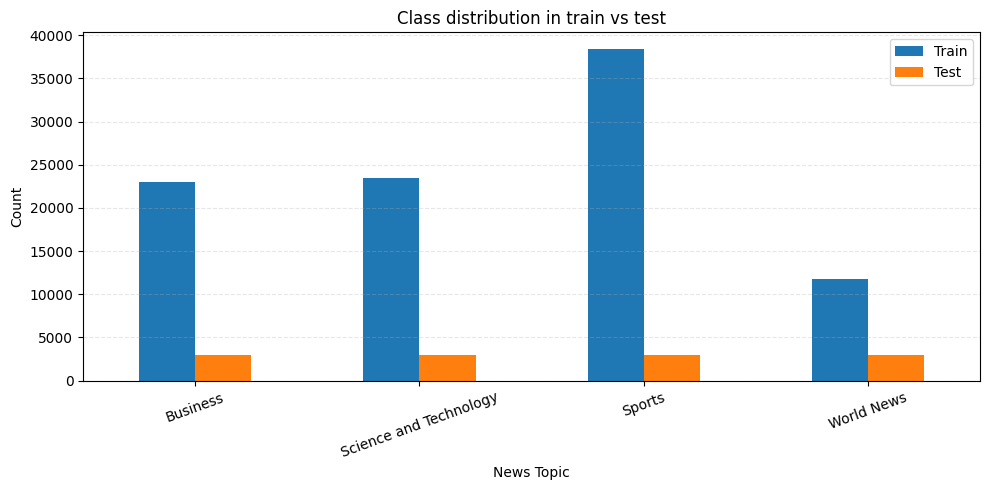

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pd.DataFrame({
    "Train": train_df["News Topic"].value_counts(),
    "Test": test_df["News Topic"].value_counts()
}).fillna(0)

plot_df.plot(kind="bar", ax=ax)
ax.set_title("Class distribution in train vs test")
ax.set_xlabel("News Topic")
ax.set_ylabel("Count")
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Raw sample inspection

In [8]:
sample_view = train_df.sample(5, random_state=SEED)[["News Topic", "News Headline"]]
sample_view

,News Topic,News Headline
24865,Science and Technology,"<html> <body> News Headlines:\n <br> <b> Applied Micro Sees 2Q Revenue Below 1Q Applied Micro Circuits Corp., a communications chip maker, on Thursday said it expects lower second-quarter revenue compared to its first quarter, based on soft sales in Asia and lower orders. </b> \n <br> <br>"
62676,Science and Technology,"<html> <body> News Headlines:\n <br> <b> Nortel to Cut 3,500 Jobs to Boost Profit &lt;p&gt;&lt;/p&gt;&lt;p&gt; OTTAWA (Reuters) - Nortel Networks Corp. &lt;NT.TO&gt; &lt;NT.TO&gt;posted long-awaited preliminary results for the first half of2004 on Thursday, estimating first and second quarter ea..."
923,Business,"<html> <body> News Headlines:\n <br> <b> TiVo and NetFlix: Picture-Perfect Duo? With TiVo (TIVO ) and NetFlix (NFLX ) finally announcing a long-rumored partnership to launch a video-on-demand service sometime next year, investors smiled on the deal that will keep the two popular, but under-fire,..."
52064,World News,<html> <body> News Headlines:\n <br> <b> Wanted Italian leftist on the run Radical 1970s leftist Cesare Battisti - wanted in Italy for murder - goes missing in France. </b> \n <br> <br>
42569,Business,<html> <body> News Headlines:\n <br> <b> Blockbuster axing dreaded late fees Blockbuster is doing away with the most dreaded part of renting movies and games: the late fee. The move comes as Blockbuster battles lackluster demand. </b> \n <br> <br>


## Cleaning helpers for EDA

In [9]:
ENTITY_REPLACEMENTS = {
    r"#39;": "'",
    r"#146;": "'",
    r"quot;": '"',
    r"amp;": "&",
    r"#151;": "-",
    r"#36;": "$",
    r"&lt;": "<",
    r"&gt;": ">"
}

def normalize_artifacts(text):
    text = str(text)
    for pattern, replacement in ENTITY_REPLACEMENTS.items():
        text = re.sub(pattern, replacement, text)
    text = text.replace("\\", " ")
    return text

def basic_eda_clean(text):
    text = normalize_artifacts(text)
    text = BeautifulSoup(text, "html.parser").get_text(" ", strip=True)
    text = html.unescape(text)
    text = re.sub(r"^\s*News Headlines:\s*", "", text, flags=re.I)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for df in [train_df, test_df]:
    df["text_eda"] = df["News Headline"].apply(basic_eda_clean)
    df["char_len"] = df["text_eda"].str.len()
    df["word_len"] = df["text_eda"].str.count(r"\b\w+\b")
    df["has_digit"] = df["text_eda"].str.contains(r"\d")
    df["has_parentheses"] = df["text_eda"].str.contains(r"[()]")
    df["has_hyphen"] = df["text_eda"].str.contains(r"-")
    df["has_quote"] = df["text_eda"].str.contains(r"['\"]")
    df["has_backslash"] = df["News Headline"].str.contains(r"\\")
    df["has_html_tags"] = df["News Headline"].str.contains(r"<html>|<body>|<br>|<b>", regex=True)
    df["has_broken_entities"] = df["News Headline"].str.contains(r"#39;|quot;|amp;|#151;|#36;|&lt;|&gt;", regex=True)
    df["starts_with_news_headlines"] = df["News Headline"].str.contains("News Headlines:", regex=False)

train_df[["News Topic", "text_eda"]].head()

,News Topic,text_eda
0,Sports,"Hill brings magic back to NBA (The Sporting News) The Sporting News - The day after the colossal mess into which his team landed in Detroit, Pacers coach Rick Carlisle paused to say something most in attendance tolerated impatiently. Indiana was preparing to face Orlando, and Carlisle said unpro..."
1,Business,US Treasury 's Snow says health costs impede growth US Treasury Secretary John Snow on Friday is expected to renew his call for Capitol Hill action on President George W. Bush 's health care ideas
2,Sports,"41-year-old QB lifts Toronto to 1st Grey Cup since 1997 OTTAWA - Damon Allen, a 20-year veteran, ran in two touchdowns and passed for another as the Toronto Argonauts defeated the British Columbia Lions 27-19 in the Grey Cup on Sunday night."
3,Business,Mitsubishi chiefs deny cover up The Japanese car maker and three former executives plead not guilty to charges of covering up a truck defect in an official report.
4,Sports,"Buckeyes give Marshall boot COLUMBUS, Ohio -- Mike Nugent's 55-yard field goal as time expired gave ninth-ranked Ohio State a 24-21 victory over Marshall yesterday."


## Data-quality summary

In [10]:
quality_df = pd.DataFrame({
    "metric": [
        "rows",
        "missing_text",
        "missing_label",
        "unique_raw_texts",
        "duplicate_rows",
        "avg_words",
        "median_words",
        "avg_chars",
        "median_chars",
        "has_html_tags_pct",
        "has_broken_entities_pct",
        "has_backslash_pct",
        "starts_with_news_headlines_pct"
    ],
    "train": [
        len(train_df),
        train_df["News Headline"].isna().sum(),
        train_df["News Topic"].isna().sum(),
        train_df["News Headline"].nunique(),
        train_df.duplicated().sum(),
        round(train_df["word_len"].mean(), 2),
        int(train_df["word_len"].median()),
        round(train_df["char_len"].mean(), 2),
        int(train_df["char_len"].median()),
        round(train_df["has_html_tags"].mean() * 100, 2),
        round(train_df["has_broken_entities"].mean() * 100, 2),
        round(train_df["has_backslash"].mean() * 100, 2),
        round(train_df["starts_with_news_headlines"].mean() * 100, 2)
    ],
    "test": [
        len(test_df),
        test_df["News Headline"].isna().sum(),
        test_df["News Topic"].isna().sum(),
        test_df["News Headline"].nunique(),
        test_df.duplicated().sum(),
        round(test_df["word_len"].mean(), 2),
        int(test_df["word_len"].median()),
        round(test_df["char_len"].mean(), 2),
        int(test_df["char_len"].median()),
        round(test_df["has_html_tags"].mean() * 100, 2),
        round(test_df["has_broken_entities"].mean() * 100, 2),
        round(test_df["has_backslash"].mean() * 100, 2),
        round(test_df["starts_with_news_headlines"].mean() * 100, 2)
    ]
})
quality_df

,metric,train,test
0,rows,96646.00,12000.00
1,missing_text,0.00,0.00
2,missing_label,0.00,0.00
3,unique_raw_texts,78715.00,12000.00
4,duplicate_rows,17931.00,0.00
5,avg_words,38.40,38.46
6,median_words,38.00,38.00
7,avg_chars,228.45,230.70
8,median_chars,225.00,229.00
9,has_html_tags_pct,100.00,100.00


## Length and class-wise statistics

In [11]:
length_stats_df = train_df.groupby("News Topic").agg(
    count=("text_eda", "size"),
    avg_words=("word_len", "mean"),
    median_words=("word_len", "median"),
    avg_chars=("char_len", "mean"),
    median_chars=("char_len", "median"),
    digits_pct=("has_digit", "mean"),
    parentheses_pct=("has_parentheses", "mean"),
    hyphen_pct=("has_hyphen", "mean"),
    quote_pct=("has_quote", "mean"),
    broken_entities_pct=("has_broken_entities", "mean")
).reset_index()

for col in length_stats_df.columns:
    if col.endswith("_pct"):
        length_stats_df[col] = (length_stats_df[col] * 100).round(2)
    elif col not in ["News Topic", "count"]:
        length_stats_df[col] = length_stats_df[col].round(2)

length_stats_df

,News Topic,count,avg_words,median_words,avg_chars,median_chars,digits_pct,parentheses_pct,hyphen_pct,quote_pct,broken_entities_pct
0,Business,22993,38.30,38.0,230.84,232.0,50.91,36.01,60.05,42.09,38.29
1,Science and Technology,23487,38.07,37.0,231.68,227.0,38.59,28.56,59.61,43.80,28.67
2,Sports,38421,38.36,37.0,221.45,216.0,52.09,25.81,67.06,48.13,35.64
3,World News,11745,39.35,39.0,240.20,241.0,34.02,34.47,62.93,46.05,25.16


## Word-count distribution

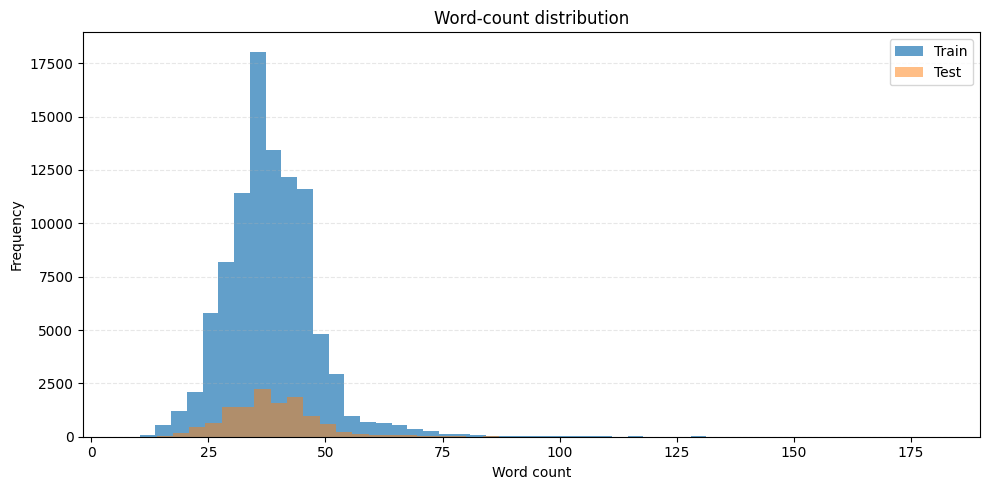

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(train_df["word_len"], bins=50, alpha=0.7, label="Train")
ax.hist(test_df["word_len"], bins=50, alpha=0.5, label="Test")
ax.set_title("Word-count distribution")
ax.set_xlabel("Word count")
ax.set_ylabel("Frequency")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Word-count by class

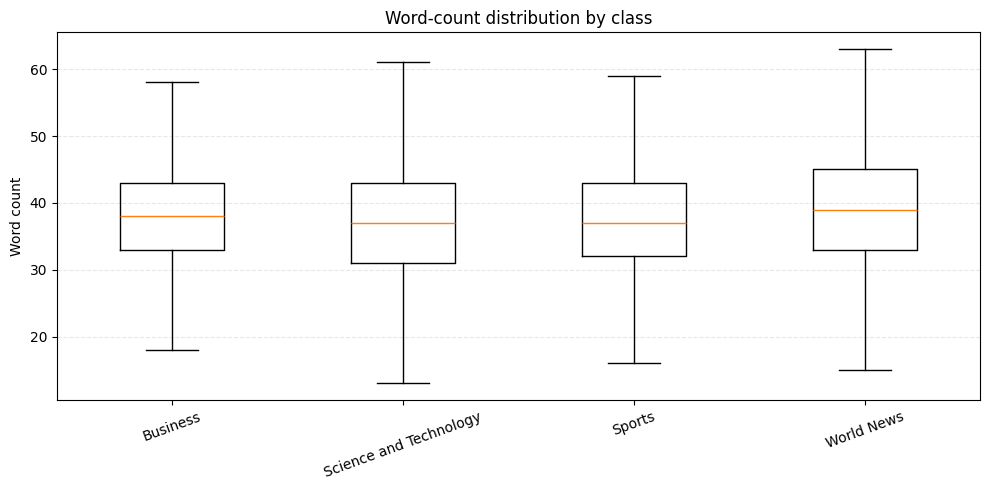

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ordered_topics = sorted(train_df["News Topic"].unique())
box_data = [train_df.loc[train_df["News Topic"] == topic, "word_len"] for topic in ordered_topics]
ax.boxplot(box_data, labels=ordered_topics, showfliers=False)
ax.set_title("Word-count distribution by class")
ax.set_ylabel("Word count")
plt.xticks(rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Source-tag frequency by class

In [14]:
source_df = []
for topic, subset in train_df.groupby("News Topic"):
    source_df.append({
        "News Topic": topic,
        "Reuters_pct": round(subset["text_eda"].str.contains(r"\bReuters\b").mean() * 100, 2),
        "AP_pct": round(subset["text_eda"].str.contains(r"\bAP\b").mean() * 100, 2),
        "AFP_pct": round(subset["text_eda"].str.contains(r"\bAFP\b").mean() * 100, 2)
    })

source_df = pd.DataFrame(source_df)
source_df

,News Topic,Reuters_pct,AP_pct,AFP_pct
0,Business,18.74,0.93,1.11
1,Science and Technology,6.48,6.99,0.72
2,Sports,4.76,10.67,0.56
3,World News,13.71,9.79,6.24


## Most common unigrams after removing source tags

In [15]:
def remove_source_tags(text):
    text = re.sub(r"\((Reuters|AP|AFP)\)", " ", text)
    text = re.sub(r"\b(?:Reuters|AP|AFP)\b\s*[-:)]?", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["text_no_source"] = train_df["text_eda"].apply(remove_source_tags)

def get_top_ngrams(texts, ngram_range=(1, 1), top_n=15):
    vectorizer = CountVectorizer(lowercase=True, stop_words="english", ngram_range=ngram_range, min_df=5)
    matrix = vectorizer.fit_transform(texts)
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    terms = np.array(vectorizer.get_feature_names_out())
    order = counts.argsort()[::-1][:top_n]
    return pd.DataFrame({"term": terms[order], "count": counts[order]})

top_unigrams = {topic: get_top_ngrams(group["text_no_source"], (1, 1), 12) for topic, group in train_df.groupby("News Topic")}
top_bigrams = {topic: get_top_ngrams(group["text_no_source"], (2, 2), 12) for topic, group in train_df.groupby("News Topic")}

top_unigrams["Science and Technology"]

,term,count
0,new,5637
1,microsoft,4055
2,said,2939
3,software,2845
4,internet,2616
5,company,2288
6,space,2084
7,search,1814
8,computer,1775
9,security,1755


## Most common bigrams after removing source tags

In [16]:
top_bigrams["Sports"]

,term,count
0,new york,2156
1,red sox,1802
2,sports network,1602
3,world cup,999
4,ryder cup,721
5,united states,709
6,gold medal,687
7,los angeles,684
8,manchester united,664
9,champions league,624


## Word clouds by class

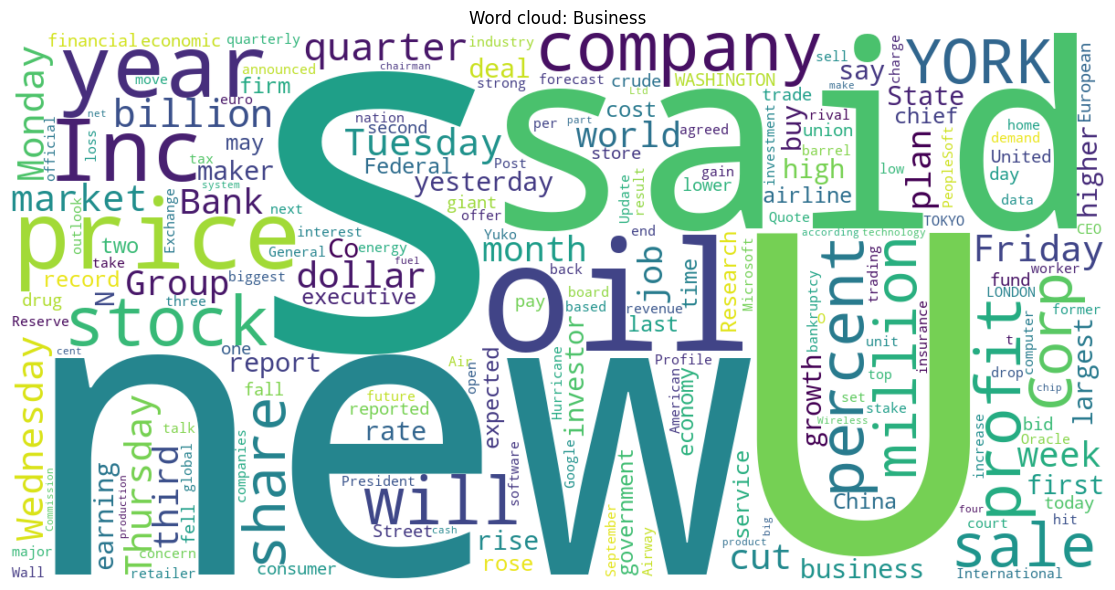

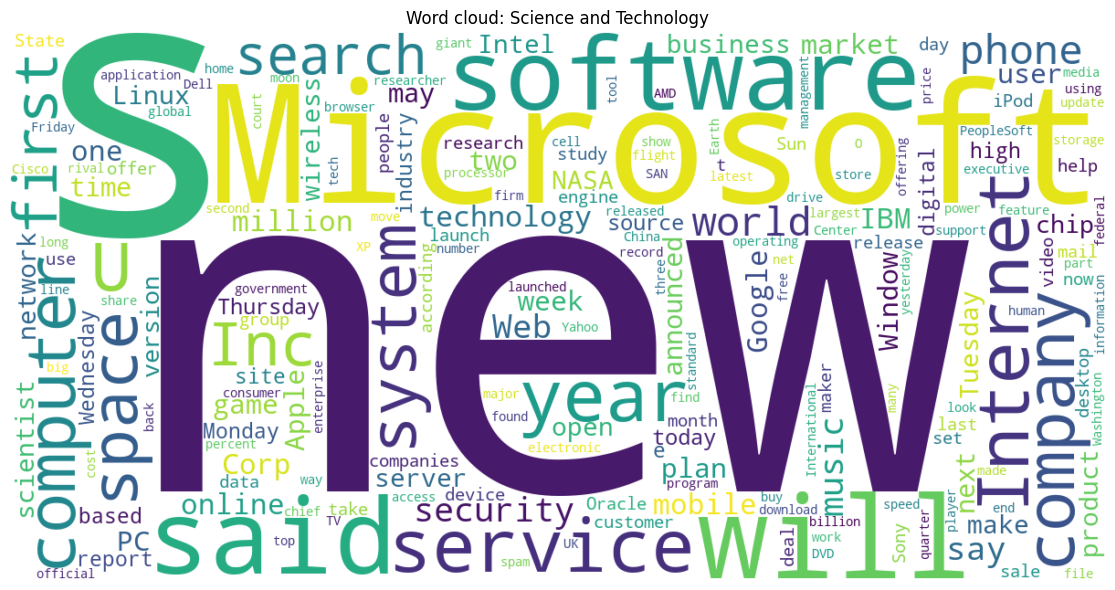

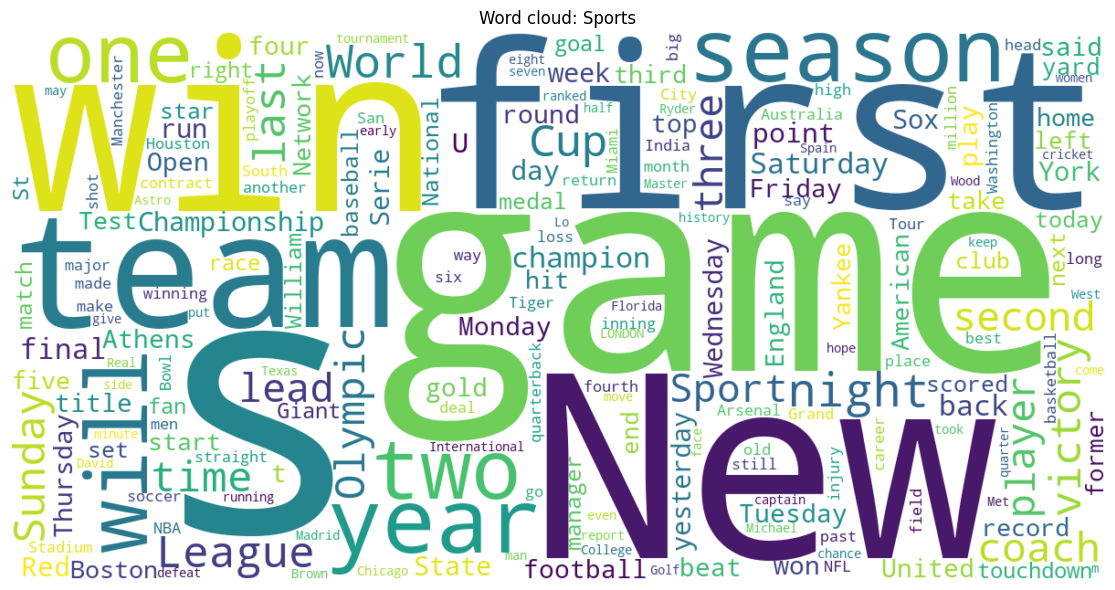

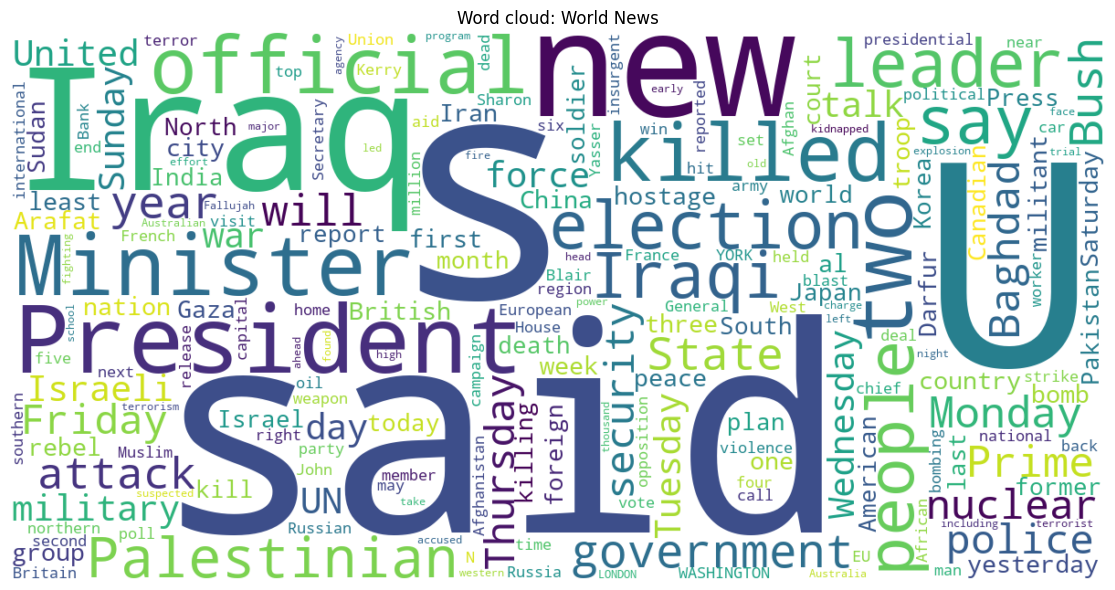

In [17]:
topic_list = sorted(train_df["News Topic"].unique())

for topic in topic_list:
    text_blob = " ".join(train_df.loc[train_df["News Topic"] == topic, "text_no_source"])
    cloud = WordCloud(width=1200, height=600, background_color="white", collocations=False).generate(text_blob)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word cloud: {topic}")
    plt.tight_layout()
    plt.show()

## EDA findings already visible from the dataset

1. The dataset has **96,646 training rows** and **12,000 test rows**, with **4 classes** and **no missing text or label values**.

2. The **training set is imbalanced**:
   - Sports: **39.75%** (38,421 rows)
   - Science and Technology: **24.30%** (23,487 rows)
   - Business: **23.79%** (22,993 rows)
   - World News: **12.15%** (11,745 rows)

   The **test set is perfectly balanced at 25% per class**, so macro F1 and stratified validation matter a lot.

3. Every row contains **HTML wrappers and the constant prefix `News Headlines:`** (100% of both splits). HTML stripping is not optional for the preprocessed versions.

4. About **33.30%** of training rows contain broken HTML-style entities such as `#39;`, `quot;`, `amp;`, or `#151;`.

5. About **10.27%** of training rows contain backslash artifacts like `\said` or `\to`.

6. The texts are **not just short headlines**. After basic cleanup, the training texts average **38.40 words** and **228.45 characters** (median: 38 words, 225 chars), which means they behave more like **headline + short news snippet**.

7. Digits are common across all classes — Sports: **52.09%**, Business: **50.91%**, World News: **34.02%**, Science and Technology: **38.59%**. Removing numbers in the optimum pipeline is a bad idea.

8. Source-wire tags differ by class:
   - Business has the strongest Reuters presence (**18.74%**)
   - Sports has the strongest AP presence (**10.67%**)
   - World News uses a mixture of Reuters (**13.71%**), AP (**9.79%**), and AFP (**6.24%**)

   These publisher-origin markers create a **shortcut signal** that models can exploit without learning genuine topic features, so removing them is a good candidate for the optimum preprocessing pipeline.

9. Exact raw train/test overlap is **0**, and overlap after basic cleanup is still very small (**15 texts**), so data leakage does not appear to be a major concern.


## Build, save, and reload the three preprocessing variants

The notebook saves each preprocessing version as a separate CSV for both train and test:
- `train_none.csv` and `test_none.csv`
- `train_extreme.csv` and `test_extreme.csv`
- `train_optimum.csv` and `test_optimum.csv`

Once these files are created, later runs can load them directly instead of preprocessing the raw text again.


In [18]:
STOP_WORDS = set(ENGLISH_STOP_WORDS)
STEMMER = PorterStemmer()

def preprocess_none(text):
    return str(text)

def preprocess_extreme(text):
    text = basic_eda_clean(text)
    text = re.sub(r"\((Reuters|AP|AFP)\)", " ", text)
    text = re.sub(r"\b(?:Reuters|AP|AFP)\b\s*[-:)]?", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z'\s]", " ", text)
    tokens = re.findall(r"[a-z']+", text)
    tokens = [token for token in tokens if token not in STOP_WORDS and len(token) > 1]
    tokens = [STEMMER.stem(token) for token in tokens]
    return " ".join(tokens)

def preprocess_optimum(text):
    text = basic_eda_clean(text)
    text = re.sub(r"\((Reuters|AP|AFP)\)", " ", text)
    text = re.sub(r"\b(?:Reuters|AP|AFP)\b\s*[-:)]?", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9'\-\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

PREPROCESSORS = {
    "none": preprocess_none,
    "extreme": preprocess_extreme,
    "optimum": preprocess_optimum
}

def build_or_load_preprocessed_frames(source_df, split_name, force=False):
    version_frames = {}
    summary_rows = []

    for version_name, preprocess_fn in PREPROCESSORS.items():
        output_path = get_preprocessed_path(split_name, version_name)

        if output_path.exists() and not force:
            version_df = pd.read_csv(output_path)
            status = "loaded_from_cache"
        else:
            version_df = pd.DataFrame({
                RAW_TEXT_COLUMN: source_df[RAW_TEXT_COLUMN].astype(str),
                TEXT_COLUMN: source_df[RAW_TEXT_COLUMN].astype(str).apply(preprocess_fn)
            })
            if TARGET_COLUMN in source_df.columns:
                version_df[TARGET_COLUMN] = source_df[TARGET_COLUMN].values
                version_df = version_df[[RAW_TEXT_COLUMN, TEXT_COLUMN, TARGET_COLUMN]]
            version_df.to_csv(output_path, index=False)
            status = "built_and_saved"

        version_frames[version_name] = version_df
        summary_rows.append({
            "split": split_name,
            "version": version_name,
            "rows": len(version_df),
            "status": status,
            "path": str(output_path)
        })

    return version_frames, pd.DataFrame(summary_rows)

train_versions_df, train_preprocessed_summary = build_or_load_preprocessed_frames(
    train_df,
    "train",
    force=FORCE_REBUILD_PREPROCESSED
)

test_versions_df, test_preprocessed_summary = build_or_load_preprocessed_frames(
    test_df,
    "test",
    force=FORCE_REBUILD_PREPROCESSED
)

train_versions = {name: frame[TEXT_COLUMN] for name, frame in train_versions_df.items()}
test_versions = {name: frame[TEXT_COLUMN] for name, frame in test_versions_df.items()}

display(pd.concat([train_preprocessed_summary, test_preprocessed_summary], ignore_index=True))

,split,version,rows,status,path
0,train,none,96646,loaded_from_cache,project_cache\preprocessed\train_none.csv
1,train,extreme,96646,loaded_from_cache,project_cache\preprocessed\train_extreme.csv
2,train,optimum,96646,loaded_from_cache,project_cache\preprocessed\train_optimum.csv
3,test,none,12000,loaded_from_cache,project_cache\preprocessed\test_none.csv
4,test,extreme,12000,loaded_from_cache,project_cache\preprocessed\test_extreme.csv
5,test,optimum,12000,loaded_from_cache,project_cache\preprocessed\test_optimum.csv


## Preview the three versions side by side

In [19]:
preview_df = pd.DataFrame({
    "raw": train_df["News Headline"].head(3),
    "no_preprocessing": train_versions["none"].head(3),
    "extreme": train_versions["extreme"].head(3),
    "optimum": train_versions["optimum"].head(3)
})
preview_df

,raw,no_preprocessing,extreme,optimum
0,"<html> <body> News Headlines:\n <br> <b> Hill brings magic back to NBA (The Sporting News) The Sporting News - The day after the colossal mess into which his team landed in Detroit, Pacers coach Rick Carlisle paused to say something most in attendance tolerated impatiently. Indiana was preparing...","<html> <body> News Headlines:\n <br> <b> Hill brings magic back to NBA (The Sporting News) The Sporting News - The day after the colossal mess into which his team landed in Detroit, Pacers coach Rick Carlisle paused to say something most in attendance tolerated impatiently. Indiana was preparing...",hill bring magic nba sport news sport news day coloss mess team land detroit pacer coach rick carlisl paus say attend toler impati indiana prepar face orlando carlisl said unprovok good grant hill import athlet great guy it' great,hill brings magic back to nba the sporting news the sporting news - the day after the colossal mess into which his team landed in detroit pacers coach rick carlisle paused to say something most in attendance tolerated impatiently indiana was preparing to face orlando and carlisle said unprovoked...
1,<html> <body> News Headlines:\n <br> <b> US Treasury #39;s Snow says health costs impede growth US Treasury Secretary John Snow on Friday is expected to renew his call for Capitol Hill action on President George W. Bush #39;s health care ideas </b> \n <br> <br>,<html> <body> News Headlines:\n <br> <b> US Treasury #39;s Snow says health costs impede growth US Treasury Secretary John Snow on Friday is expected to renew his call for Capitol Hill action on President George W. Bush #39;s health care ideas </b> \n <br> <br>,treasuri 's snow say health cost imped growth treasuri secretari john snow friday expect renew capitol hill action presid georg bush 's health care idea,us treasury 's snow says health costs impede growth us treasury secretary john snow on friday is expected to renew his call for capitol hill action on president george w bush 's health care ideas
2,"<html> <body> News Headlines:\n <br> <b> 41-year-old QB lifts Toronto to 1st Grey Cup since 1997 OTTAWA - Damon Allen, a 20-year veteran, ran in two touchdowns and passed for another as the Toronto Argonauts defeated the British Columbia Lions 27-19 in the Grey Cup on Sunday night. </b> \n <br> ...","<html> <body> News Headlines:\n <br> <b> 41-year-old QB lifts Toronto to 1st Grey Cup since 1997 OTTAWA - Damon Allen, a 20-year veteran, ran in two touchdowns and passed for another as the Toronto Argonauts defeated the British Columbia Lions 27-19 in the Grey Cup on Sunday night. </b> \n <br> ...",year old qb lift toronto st grey cup ottawa damon allen year veteran ran touchdown pass toronto argonaut defeat british columbia lion grey cup sunday night,41-year-old qb lifts toronto to 1st grey cup since 1997 ottawa - damon allen a 20-year veteran ran in two touchdowns and passed for another as the toronto argonauts defeated the british columbia lions 27-19 in the grey cup on sunday night


## One reproducible validation split with duplicate-aware grouping

Because the training data contains many exact duplicates, the split is created at group level using normalized raw text. This prevents the same duplicated headline from appearing in both training and validation.

The split is saved once and reused by every model and preprocessing version.


In [20]:
label_encoder = LabelEncoder()
label_encoder.fit(train_df[TARGET_COLUMN])

def make_group_key(text):
    text = basic_eda_clean(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["group_key"] = train_df[RAW_TEXT_COLUMN].apply(make_group_key)

def build_or_load_group_split(df, test_size=0.15, force=False):
    split_path = get_split_path(test_size)

    if split_path.exists() and not force:
        split_df = pd.read_csv(split_path)
    else:
        group_df = df[[TARGET_COLUMN, "group_key"]].drop_duplicates("group_key").copy()
        train_groups, val_groups = train_test_split(
            group_df["group_key"],
            test_size=test_size,
            random_state=SEED,
            stratify=group_df[TARGET_COLUMN]
        )

        split_df = pd.DataFrame({
            "group_key": list(train_groups) + list(val_groups),
            "split": ["train"] * len(train_groups) + ["val"] * len(val_groups)
        })
        split_df.to_csv(split_path, index=False)

    return split_df

split_map_df = build_or_load_group_split(train_df, test_size=0.15, force=FORCE_NEW_SPLIT)
split_lookup = dict(zip(split_map_df["group_key"], split_map_df["split"]))

def make_split(text_series, label_series, group_keys=None):
    if group_keys is None:
        group_keys = train_df["group_key"]

    split_df = pd.DataFrame({
        TEXT_COLUMN: list(text_series),
        TARGET_COLUMN: list(label_series),
        "group_key": list(group_keys)
    })

    split_df["split"] = split_df["group_key"].map(split_lookup)

    train_part = split_df[split_df["split"] == "train"].copy()
    val_part = split_df[split_df["split"] == "val"].copy()

    X_train = train_part[TEXT_COLUMN].reset_index(drop=True)
    X_val = val_part[TEXT_COLUMN].reset_index(drop=True)
    y_train = train_part[TARGET_COLUMN].reset_index(drop=True)
    y_val = val_part[TARGET_COLUMN].reset_index(drop=True)

    y_train_enc = label_encoder.transform(y_train)
    y_val_enc = label_encoder.transform(y_val)

    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_train_enc),
        y=y_train_enc
    )
    class_weight_dict = {i: class_weights_array[i] for i in range(len(class_weights_array))}
    return X_train, X_val, y_train, y_val, y_train_enc, y_val_enc, class_weight_dict

split_overview = train_df["group_key"].map(split_lookup).value_counts().rename_axis("split").reset_index(name="rows")
display(split_overview)

X_train_opt, X_val_opt, y_train_opt, y_val_opt, y_train_opt_enc, y_val_opt_enc, class_weights_opt = make_split(
    train_versions["optimum"],
    train_df[TARGET_COLUMN],
    train_df["group_key"]
)

print(X_train_opt.shape, X_val_opt.shape)
print(class_weights_opt)

,split,rows
0,train,82240
1,val,14406


(82240,) (14406,)
{0: np.float64(1.052200614124872), 1: np.float64(1.0295958736040864), 2: np.float64(0.6278054291734099), 3: np.float64(2.059707473452214)}


## Evaluation helpers

In [21]:
EXPERIMENT_LOG = []

def evaluate_predictions(y_true, y_pred, labels):
    report_dict = classification_report(y_true, y_pred, output_dict=True)
    report_df = pd.DataFrame(report_dict).T
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }
    return metrics, report_df

def show_confusion(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(7, 7))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def log_result(preprocessing_name, representation, model_name, split_name, metrics, params):
    EXPERIMENT_LOG.append({
        "preprocessing": preprocessing_name,
        "representation": representation,
        "model": model_name,
        "split": split_name,
        "accuracy": round(metrics["accuracy"], 4),
        "macro_f1": round(metrics["macro_f1"], 4),
        "params": params
    })

## Tuning log helper

In [22]:
TUNING_LOG = []

def log_tuning(stage, preprocessing_name, model_name, params, val_accuracy, val_macro_f1, notes=""):
    TUNING_LOG.append({
        "stage": stage,
        "preprocessing": preprocessing_name,
        "model": model_name,
        "params": str(params),
        "val_accuracy": round(val_accuracy, 4),
        "val_macro_f1": round(val_macro_f1, 4),
        "notes": notes
    })

def tuning_table():
    return pd.DataFrame(TUNING_LOG).sort_values(["stage", "val_macro_f1"], ascending=[True, False])

## TF-IDF feature helper

In [23]:
def build_tfidf_features(preprocessing_name, X_train, X_val, max_features=50000, ngram_range=(1, 2), min_df=3, max_df=0.95):
    params = {
        "max_features": max_features,
        "ngram_range": ngram_range,
        "min_df": min_df,
        "max_df": max_df
    }
    signature = params_signature(params)
    cache_dir = TFIDF_DIR / f"{preprocessing_name}_tfidf_{signature}"
    vectorizer_path = cache_dir / "vectorizer.pkl"
    X_train_path = cache_dir / "X_train_tfidf.npz"
    X_val_path = cache_dir / "X_val_tfidf.npz"

    if vectorizer_path.exists() and X_train_path.exists() and X_val_path.exists() and not FORCE_REBUILD_FEATURES:
        vectorizer = load_pickle(vectorizer_path)
        X_train_tfidf = load_npz(X_train_path)
        X_val_tfidf = load_npz(X_val_path)
    else:
        cache_dir.mkdir(parents=True, exist_ok=True)
        vectorizer = TfidfVectorizer(
            max_features=max_features,
            ngram_range=ngram_range,
            min_df=min_df,
            max_df=max_df,
            sublinear_tf=True
        )
        X_train_tfidf = vectorizer.fit_transform(X_train)
        X_val_tfidf = vectorizer.transform(X_val)
        save_pickle(vectorizer, vectorizer_path)
        save_npz(X_train_path, X_train_tfidf)
        save_npz(X_val_path, X_val_tfidf)

    return vectorizer, X_train_tfidf, X_val_tfidf

## TF-IDF with Logistic Regression

In [24]:
def run_logistic_regression(preprocessing_name, train_text, train_labels, class_weight="balanced", C=3.0, max_iter=1500):
    X_train, X_val, y_train, y_val, y_train_enc, y_val_enc, _ = make_split(train_text, train_labels, train_df["group_key"])
    vectorizer, X_train_tfidf, X_val_tfidf = build_tfidf_features(
        preprocessing_name,
        X_train,
        X_val,
        max_features=40000,
        ngram_range=(1, 2),
        min_df=3
    )

    model = LogisticRegression(
        C=C,
        max_iter=max_iter,
        class_weight=class_weight
    )
    model.fit(X_train_tfidf, y_train)
    val_pred = model.predict(X_val_tfidf)

    metrics, report_df = evaluate_predictions(y_val, val_pred, label_encoder.classes_)
    log_result(preprocessing_name, "TF-IDF", "LogisticRegression", "validation", metrics, {"C": C, "class_weight": class_weight})
    log_tuning("TF-IDF_ML", preprocessing_name, "LogisticRegression", {"C": C, "class_weight": class_weight}, metrics["accuracy"], metrics["macro_f1"])

    print(metrics)
    display(report_df)
    show_confusion(y_val, val_pred, label_encoder.classes_, f"Logistic Regression | {preprocessing_name}")
    return model, vectorizer, metrics, report_df

## Run Logistic Regression on all three preprocessing variants

Running Logistic Regression for preprocessing: none
Training with C=1.0, max_iter=500
{'accuracy': 0.9276690267943912, 'macro_f1': 0.9140087151636911}


,precision,recall,f1-score,support
Business,0.906250,0.881842,0.893879,3453.000000
Science and Technology,0.893659,0.905344,0.899463,3518.000000
Sports,0.978532,0.980430,0.979480,5672.000000
World News,0.874375,0.892229,0.883212,1763.000000
accuracy,0.927669,0.927669,0.927669,0.927669
macro avg,0.913204,0.914961,0.914009,14406.000000
weighted avg,0.927734,0.927669,0.927641,14406.000000


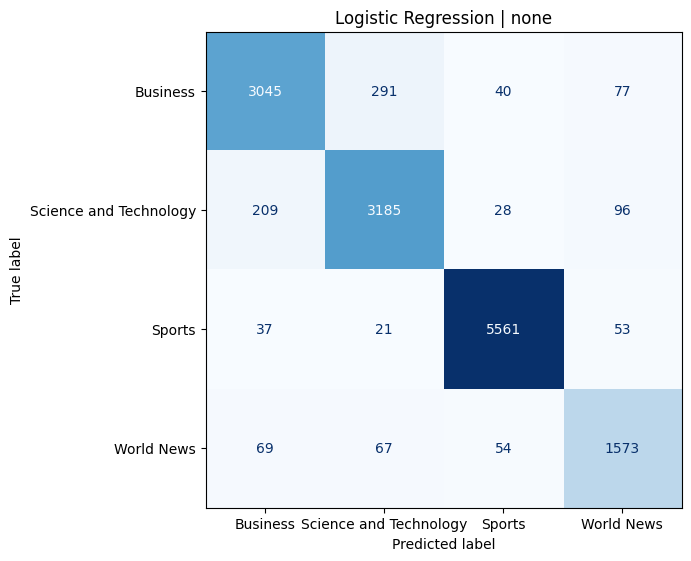

Training with C=1.0, max_iter=1500
{'accuracy': 0.9276690267943912, 'macro_f1': 0.9140087151636911}


,precision,recall,f1-score,support
Business,0.906250,0.881842,0.893879,3453.000000
Science and Technology,0.893659,0.905344,0.899463,3518.000000
Sports,0.978532,0.980430,0.979480,5672.000000
World News,0.874375,0.892229,0.883212,1763.000000
accuracy,0.927669,0.927669,0.927669,0.927669
macro avg,0.913204,0.914961,0.914009,14406.000000
weighted avg,0.927734,0.927669,0.927641,14406.000000


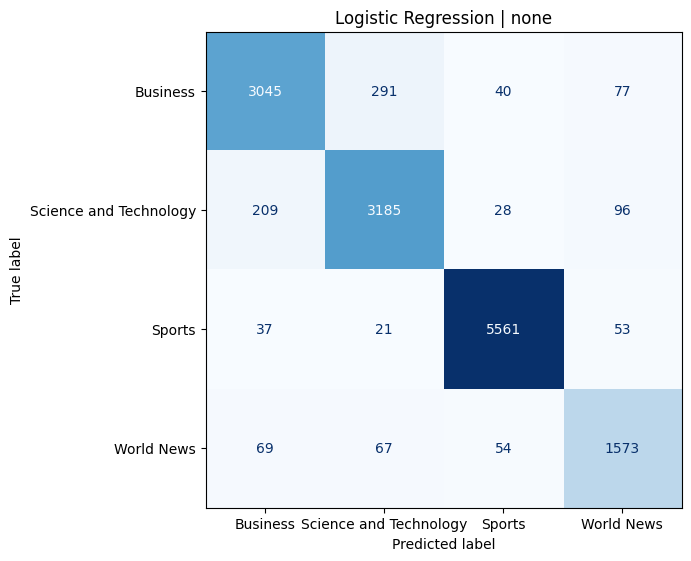

Training with C=3.0, max_iter=500
{'accuracy': 0.9286408440927392, 'macro_f1': 0.9149751081967439}


,precision,recall,f1-score,support
Business,0.904973,0.885317,0.895037,3453.000000
Science and Technology,0.892997,0.906197,0.899549,3518.000000
Sports,0.980786,0.980959,0.980873,5672.000000
World News,0.878992,0.889960,0.884442,1763.000000
accuracy,0.928641,0.928641,0.928641,0.928641
macro avg,0.914437,0.915608,0.914975,14406.000000
weighted avg,0.928718,0.928641,0.928638,14406.000000


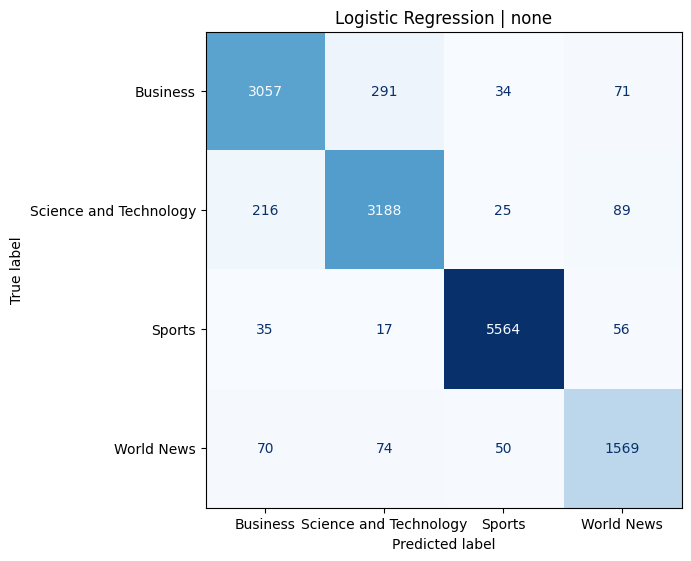

Training with C=3.0, max_iter=1500
{'accuracy': 0.9286408440927392, 'macro_f1': 0.9149751081967439}


,precision,recall,f1-score,support
Business,0.904973,0.885317,0.895037,3453.000000
Science and Technology,0.892997,0.906197,0.899549,3518.000000
Sports,0.980786,0.980959,0.980873,5672.000000
World News,0.878992,0.889960,0.884442,1763.000000
accuracy,0.928641,0.928641,0.928641,0.928641
macro avg,0.914437,0.915608,0.914975,14406.000000
weighted avg,0.928718,0.928641,0.928638,14406.000000


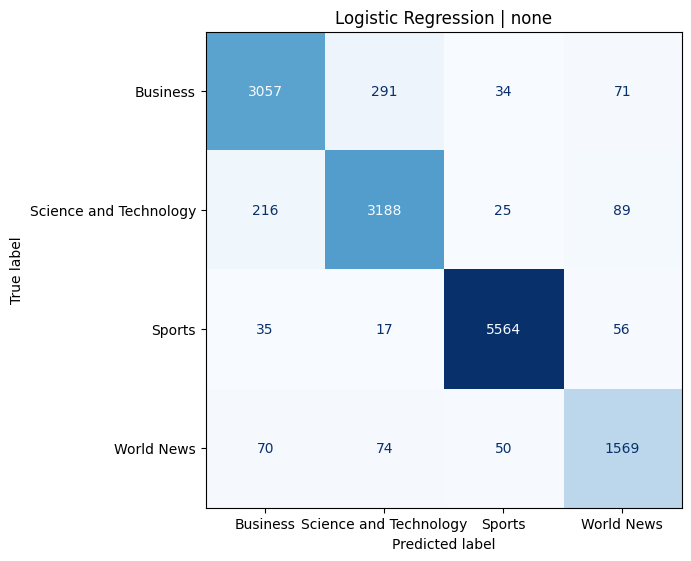

Training with C=5.0, max_iter=500
{'accuracy': 0.9262807163681799, 'macro_f1': 0.9119184452842803}


,precision,recall,f1-score,support
Business,0.900888,0.881842,0.891263,3453.000000
Science and Technology,0.891846,0.904775,0.898264,3518.000000
Sports,0.981095,0.979020,0.980056,5672.000000
World News,0.869783,0.886557,0.878090,1763.000000
accuracy,0.926281,0.926281,0.926281,0.926281
macro avg,0.910903,0.913049,0.911918,14406.000000
weighted avg,0.926453,0.926281,0.926321,14406.000000


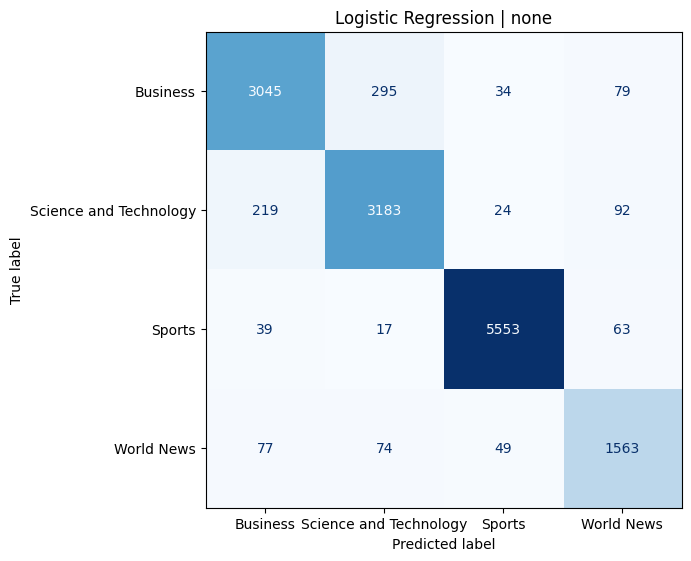

Training with C=5.0, max_iter=1500
{'accuracy': 0.9262807163681799, 'macro_f1': 0.9119184452842803}


,precision,recall,f1-score,support
Business,0.900888,0.881842,0.891263,3453.000000
Science and Technology,0.891846,0.904775,0.898264,3518.000000
Sports,0.981095,0.979020,0.980056,5672.000000
World News,0.869783,0.886557,0.878090,1763.000000
accuracy,0.926281,0.926281,0.926281,0.926281
macro avg,0.910903,0.913049,0.911918,14406.000000
weighted avg,0.926453,0.926281,0.926321,14406.000000


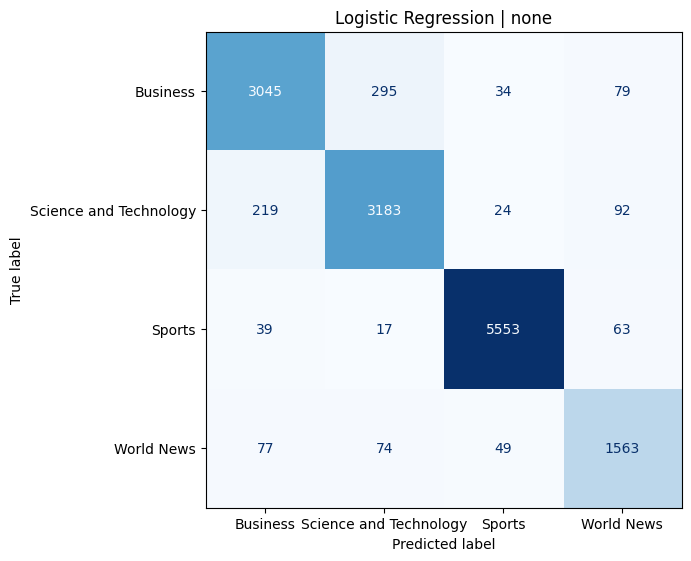

Best Run for none: C=3.0, max_iter=500, Accuracy=0.9286408440927392
Running Logistic Regression for preprocessing: extreme
Training with C=1.0, max_iter=500
{'accuracy': 0.9230876023878939, 'macro_f1': 0.9080585267870833}


,precision,recall,f1-score,support
Business,0.896950,0.877208,0.886969,3453.000000
Science and Technology,0.890051,0.895111,0.892574,3518.000000
Sports,0.980403,0.979020,0.979711,5672.000000
World News,0.857690,0.888826,0.872981,1763.000000
accuracy,0.923088,0.923088,0.923088,0.923088
macro avg,0.906273,0.910041,0.908059,14406.000000
weighted avg,0.923318,0.923088,0.923141,14406.000000


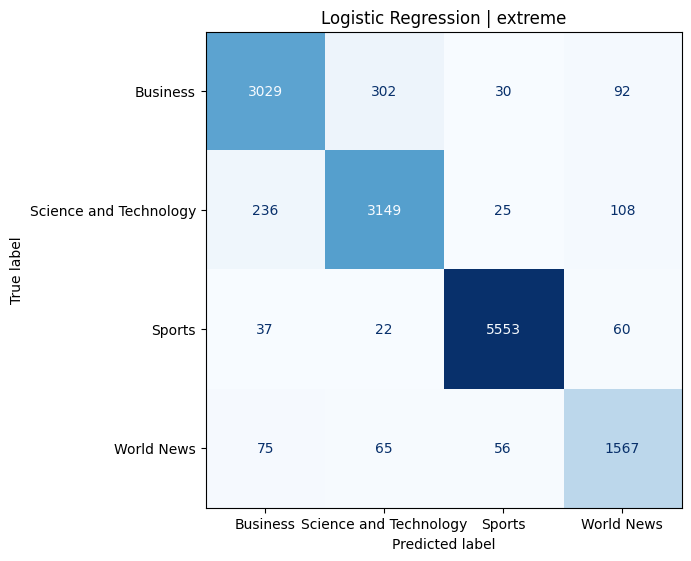

Training with C=1.0, max_iter=1500
{'accuracy': 0.9230876023878939, 'macro_f1': 0.9080585267870833}


,precision,recall,f1-score,support
Business,0.896950,0.877208,0.886969,3453.000000
Science and Technology,0.890051,0.895111,0.892574,3518.000000
Sports,0.980403,0.979020,0.979711,5672.000000
World News,0.857690,0.888826,0.872981,1763.000000
accuracy,0.923088,0.923088,0.923088,0.923088
macro avg,0.906273,0.910041,0.908059,14406.000000
weighted avg,0.923318,0.923088,0.923141,14406.000000


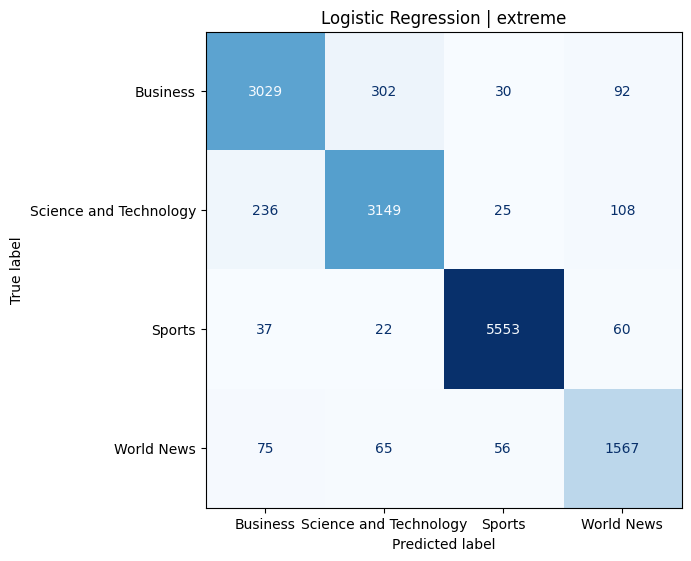

Training with C=3.0, max_iter=500
{'accuracy': 0.9224628626960989, 'macro_f1': 0.9071777946755524}


,precision,recall,f1-score,support
Business,0.891605,0.876629,0.884054,3453.000000
Science and Technology,0.889172,0.893974,0.891566,3518.000000
Sports,0.981459,0.979901,0.980679,5672.000000
World News,0.860850,0.884288,0.872412,1763.000000
accuracy,0.922463,0.922463,0.922463,0.922463
macro avg,0.905771,0.908698,0.907178,14406.000000
weighted avg,0.922625,0.922463,0.922507,14406.000000


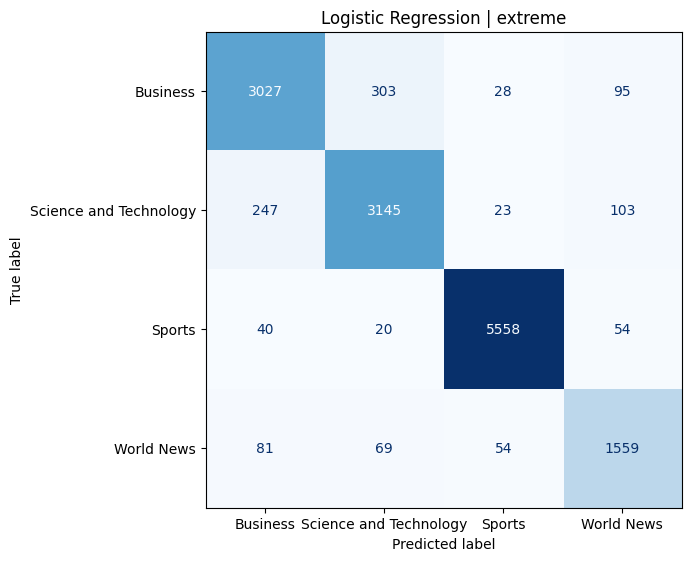

Training with C=3.0, max_iter=1500
{'accuracy': 0.9224628626960989, 'macro_f1': 0.9071777946755524}


,precision,recall,f1-score,support
Business,0.891605,0.876629,0.884054,3453.000000
Science and Technology,0.889172,0.893974,0.891566,3518.000000
Sports,0.981459,0.979901,0.980679,5672.000000
World News,0.860850,0.884288,0.872412,1763.000000
accuracy,0.922463,0.922463,0.922463,0.922463
macro avg,0.905771,0.908698,0.907178,14406.000000
weighted avg,0.922625,0.922463,0.922507,14406.000000


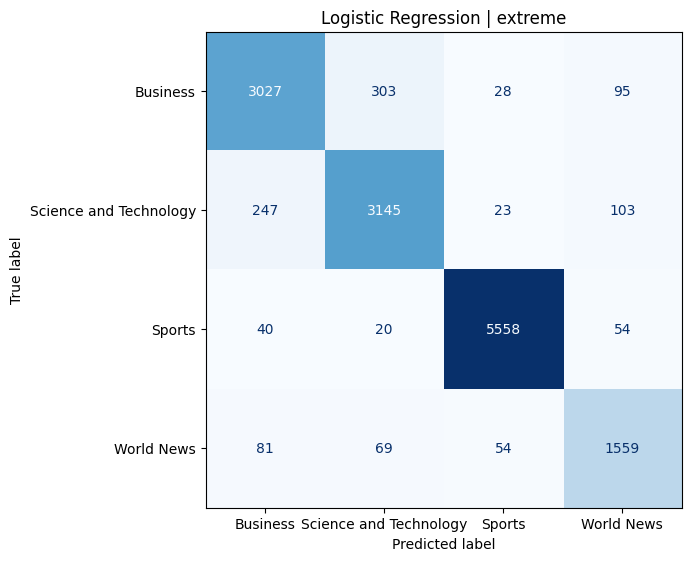

Training with C=5.0, max_iter=500
{'accuracy': 0.9230876023878939, 'macro_f1': 0.9078808791747532}


,precision,recall,f1-score,support
Business,0.890391,0.877498,0.883897,3453.000000
Science and Technology,0.890303,0.895111,0.892700,3518.000000
Sports,0.982332,0.980254,0.981292,5672.000000
World News,0.863234,0.884288,0.873634,1763.000000
accuracy,0.923088,0.923088,0.923088,0.923088
macro avg,0.906565,0.909288,0.907881,14406.000000
weighted avg,0.923245,0.923088,0.923138,14406.000000


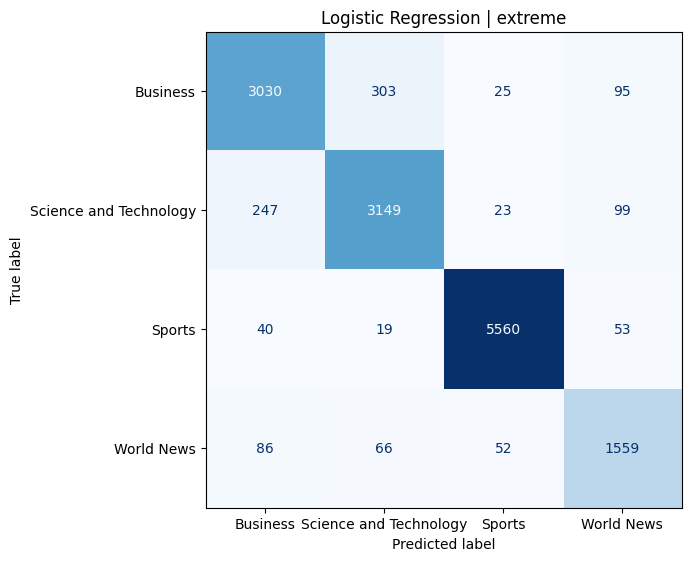

Training with C=5.0, max_iter=1500
{'accuracy': 0.9230876023878939, 'macro_f1': 0.9078808791747532}


,precision,recall,f1-score,support
Business,0.890391,0.877498,0.883897,3453.000000
Science and Technology,0.890303,0.895111,0.892700,3518.000000
Sports,0.982332,0.980254,0.981292,5672.000000
World News,0.863234,0.884288,0.873634,1763.000000
accuracy,0.923088,0.923088,0.923088,0.923088
macro avg,0.906565,0.909288,0.907881,14406.000000
weighted avg,0.923245,0.923088,0.923138,14406.000000


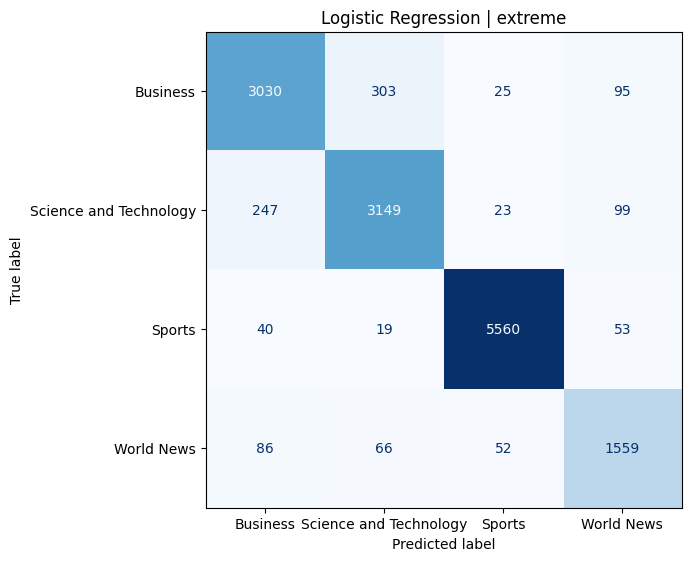

Best Run for extreme: C=1.0, max_iter=500, Accuracy=0.9230876023878939
Running Logistic Regression for preprocessing: optimum
Training with C=1.0, max_iter=500
{'accuracy': 0.923226433430515, 'macro_f1': 0.9088318776563715}


,precision,recall,f1-score,support
Business,0.896552,0.873443,0.884847,3453.000000
Science and Technology,0.887265,0.897101,0.892155,3518.000000
Sports,0.977860,0.981135,0.979495,5672.000000
World News,0.871237,0.886557,0.878830,1763.000000
accuracy,0.923226,0.923226,0.923226,0.923226
macro avg,0.908228,0.909559,0.908832,14406.000000
weighted avg,0.923199,0.923226,0.923161,14406.000000


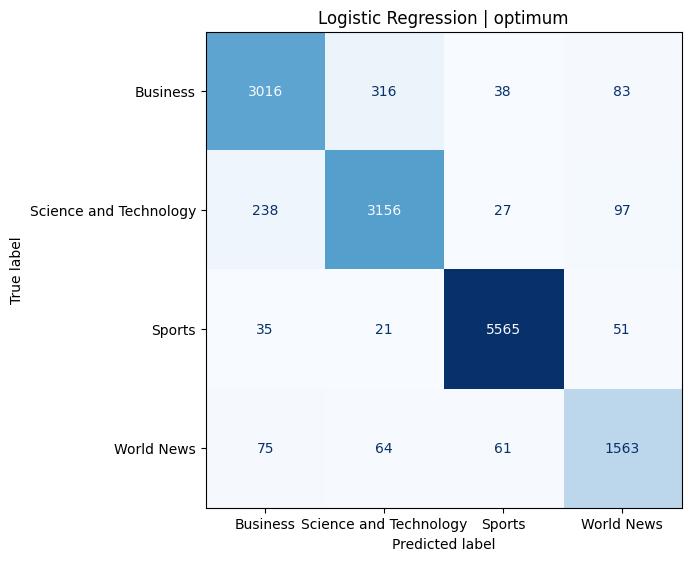

Training with C=1.0, max_iter=1500
{'accuracy': 0.923226433430515, 'macro_f1': 0.9088318776563715}


,precision,recall,f1-score,support
Business,0.896552,0.873443,0.884847,3453.000000
Science and Technology,0.887265,0.897101,0.892155,3518.000000
Sports,0.977860,0.981135,0.979495,5672.000000
World News,0.871237,0.886557,0.878830,1763.000000
accuracy,0.923226,0.923226,0.923226,0.923226
macro avg,0.908228,0.909559,0.908832,14406.000000
weighted avg,0.923199,0.923226,0.923161,14406.000000


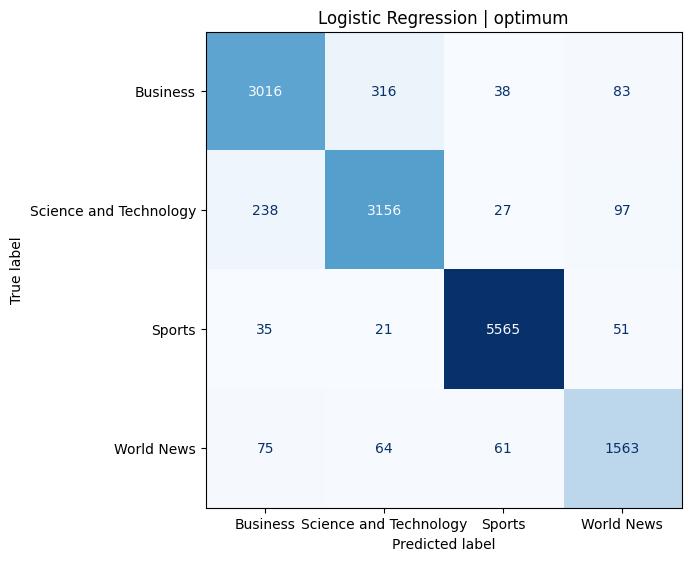

Training with C=3.0, max_iter=500
{'accuracy': 0.9223934471747883, 'macro_f1': 0.9078456177467026}


,precision,recall,f1-score,support
Business,0.891445,0.875181,0.883238,3453.000000
Science and Technology,0.886517,0.897101,0.891777,3518.000000
Sports,0.979880,0.978843,0.979361,5672.000000
World News,0.870391,0.883721,0.877005,1763.000000
accuracy,0.922393,0.922393,0.922393,0.922393
macro avg,0.907058,0.908711,0.907846,14406.000000
weighted avg,0.922484,0.922393,0.922407,14406.000000


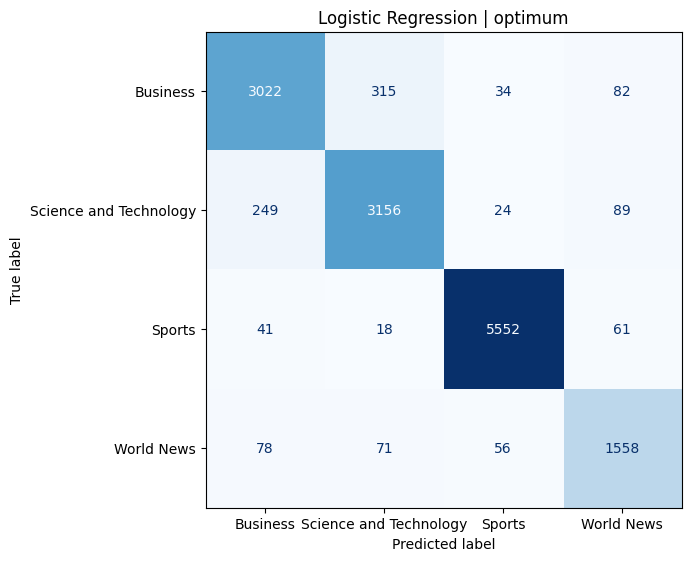

Training with C=3.0, max_iter=1500
{'accuracy': 0.9223934471747883, 'macro_f1': 0.9078456177467026}


,precision,recall,f1-score,support
Business,0.891445,0.875181,0.883238,3453.000000
Science and Technology,0.886517,0.897101,0.891777,3518.000000
Sports,0.979880,0.978843,0.979361,5672.000000
World News,0.870391,0.883721,0.877005,1763.000000
accuracy,0.922393,0.922393,0.922393,0.922393
macro avg,0.907058,0.908711,0.907846,14406.000000
weighted avg,0.922484,0.922393,0.922407,14406.000000


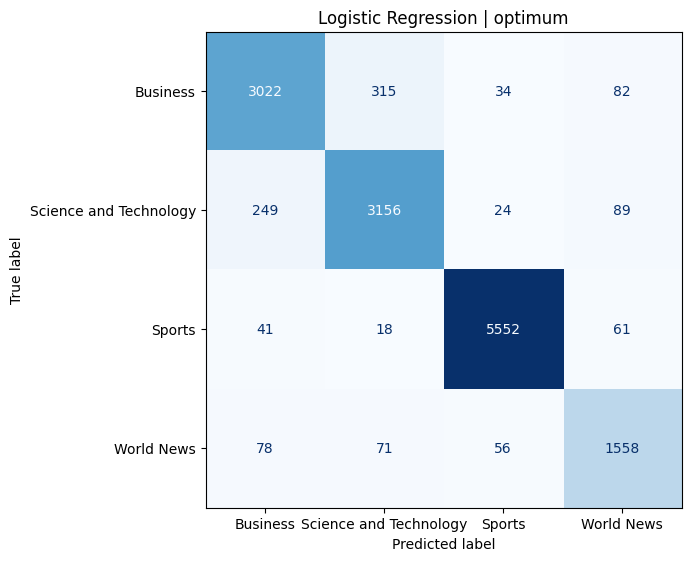

Training with C=5.0, max_iter=500
{'accuracy': 0.9209357212272664, 'macro_f1': 0.9061227081529322}


,precision,recall,f1-score,support
Business,0.889283,0.872285,0.880702,3453.000000
Science and Technology,0.885122,0.897953,0.891491,3518.000000
Sports,0.980014,0.976904,0.978457,5672.000000
World News,0.865813,0.882019,0.873841,1763.000000
accuracy,0.920936,0.920936,0.920936,0.920936
macro avg,0.905058,0.907290,0.906123,14406.000000
weighted avg,0.921118,0.920936,0.920986,14406.000000


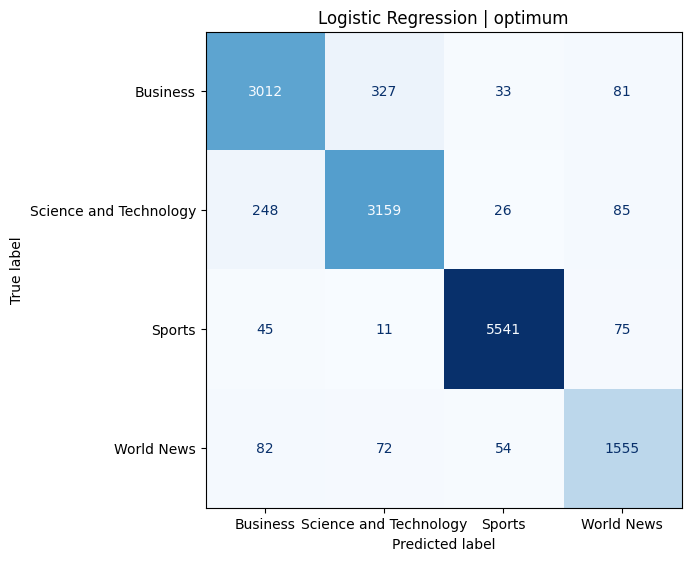

Training with C=5.0, max_iter=1500
{'accuracy': 0.9209357212272664, 'macro_f1': 0.9061227081529322}


,precision,recall,f1-score,support
Business,0.889283,0.872285,0.880702,3453.000000
Science and Technology,0.885122,0.897953,0.891491,3518.000000
Sports,0.980014,0.976904,0.978457,5672.000000
World News,0.865813,0.882019,0.873841,1763.000000
accuracy,0.920936,0.920936,0.920936,0.920936
macro avg,0.905058,0.907290,0.906123,14406.000000
weighted avg,0.921118,0.920936,0.920986,14406.000000


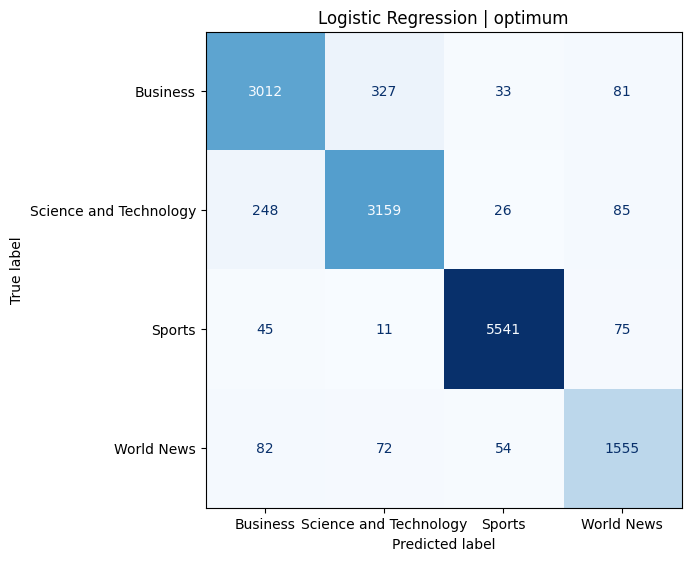

Best Run for optimum: C=1.0, max_iter=500, Accuracy=0.923226433430515
Evaluating best Logistic Regression model for preprocessing: none
Validation Metrics for none:
{'accuracy': 0.9224628626960989, 'macro_f1': 0.9078870489679438}


,precision,recall,f1-score,support
Business,0.890791,0.874023,0.882327,3453.000000
Science and Technology,0.886491,0.899090,0.892746,3518.000000
Sports,0.981593,0.977786,0.979686,5672.000000
World News,0.867778,0.885990,0.876789,1763.000000
accuracy,0.922463,0.922463,0.922463,0.922463
macro avg,0.906663,0.909222,0.907887,14406.000000
weighted avg,0.922676,0.922463,0.922526,14406.000000


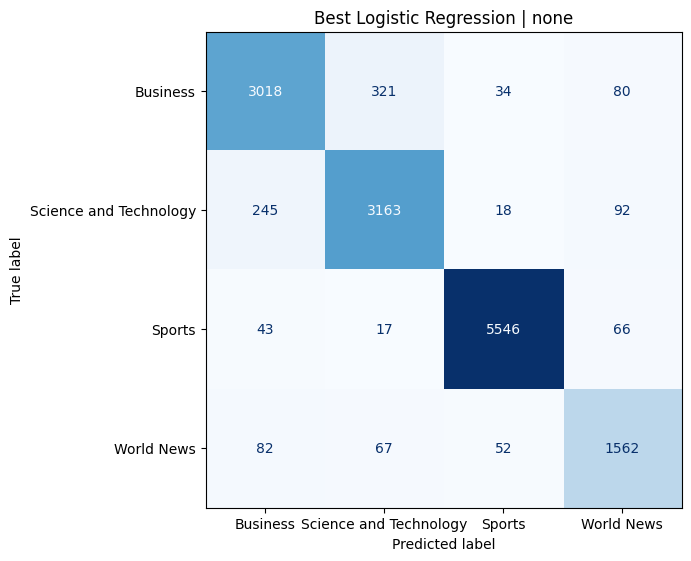

Evaluating best Logistic Regression model for preprocessing: extreme
Validation Metrics for extreme:
{'accuracy': 0.8785228377065112, 'macro_f1': 0.8586851688927363}


,precision,recall,f1-score,support
Business,0.840522,0.801332,0.820460,3453.000000
Science and Technology,0.825837,0.855884,0.840592,3518.000000
Sports,0.937553,0.968794,0.952918,5672.000000
World News,0.860610,0.784458,0.820772,1763.000000
accuracy,0.878523,0.878523,0.878523,0.878523
macro avg,0.866131,0.852617,0.858685,14406.000000
weighted avg,0.877598,0.878523,0.877566,14406.000000


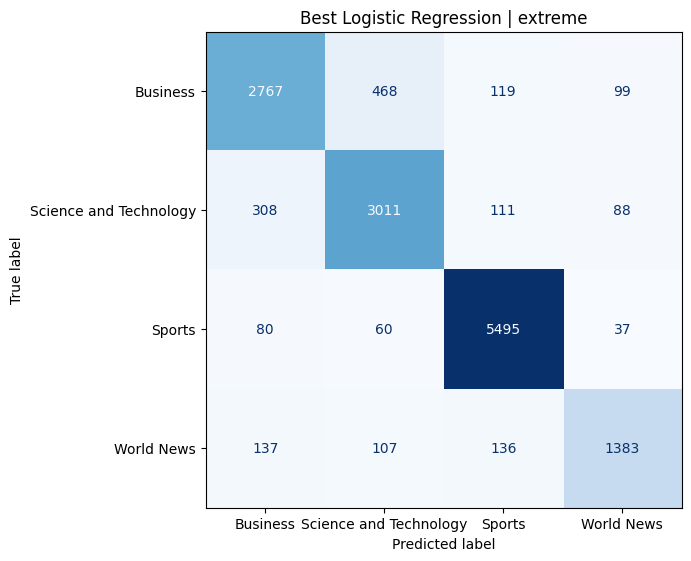

Evaluating best Logistic Regression model for preprocessing: optimum
Validation Metrics for optimum:
{'accuracy': 0.923226433430515, 'macro_f1': 0.9088318776563715}


,precision,recall,f1-score,support
Business,0.896552,0.873443,0.884847,3453.000000
Science and Technology,0.887265,0.897101,0.892155,3518.000000
Sports,0.977860,0.981135,0.979495,5672.000000
World News,0.871237,0.886557,0.878830,1763.000000
accuracy,0.923226,0.923226,0.923226,0.923226
macro avg,0.908228,0.909559,0.908832,14406.000000
weighted avg,0.923199,0.923226,0.923161,14406.000000


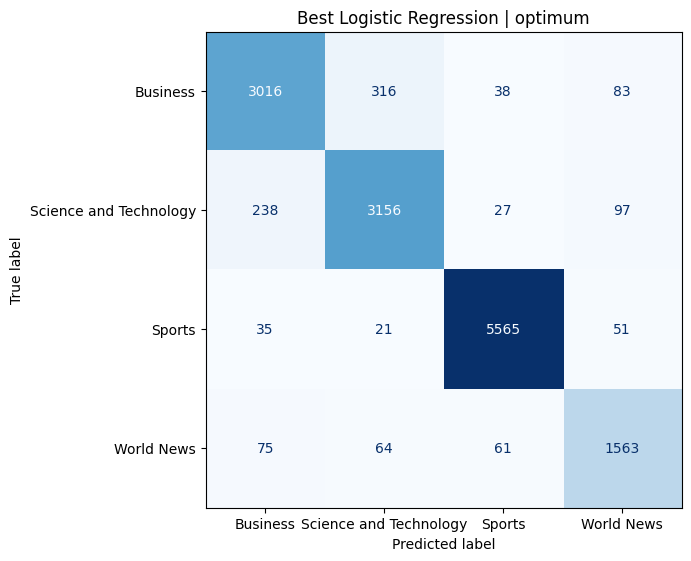

In [25]:
hyperparameters_lr = {
    'C': [1.0, 3.0, 5.0],
    'max_iter': [500, 1500],  
}

best_runs = {}

for preprocessing_name in ["none", "extreme", "optimum"]:
    print("=" * 80)
    print(f"Running Logistic Regression for preprocessing: {preprocessing_name}")
    
    best_accuracy = -float('inf') 
    best_run = None  
    
    for C, max_iter in itertools.product(hyperparameters_lr['C'], hyperparameters_lr['max_iter']):
        print(f"Training with C={C}, max_iter={max_iter}")

        model, vectorizer, metrics, report_df = run_logistic_regression(
            preprocessing_name,
            train_versions[preprocessing_name],
            train_df["News Topic"],  
            class_weight="balanced", 
            C=C,
            max_iter=max_iter
        )

        if metrics['accuracy'] > best_accuracy:
            best_accuracy = metrics['accuracy']
            best_run = {
                'preprocessing': preprocessing_name,
                'C': C,
                'max_iter': max_iter,
                'accuracy': metrics['accuracy'],
                'macro_f1': metrics['macro_f1'],
                'model': model, 
                'vectorizer': vectorizer
            }
    best_runs[preprocessing_name] = best_run
    
    print(f"Best Run for {preprocessing_name}: C={best_run['C']}, max_iter={best_run['max_iter']}, Accuracy={best_run['accuracy']}")

for preprocessing_name, run_info in best_runs.items():
    print(f"Evaluating best Logistic Regression model for preprocessing: {preprocessing_name}")
    model = run_info['model']
    vectorizer = run_info['vectorizer']

    X_val = vectorizer.transform(X_val_opt)
    val_pred = model.predict(X_val)

    metrics, report_df = evaluate_predictions(y_val_opt, val_pred, label_encoder.classes_)
    print(f"Validation Metrics for {preprocessing_name}:")
    print(metrics)
    display(report_df)
    show_confusion(y_val_opt, val_pred, label_encoder.classes_, f"Best Logistic Regression | {preprocessing_name}")

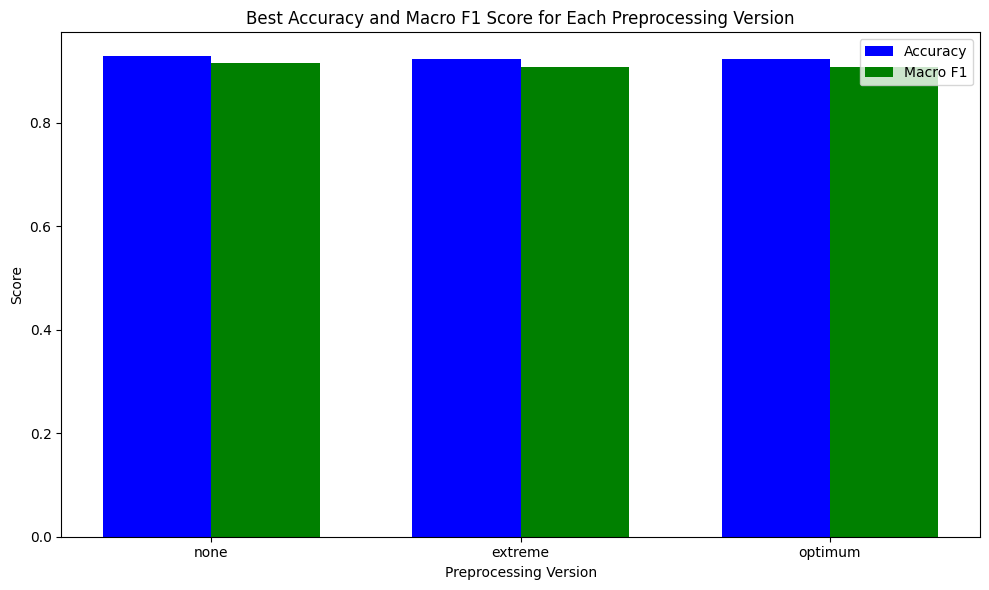

In [26]:
preprocessing_names = list(best_runs.keys())
best_accuracies = [best_run['accuracy'] for best_run in best_runs.values()]
best_f1_scores = [best_run['macro_f1'] for best_run in best_runs.values()]

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.35
index = range(len(preprocessing_names))

ax.bar(index, best_accuracies, bar_width, label='Accuracy', color='b')
ax.bar([i + bar_width for i in index], best_f1_scores, bar_width, label='Macro F1', color='g')

ax.set_xlabel('Preprocessing Version')
ax.set_ylabel('Score')
ax.set_title('Best Accuracy and Macro F1 Score for Each Preprocessing Version')
ax.set_xticks([i + bar_width / 2 for i in index])
ax.set_xticklabels(preprocessing_names)
ax.legend()

plt.tight_layout()
plt.show()

## TF-IDF + Deep Neural Network

The PDF asks for a DNN with at least 3 to 4+ layers and 128+ neurons in the first layer.

Because raw TF-IDF can be very high-dimensional, two practical options are:

1. use sparse TF-IDF directly as Keras input
2. reduce TF-IDF with TruncatedSVD first, then train the DNN on dense vectors

The cells below implement the safer dense version using TruncatedSVD. It still starts from TF-IDF.

## DNN builder, cached dense inputs, and checkpointed training

In [27]:
def build_tfidf_dnn(input_dim, n_classes, learning_rate=1e-3, dropout_rate=0.3):
    model = Sequential([
        Dense(512, activation="relu", input_shape=(input_dim,)),
        Dropout(dropout_rate),
        Dense(256, activation="relu"),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def build_or_load_tfidf_dnn_inputs(preprocessing_name, X_train, X_val, n_components=1024):
    tfidf_params = {"max_features": 50000, "ngram_range": (1, 2), "min_df": 3, "max_df": 0.95}
    vectorizer, X_train_tfidf, X_val_tfidf = build_tfidf_features(
        preprocessing_name,
        X_train,
        X_val,
        max_features=tfidf_params["max_features"],
        ngram_range=tfidf_params["ngram_range"],
        min_df=tfidf_params["min_df"],
        max_df=tfidf_params["max_df"]
    )

    params = {"n_components": n_components, **tfidf_params}
    signature = params_signature(params)
    cache_dir = TFIDF_DIR / f"{preprocessing_name}_dnn_{signature}"
    svd_path = cache_dir / "svd.pkl"
    X_train_dense_path = cache_dir / "X_train_dense.npy"
    X_val_dense_path = cache_dir / "X_val_dense.npy"

    if svd_path.exists() and X_train_dense_path.exists() and X_val_dense_path.exists() and not FORCE_REBUILD_FEATURES:
        svd = load_pickle(svd_path)
        X_train_dense = np.load(X_train_dense_path)
        X_val_dense = np.load(X_val_dense_path)
    else:
        cache_dir.mkdir(parents=True, exist_ok=True)
        svd = TruncatedSVD(n_components=n_components, random_state=SEED)
        X_train_dense = svd.fit_transform(X_train_tfidf).astype("float32")
        X_val_dense = svd.transform(X_val_tfidf).astype("float32")
        save_pickle(svd, svd_path)
        np.save(X_train_dense_path, X_train_dense)
        np.save(X_val_dense_path, X_val_dense)

    return vectorizer, svd, X_train_dense, X_val_dense

def run_tfidf_dnn(preprocessing_name, train_text, train_labels, n_components=1024, batch_size=256, epochs=15, force_retrain=False):
    X_train, X_val, y_train, y_val, y_train_enc, y_val_enc, class_weight_dict = make_split(
        train_text,
        train_labels,
        train_df["group_key"]
    )

    vectorizer, svd, X_train_dense, X_val_dense = build_or_load_tfidf_dnn_inputs(
        preprocessing_name,
        X_train,
        X_val,
        n_components=n_components
    )

    run_name = f"TFIDF_DNN_{preprocessing_name}_svd{n_components}_bs{batch_size}_ep{epochs}_seed{SEED}"
    model = build_tfidf_dnn(X_train_dense.shape[1], len(label_encoder.classes_))

    if run_is_complete(run_name) and not (FORCE_RETRAIN or force_retrain):
        model.load_weights(str(get_checkpoint_path(run_name)))
        history = None
        print(f"Loaded saved checkpoint for {run_name}")
    else:
        callbacks = build_callbacks(run_name, patience=3)
        history = model.fit(
            X_train_dense,
            y_train_enc,
            validation_data=(X_val_dense, y_val_enc),
            epochs=epochs,
            batch_size=batch_size,
            class_weight=class_weight_dict,
            callbacks=callbacks,
            verbose=1
        )
        save_history_object(history, run_name)
        mark_run_complete(
            run_name,
            {
                "preprocessing": preprocessing_name,
                "representation": "TF-IDF",
                "model": "DeepNN",
                "n_components": n_components,
                "batch_size": batch_size,
                "epochs": epochs
            }
        )

    val_pred = model.predict(X_val_dense, verbose=0).argmax(axis=1)
    val_pred_labels = label_encoder.inverse_transform(val_pred)

    metrics, report_df = evaluate_predictions(y_val, val_pred_labels, label_encoder.classes_)
    log_result(preprocessing_name, "TF-IDF", "DeepNN", "validation", metrics, {"n_components": n_components, "batch_size": batch_size, "epochs": epochs})
    log_tuning("TF-IDF_DNN", preprocessing_name, "DeepNN", {"n_components": n_components, "batch_size": batch_size, "epochs": epochs}, metrics["accuracy"], metrics["macro_f1"])

    print(metrics)
    display(report_df)
    show_confusion(y_val, val_pred_labels, label_encoder.classes_, f"DNN | {preprocessing_name}")
    return model, vectorizer, svd, history, metrics, report_df

## Run the TF-IDF DNN on all three preprocessing variants

Running DNN for: none
Loaded saved checkpoint for TFIDF_DNN_none_svd1024_bs256_ep12_seed42
{'accuracy': 0.9145494932666944, 'macro_f1': 0.8990018384618809}


,precision,recall,f1-score,support
Business,0.903811,0.851723,0.876994,3453.000000
Science and Technology,0.858971,0.915861,0.886504,3518.000000
Sports,0.982377,0.963152,0.972670,5672.000000
World News,0.841848,0.878616,0.859839,1763.000000
accuracy,0.914549,0.914549,0.914549,0.914549
macro avg,0.896752,0.902338,0.899002,14406.000000
weighted avg,0.916211,0.914549,0.914887,14406.000000


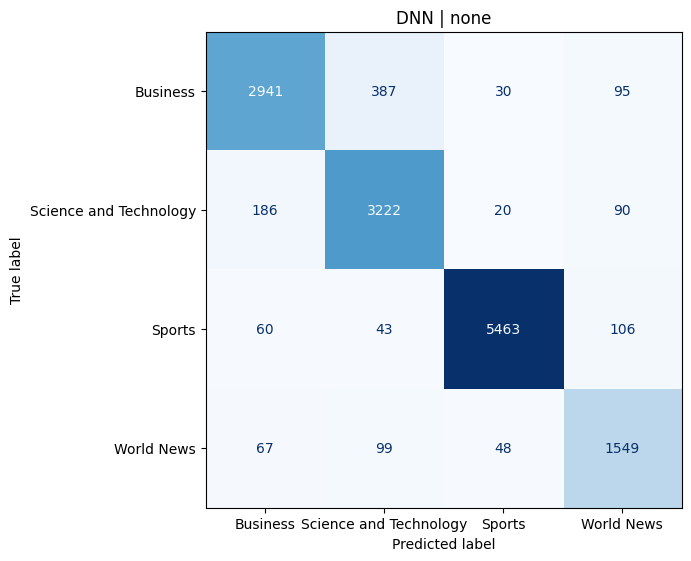

Running DNN for: extreme
Loaded saved checkpoint for TFIDF_DNN_extreme_svd1024_bs256_ep12_seed42
{'accuracy': 0.9132305983617937, 'macro_f1': 0.8989412492639889}


,precision,recall,f1-score,support
Business,0.882301,0.861859,0.871960,3453.000000
Science and Technology,0.855344,0.907618,0.880706,3518.000000
Sports,0.982551,0.962976,0.972665,5672.000000
World News,0.875933,0.865003,0.870434,1763.000000
accuracy,0.913231,0.913231,0.913231,0.913231
macro avg,0.899032,0.899364,0.898941,14406.000000
weighted avg,0.914410,0.913231,0.913559,14406.000000


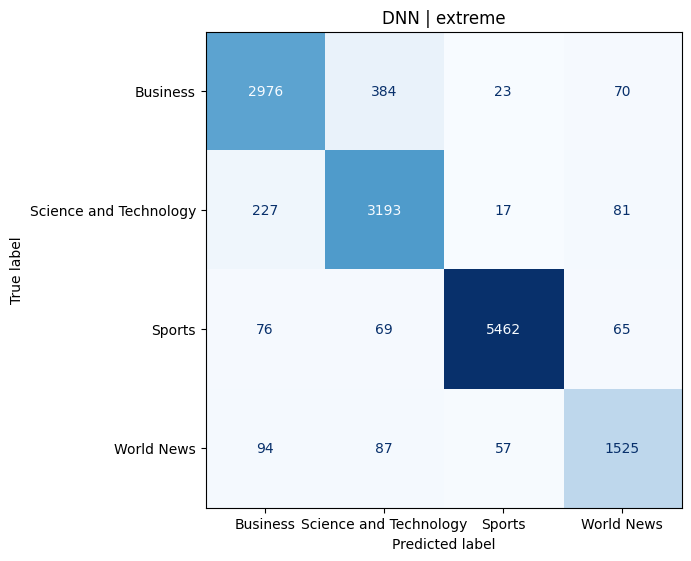

Running DNN for: optimum
Loaded saved checkpoint for TFIDF_DNN_optimum_svd1024_bs256_ep12_seed42
{'accuracy': 0.9089268360405387, 'macro_f1': 0.8930542521504236}


,precision,recall,f1-score,support
Business,0.890520,0.843325,0.866280,3453.000000
Science and Technology,0.846010,0.901080,0.872677,3518.000000
Sports,0.977912,0.967913,0.972887,5672.000000
World News,0.857465,0.863301,0.860373,1763.000000
accuracy,0.908927,0.908927,0.908927,0.908927
macro avg,0.892977,0.893905,0.893054,14406.000000
weighted avg,0.910014,0.908927,0.909093,14406.000000


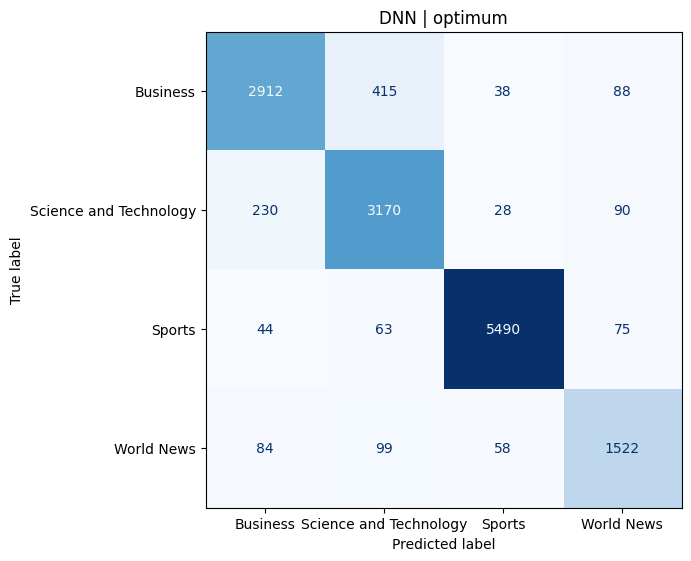

In [28]:
dnn_runs = {}

for preprocessing_name in ["none", "extreme", "optimum"]:
    print("=" * 80)
    print(f"Running DNN for: {preprocessing_name}")
    dnn_runs[preprocessing_name] = run_tfidf_dnn(
        preprocessing_name,
        train_versions[preprocessing_name],
        train_df["News Topic"],
        n_components=1024,
        batch_size=256,
        epochs=12
    )

## Skip-gram preparation

The recurrent models in the PDF should use Skip-gram embeddings.

The workflow below is:
1. tokenize the chosen preprocessed text
2. train Word2Vec with `sg=1`
3. build a tokenizer and padded sequences
4. create the embedding matrix
5. train RNN / GRU / LSTM / bidirectional variants

## Skip-gram helpers and cached sequence preparation

In [29]:
def tokenize_for_skipgram(text_series):
    return [text.split() for text in text_series]

def train_skipgram_embeddings(tokenized_texts, vector_size=200, window=5, min_count=2, epochs=15):
    model = Word2Vec(
        sentences=tokenized_texts,
        vector_size=vector_size,
        window=window,
        min_count=min_count,
        sg=1,
        workers=4,
        epochs=epochs,
        seed=SEED
    )
    return model

def build_sequence_data(train_text, val_text, max_vocab=50000, max_len=60):
    tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
    tokenizer.fit_on_texts(train_text)

    X_train_seq = tokenizer.texts_to_sequences(train_text)
    X_val_seq = tokenizer.texts_to_sequences(val_text)

    X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
    X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding="post", truncating="post")
    return tokenizer, X_train_pad, X_val_pad

def build_embedding_matrix(tokenizer, w2v_model, max_vocab=50000):
    embedding_dim = w2v_model.vector_size
    vocab_size = min(max_vocab, len(tokenizer.word_index) + 1)

    embedding_matrix = np.random.normal(0, 0.05, (vocab_size, embedding_dim))
    embedding_matrix[0] = np.zeros(embedding_dim)

    for word, idx in tokenizer.word_index.items():
        if idx >= vocab_size:
            continue
        if word in w2v_model.wv:
            embedding_matrix[idx] = w2v_model.wv[word]

    return embedding_matrix

## Prepare tokenizer, sequences, and embedding matrix

In [30]:
def prepare_skipgram_inputs(preprocessing_name, train_text_series, train_labels, max_vocab=50000, max_len=60, force=False):
    params = {
        "max_vocab": max_vocab,
        "max_len": max_len,
        "vector_size": 200,
        "window": 5,
        "min_count": 2,
        "w2v_epochs": 15
    }
    signature = params_signature(params)
    cache_dir = SKIPGRAM_DIR / f"{preprocessing_name}_{signature}"
    prepared_path = cache_dir / "prepared.pkl"

    if prepared_path.exists() and not (FORCE_REBUILD_SKIPGRAM or force):
        prepared_data = load_pickle(prepared_path)
        print(f"Loaded cached skip-gram inputs for {preprocessing_name}")
        return prepared_data

    cache_dir.mkdir(parents=True, exist_ok=True)

    X_train, X_val, y_train, y_val, y_train_enc, y_val_enc, class_weight_dict = make_split(
        train_text_series,
        train_labels,
        train_df["group_key"]
    )

    tokenized_train = tokenize_for_skipgram(X_train)
    w2v_model = train_skipgram_embeddings(
        tokenized_train,
        vector_size=params["vector_size"],
        window=params["window"],
        min_count=params["min_count"],
        epochs=params["w2v_epochs"]
    )

    tokenizer, X_train_pad, X_val_pad = build_sequence_data(X_train, X_val, max_vocab=max_vocab, max_len=max_len)
    embedding_matrix = build_embedding_matrix(tokenizer, w2v_model, max_vocab=max_vocab)

    prepared_data = {
        "preprocessing": preprocessing_name,
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val,
        "y_train_enc": y_train_enc,
        "y_val_enc": y_val_enc,
        "class_weights": class_weight_dict,
        "tokenizer": tokenizer,
        "X_train_pad": X_train_pad,
        "X_val_pad": X_val_pad,
        "embedding_matrix": embedding_matrix,
        "max_vocab": max_vocab,
        "max_len": max_len,
        "params": params
    }

    save_pickle(prepared_data, prepared_path)
    return prepared_data

## Recurrent model builders

In [31]:
def build_simple_rnn_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        SimpleRNN(units),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

def build_gru_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        GRU(units),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

def build_lstm_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        LSTM(units),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

def build_bi_simple_rnn_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        Bidirectional(SimpleRNN(units)),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

def build_bi_gru_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        Bidirectional(GRU(units)),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

def build_bi_lstm_model(vocab_size, embedding_matrix, max_len, n_classes, units=128, dropout_rate=0.3):
    model = Sequential([
        Embedding(vocab_size, embedding_matrix.shape[1], weights=[embedding_matrix], input_length=max_len, trainable=False),
        SpatialDropout1D(dropout_rate),
        Bidirectional(LSTM(units)),
        Dropout(dropout_rate),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(n_classes, activation="softmax")
    ])
    return model

## Unified sequence training with checkpoint reload

In [32]:
def compile_model(model, learning_rate=1e-3):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def run_sequence_model(prepared_data, model_name, units=128, dropout_rate=0.3, batch_size=256, epochs=12, force_retrain=False):
    embedding_matrix = prepared_data["embedding_matrix"]
    vocab_size = embedding_matrix.shape[0]
    max_len = prepared_data["max_len"]
    n_classes = len(label_encoder.classes_)

    builders = {
        "SimpleRNN": build_simple_rnn_model,
        "GRU": build_gru_model,
        "LSTM": build_lstm_model,
        "BiSimpleRNN": build_bi_simple_rnn_model,
        "BiGRU": build_bi_gru_model,
        "BiLSTM": build_bi_lstm_model
    }

    model = builders[model_name](
        vocab_size=vocab_size,
        embedding_matrix=embedding_matrix,
        max_len=max_len,
        n_classes=n_classes,
        units=units,
        dropout_rate=dropout_rate
    )
    model = compile_model(model)

    run_name = f"SKIPGRAM_{prepared_data['preprocessing']}_{model_name}_u{units}_d{dropout_rate}_bs{batch_size}_ep{epochs}_seed{SEED}"

    if run_is_complete(run_name) and not (FORCE_RETRAIN or force_retrain):
        model.build(input_shape=(None, max_len))
        model.load_weights(str(get_checkpoint_path(run_name)))
        history = None
        print(f"Loaded saved checkpoint for {run_name}")
    else:
        callbacks = build_callbacks(run_name, patience=3)
        history = model.fit(
            prepared_data["X_train_pad"],
            prepared_data["y_train_enc"],
            validation_data=(prepared_data["X_val_pad"], prepared_data["y_val_enc"]),
            epochs=epochs,
            batch_size=batch_size,
            class_weight=prepared_data["class_weights"],
            callbacks=callbacks,
            verbose=1
        )
        save_history_object(history, run_name)
        mark_run_complete(
            run_name,
            {
                "preprocessing": prepared_data["preprocessing"],
                "representation": "Skip-gram",
                "model": model_name,
                "units": units,
                "dropout_rate": dropout_rate,
                "batch_size": batch_size,
                "epochs": epochs
            }
        )

    val_pred = model.predict(prepared_data["X_val_pad"], verbose=0).argmax(axis=1)
    val_pred_labels = label_encoder.inverse_transform(val_pred)
    y_val_labels = prepared_data["y_val"]

    metrics, report_df = evaluate_predictions(y_val_labels, val_pred_labels, label_encoder.classes_)
    log_result(prepared_data["preprocessing"], "Skip-gram", model_name, "validation", metrics, {"units": units, "dropout_rate": dropout_rate, "batch_size": batch_size, "epochs": epochs})
    log_tuning("SKIPGRAM_RNN", prepared_data["preprocessing"], model_name, {"units": units, "dropout_rate": dropout_rate, "batch_size": batch_size, "epochs": epochs}, metrics["accuracy"], metrics["macro_f1"])

    print(metrics)
    display(report_df)
    show_confusion(y_val_labels, val_pred_labels, label_encoder.classes_, f"{model_name} | {prepared_data['preprocessing']}")
    return model, history, metrics, report_df

## Prepare one Skip-gram dataset first

In [33]:
prepared_optimum = prepare_skipgram_inputs(
    "optimum",
    train_versions["optimum"],
    train_df["News Topic"],
    max_vocab=50000,
    max_len=60
)

prepared_optimum.keys()

Loaded cached skip-gram inputs for optimum


dict_keys(['preprocessing', 'X_train', 'X_val', 'y_train', 'y_val', 'y_train_enc', 'y_val_enc', 'class_weights', 'tokenizer', 'X_train_pad', 'X_val_pad', 'embedding_matrix', 'max_vocab', 'max_len', 'params'])

## Full long-running cell: run the six sequence models on all three preprocessing variants

Because preprocessing files, Skip-gram inputs, and model checkpoints are cached, rerunning this section will reuse saved artifacts whenever they already exist. Set `FORCE_REBUILD_SKIPGRAM=True` or `FORCE_RETRAIN=True` only when you intentionally want to rebuild them.


Loaded cached skip-gram inputs for none
Running SimpleRNN on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.598153547133139, 'macro_f1': 0.5483806447748824}


,precision,recall,f1-score,support
Business,0.511042,0.670142,0.579877,3453.000000
Science and Technology,0.440571,0.237067,0.308261,3518.000000
Sports,0.977968,0.743477,0.844752,5672.000000
World News,0.340866,0.710153,0.460633,1763.000000
accuracy,0.598154,0.598154,0.598154,0.598154
macro avg,0.567612,0.590210,0.548381,14406.000000
weighted avg,0.656847,0.598154,0.603242,14406.000000


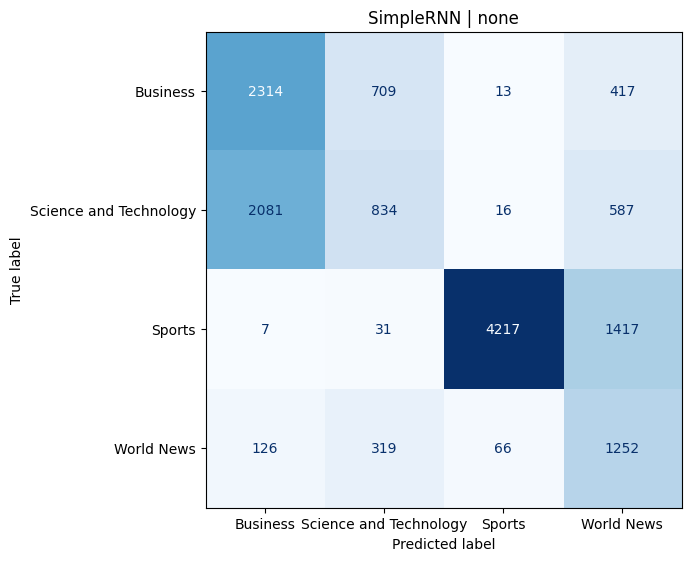

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.5989865333888658, 'macro_f1': 0.45056344071462906}


,precision,recall,f1-score,support
Business,0.567485,0.321460,0.410427,3453.000000
Science and Technology,0.378038,0.725128,0.496980,3518.000000
Sports,0.886543,0.873413,0.879929,5672.000000
World News,0.122807,0.007941,0.014917,1763.000000
accuracy,0.598987,0.598987,0.598987,0.598987
macro avg,0.488718,0.481985,0.450563,14406.000000
weighted avg,0.592423,0.598987,0.568016,14406.000000


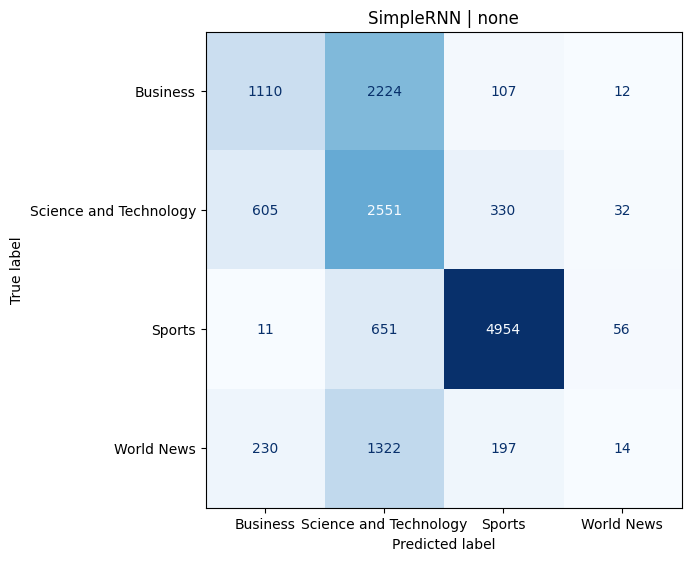

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.1409829237817576, 'macro_f1': 0.09832873129715648}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.315975,0.101762,0.153945,3518.000000
Sports,0.692308,0.012694,0.024931,5672.000000
World News,0.121573,0.908111,0.214439,1763.000000
accuracy,0.140983,0.140983,0.140983,0.140983
macro avg,0.282464,0.255642,0.098329,14406.000000
weighted avg,0.364619,0.140983,0.073653,14406.000000


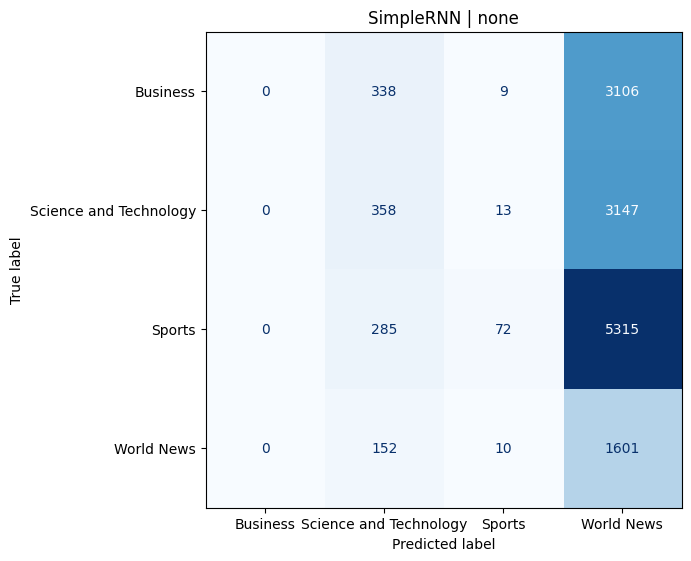

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.2525336665278356, 'macro_f1': 0.11207487635009303}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.245852,0.989767,0.393869,3518.000000
Sports,0.666667,0.027151,0.052177,5672.000000
World News,0.166667,0.001134,0.002254,1763.000000
accuracy,0.252534,0.252534,0.252534,0.252534
macro avg,0.269796,0.254513,0.112075,14406.000000
weighted avg,0.342918,0.252534,0.117003,14406.000000


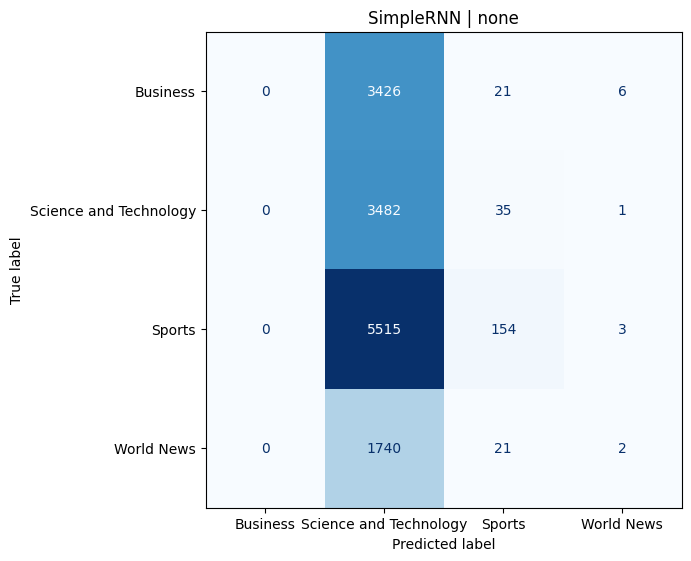

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.6369568235457448, 'macro_f1': 0.5846993015154245}


,precision,recall,f1-score,support
Business,0.583495,0.262091,0.361711,3453.000000
Science and Technology,0.478388,0.604036,0.533920,3518.000000
Sports,0.972437,0.821051,0.890355,5672.000000
World News,0.410872,0.844583,0.552812,1763.000000
accuracy,0.636957,0.636957,0.636957,0.636957
macro avg,0.611298,0.632940,0.584699,14406.000000
weighted avg,0.689838,0.636957,0.635292,14406.000000


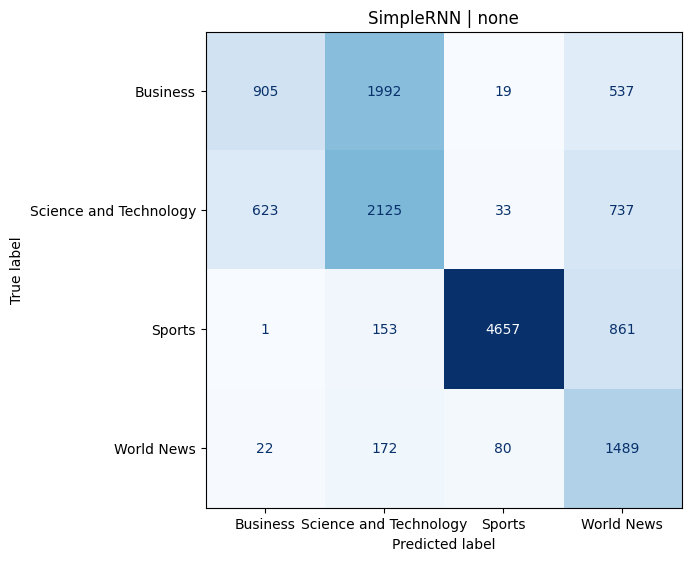

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.24420380397056782, 'macro_f1': 0.09813657665699621}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.244204,1.000000,0.392546,3518.000000
Sports,0.000000,0.000000,0.000000,5672.000000
World News,0.000000,0.000000,0.000000,1763.000000
accuracy,0.244204,0.244204,0.244204,0.244204
macro avg,0.061051,0.250000,0.098137,14406.000000
weighted avg,0.059635,0.244204,0.095861,14406.000000


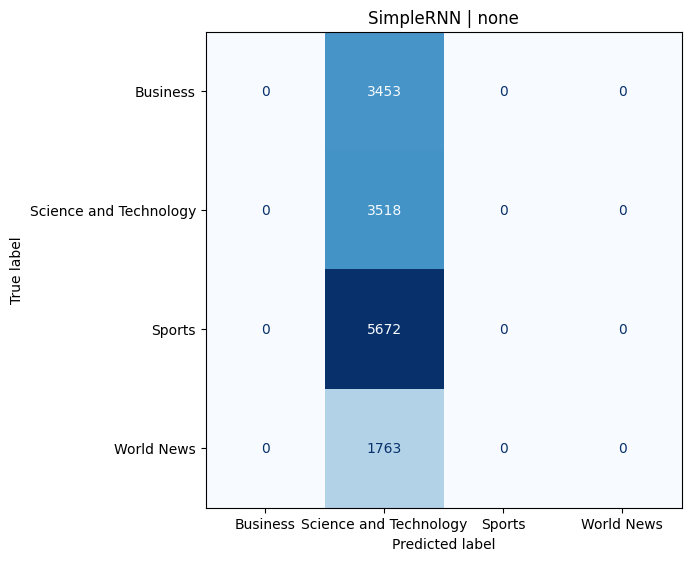

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.5639316951270305, 'macro_f1': 0.5100338898212253}


,precision,recall,f1-score,support
Business,0.516831,0.515783,0.516307,3453.000000
Science and Technology,0.448084,0.182774,0.259641,3518.000000
Sports,0.966402,0.750529,0.844894,5672.000000
World News,0.281836,0.818491,0.419294,1763.000000
accuracy,0.563932,0.563932,0.563932,0.563932
macro avg,0.553288,0.566894,0.510034,14406.000000
weighted avg,0.648291,0.563932,0.571129,14406.000000


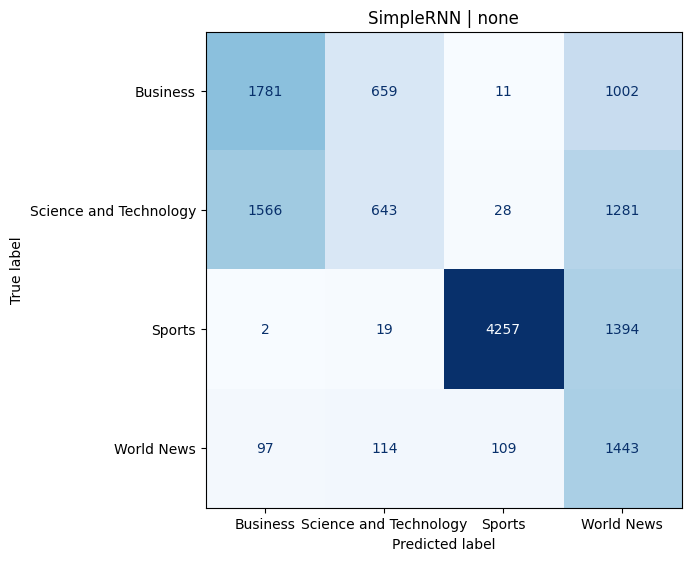

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_SimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.5864223240316535, 'macro_f1': 0.43056560223516915}


,precision,recall,f1-score,support
Business,0.437393,0.736461,0.548829,3453.000000
Science and Technology,0.000000,0.000000,0.000000,3518.000000
Sports,0.862325,0.943054,0.900884,5672.000000
World News,0.239965,0.315372,0.272549,1763.000000
accuracy,0.586422,0.586422,0.586422,0.586422
macro avg,0.384921,0.498722,0.430566,14406.000000
weighted avg,0.473725,0.586422,0.519605,14406.000000


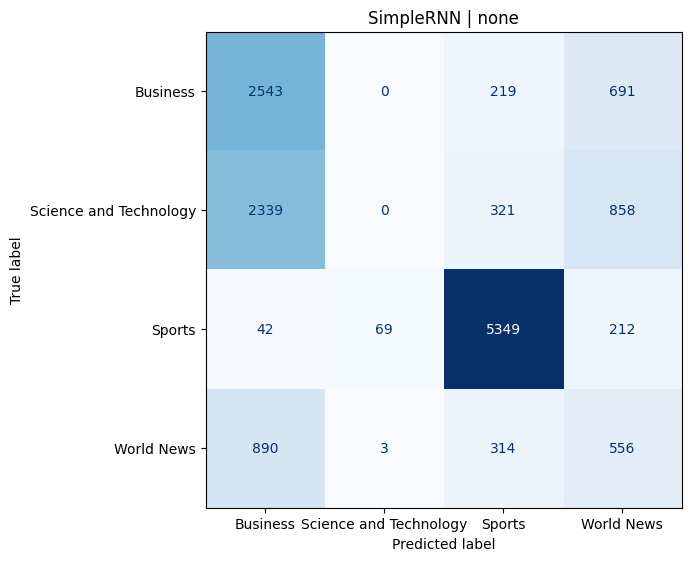

Running GRU on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9062890462307371, 'macro_f1': 0.889820938628036}


,precision,recall,f1-score,support
Business,0.873156,0.857226,0.865118,3453.000000
Science and Technology,0.870675,0.872655,0.871664,3518.000000
Sports,0.973881,0.966326,0.970088,5672.000000
World News,0.829753,0.876347,0.852414,1763.000000
accuracy,0.906289,0.906289,0.906289,0.906289
macro avg,0.886866,0.893138,0.889821,14406.000000
weighted avg,0.906896,0.906289,0.906491,14406.000000


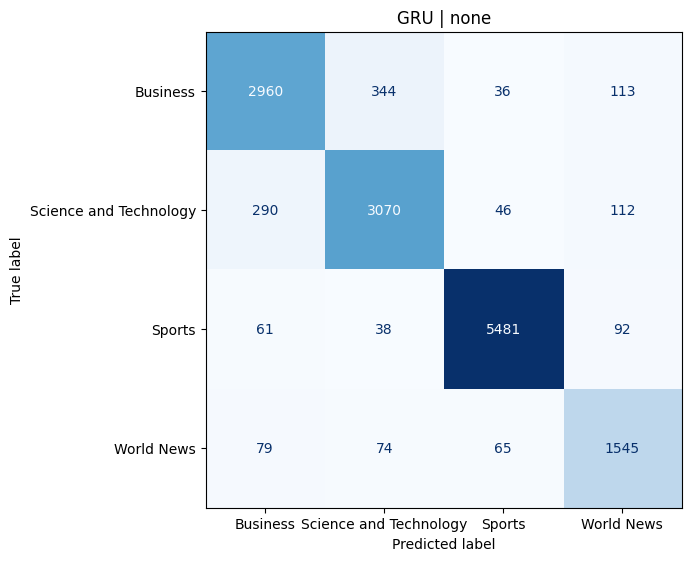

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9123281965847564, 'macro_f1': 0.8964025843431795}


,precision,recall,f1-score,support
Business,0.884067,0.861280,0.872525,3453.000000
Science and Technology,0.864091,0.883741,0.873806,3518.000000
Sports,0.975159,0.975846,0.975502,5672.000000
World News,0.862557,0.865003,0.863778,1763.000000
accuracy,0.912328,0.912328,0.912328,0.912328
macro avg,0.896468,0.896467,0.896403,14406.000000
weighted avg,0.912421,0.912328,0.912312,14406.000000


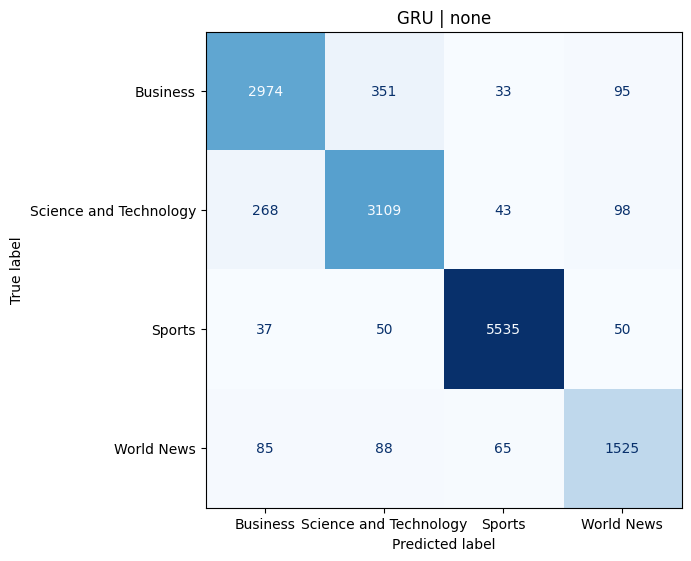

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.8982368457587117, 'macro_f1': 0.8799247704996707}


,precision,recall,f1-score,support
Business,0.890566,0.820156,0.853912,3453.000000
Science and Technology,0.842562,0.882319,0.861983,3518.000000
Sports,0.980509,0.957863,0.969054,5672.000000
World News,0.785107,0.891095,0.834750,1763.000000
accuracy,0.898237,0.898237,0.898237,0.898237
macro avg,0.874686,0.887858,0.879925,14406.000000
weighted avg,0.901350,0.898237,0.898872,14406.000000


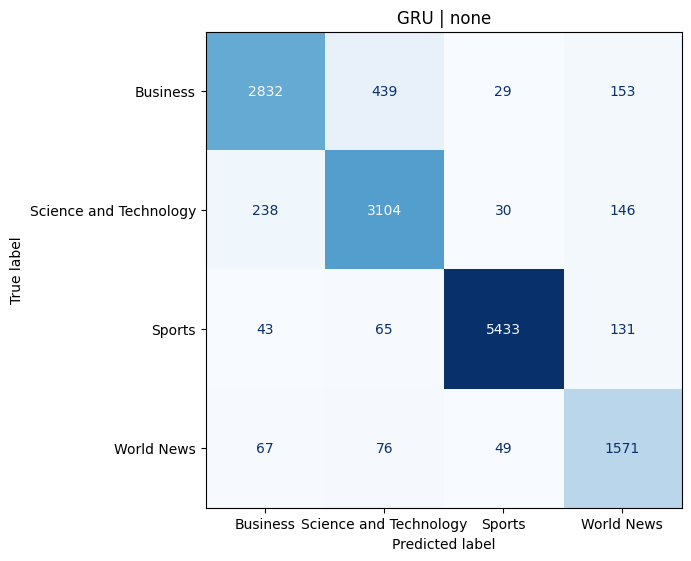

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.902818270165209, 'macro_f1': 0.8850851575469937}


,precision,recall,f1-score,support
Business,0.892000,0.839560,0.864986,3453.000000
Science and Technology,0.859497,0.874645,0.867005,3518.000000
Sports,0.975004,0.962800,0.968864,5672.000000
World News,0.794430,0.889960,0.839486,1763.000000
accuracy,0.902818,0.902818,0.902818,0.902818
macro avg,0.880233,0.891741,0.885085,14406.000000
weighted avg,0.904803,0.902818,0.903258,14406.000000


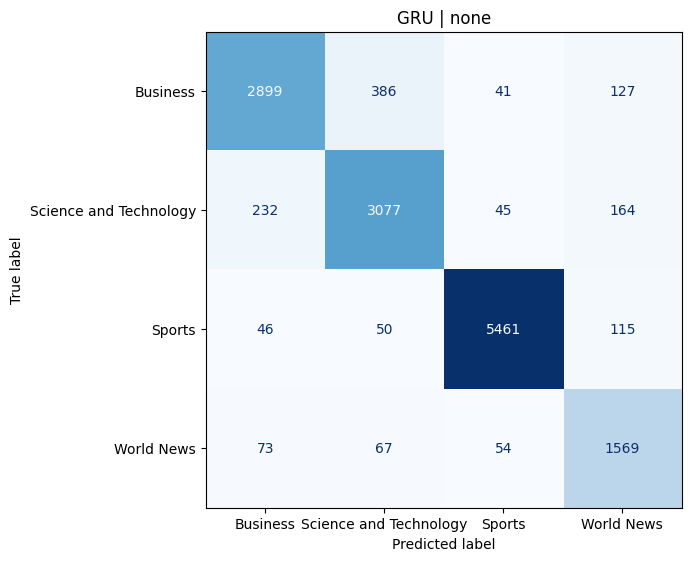

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.902818270165209, 'macro_f1': 0.8868292423053896}


,precision,recall,f1-score,support
Business,0.874325,0.844193,0.858995,3453.000000
Science and Technology,0.846467,0.885446,0.865518,3518.000000
Sports,0.979640,0.958568,0.968989,5672.000000
World News,0.835505,0.872944,0.853814,1763.000000
accuracy,0.902818,0.902818,0.902818,0.902818
macro avg,0.883984,0.890288,0.886829,14406.000000
weighted avg,0.904236,0.902818,0.903262,14406.000000


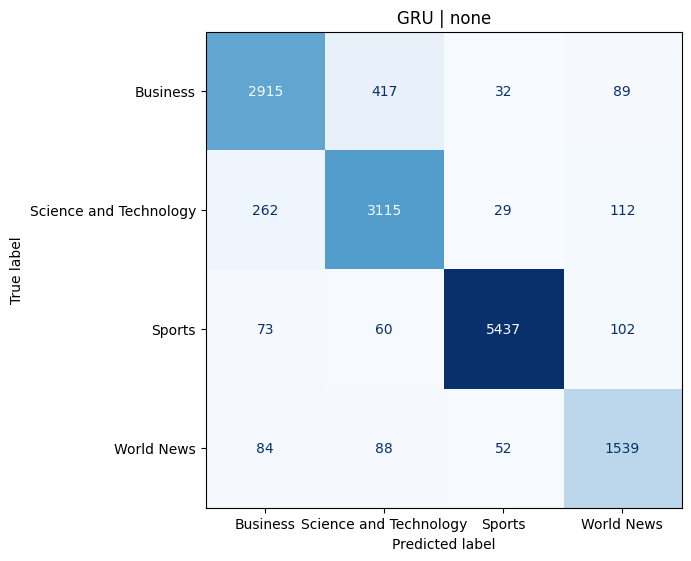

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9033041788143829, 'macro_f1': 0.8855284987277949}


,precision,recall,f1-score,support
Business,0.897933,0.817840,0.856017,3453.000000
Science and Technology,0.845264,0.892837,0.868399,3518.000000
Sports,0.978750,0.966326,0.972498,5672.000000
World News,0.805656,0.888826,0.845200,1763.000000
accuracy,0.903304,0.903304,0.903304,0.903304
macro avg,0.881901,0.891457,0.885528,14406.000000
weighted avg,0.905598,0.903304,0.903578,14406.000000


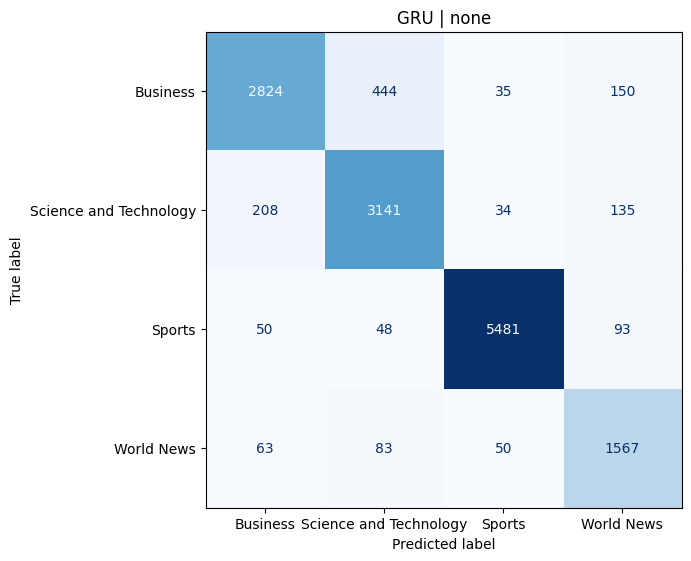

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9009440510898237, 'macro_f1': 0.8831309958369299}


,precision,recall,f1-score,support
Business,0.877870,0.830582,0.853571,3453.000000
Science and Technology,0.848410,0.879761,0.863801,3518.000000
Sports,0.976301,0.965973,0.971110,5672.000000
World News,0.817988,0.871809,0.844042,1763.000000
accuracy,0.900944,0.900944,0.900944,0.900944
macro avg,0.880142,0.887031,0.883131,14406.000000
weighted avg,0.902102,0.900944,0.901181,14406.000000


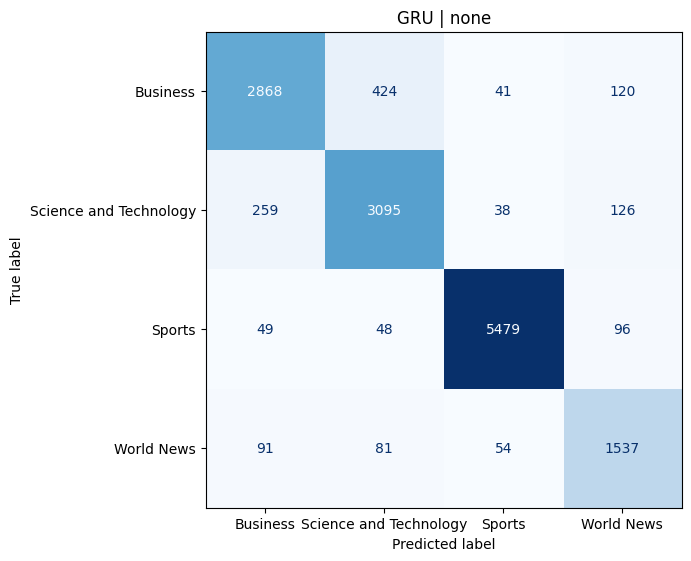

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_GRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9003887269193391, 'macro_f1': 0.8837305083024247}


,precision,recall,f1-score,support
Business,0.883578,0.835216,0.858717,3453.000000
Science and Technology,0.837809,0.886868,0.861640,3518.000000
Sports,0.981871,0.954866,0.968180,5672.000000
World News,0.815457,0.879750,0.846385,1763.000000
accuracy,0.900389,0.900389,0.900389,0.900389
macro avg,0.879679,0.889175,0.883731,14406.000000
weighted avg,0.902765,0.900389,0.901020,14406.000000


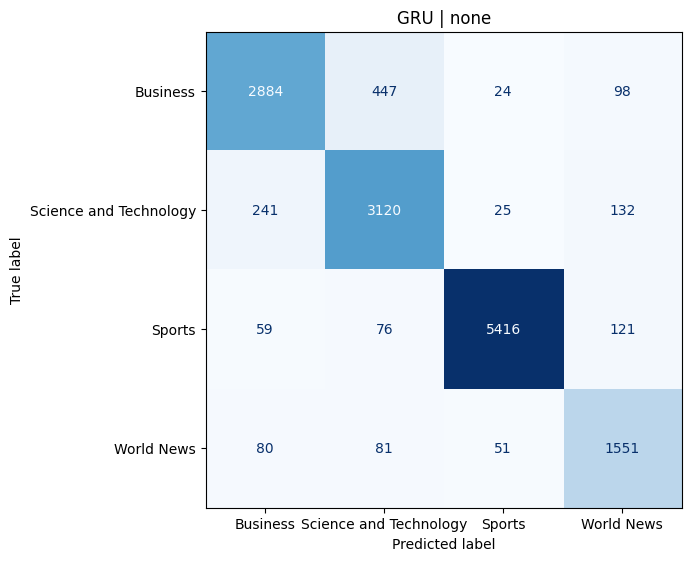

Running LSTM on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9025406080799667, 'macro_f1': 0.8862133692609535}


,precision,recall,f1-score,support
Business,0.864651,0.852882,0.858726,3453.000000
Science and Technology,0.853618,0.875213,0.864281,3518.000000
Sports,0.975013,0.963152,0.969047,5672.000000
World News,0.846369,0.859331,0.852800,1763.000000
accuracy,0.902541,0.902541,0.902541,0.902541
macro avg,0.884913,0.887644,0.886213,14406.000000
weighted avg,0.903172,0.902541,0.902793,14406.000000


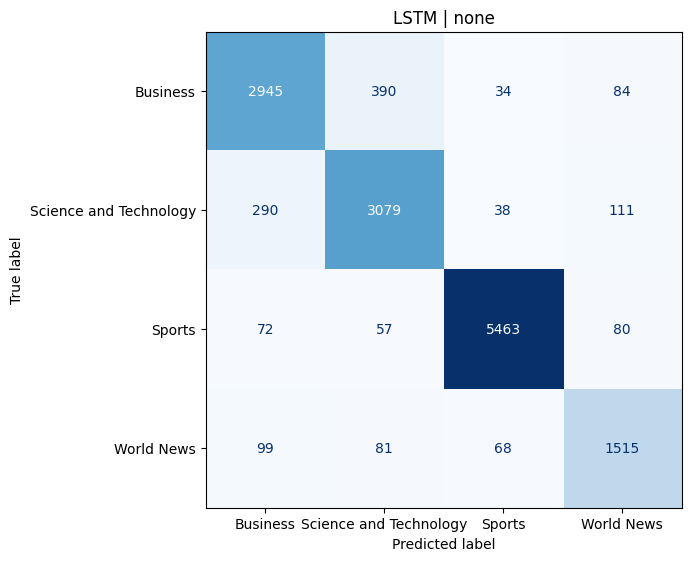

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.907746772178259, 'macro_f1': 0.8921471807148837}


,precision,recall,f1-score,support
Business,0.850523,0.871706,0.860984,3453.000000
Science and Technology,0.868443,0.870665,0.869553,3518.000000
Sports,0.972198,0.974083,0.973140,5672.000000
World News,0.892577,0.838911,0.864912,1763.000000
accuracy,0.907747,0.907747,0.907747,0.907747
macro avg,0.895935,0.888841,0.892147,14406.000000
weighted avg,0.907952,0.907747,0.907716,14406.000000


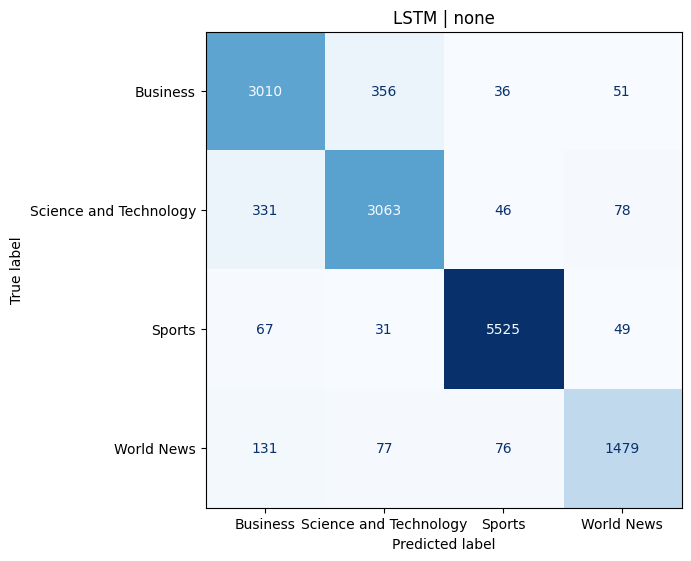

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9012217131750659, 'macro_f1': 0.8842513545264047}


,precision,recall,f1-score,support
Business,0.846655,0.865045,0.855751,3453.000000
Science and Technology,0.868581,0.851052,0.859727,3518.000000
Sports,0.973913,0.967560,0.970726,5672.000000
World News,0.842984,0.858763,0.850801,1763.000000
accuracy,0.901222,0.901222,0.901222,0.901222
macro avg,0.883034,0.885605,0.884251,14406.000000
weighted avg,0.901665,0.901222,0.901385,14406.000000


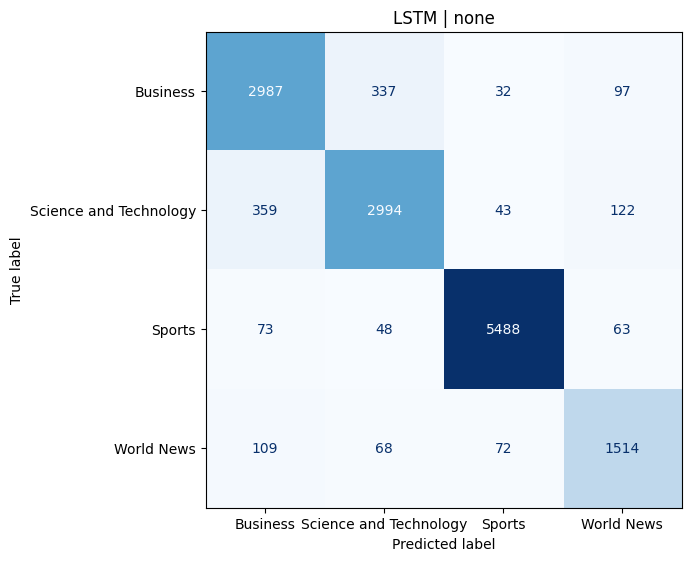

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9027488546438984, 'macro_f1': 0.8852354973486943}


,precision,recall,f1-score,support
Business,0.861521,0.863018,0.862269,3453.000000
Science and Technology,0.879777,0.850767,0.865029,3518.000000
Sports,0.974720,0.965268,0.969971,5672.000000
World News,0.807573,0.883154,0.843674,1763.000000
accuracy,0.902749,0.902749,0.902749,0.902749
macro avg,0.880897,0.890552,0.885235,14406.000000
weighted avg,0.903946,0.902749,0.903072,14406.000000


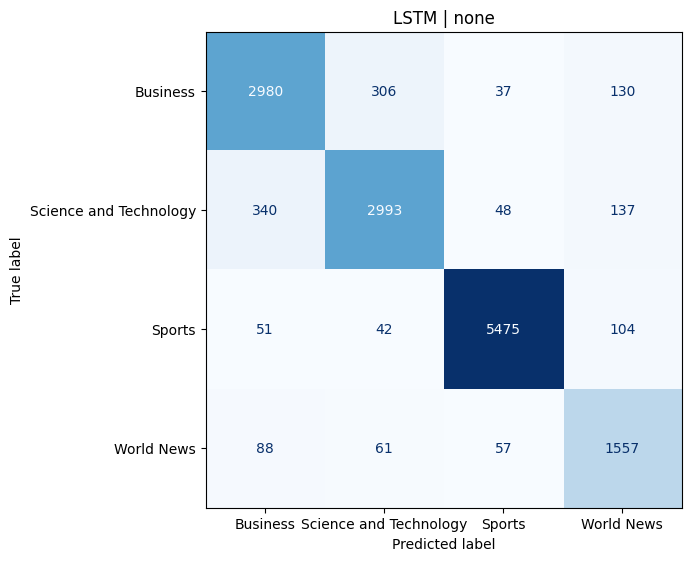

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9020546994307928, 'macro_f1': 0.8848810181790043}


,precision,recall,f1-score,support
Business,0.860158,0.849696,0.854895,3453.000000
Science and Technology,0.854545,0.868391,0.861413,3518.000000
Sports,0.968608,0.973731,0.971162,5672.000000
World News,0.863213,0.841180,0.852054,1763.000000
accuracy,0.902055,0.902055,0.902055,0.902055
macro avg,0.886631,0.883249,0.884881,14406.000000
weighted avg,0.901861,0.902055,0.901916,14406.000000


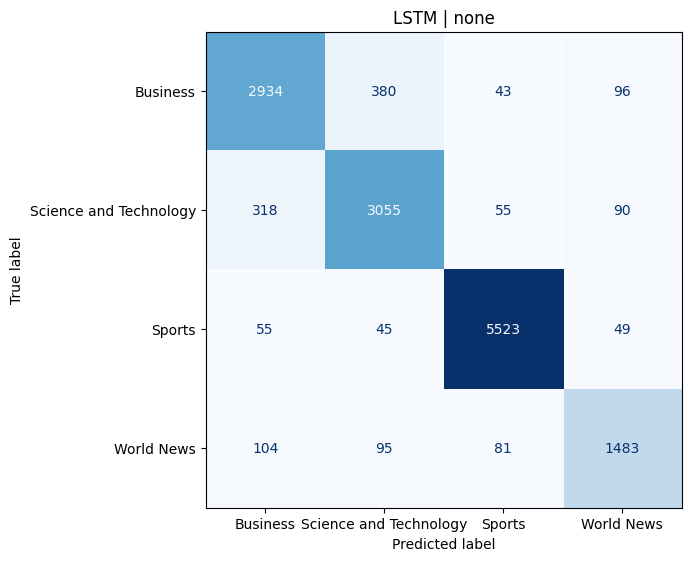

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9094821602110232, 'macro_f1': 0.893536257332499}


,precision,recall,f1-score,support
Business,0.889640,0.838112,0.863108,3453.000000
Science and Technology,0.845968,0.897669,0.871052,3518.000000
Sports,0.976843,0.974260,0.975549,5672.000000
World News,0.864436,0.864436,0.864436,1763.000000
accuracy,0.909482,0.909482,0.909482,0.909482
macro avg,0.894222,0.893619,0.893536,14406.000000
weighted avg,0.910225,0.909482,0.909481,14406.000000


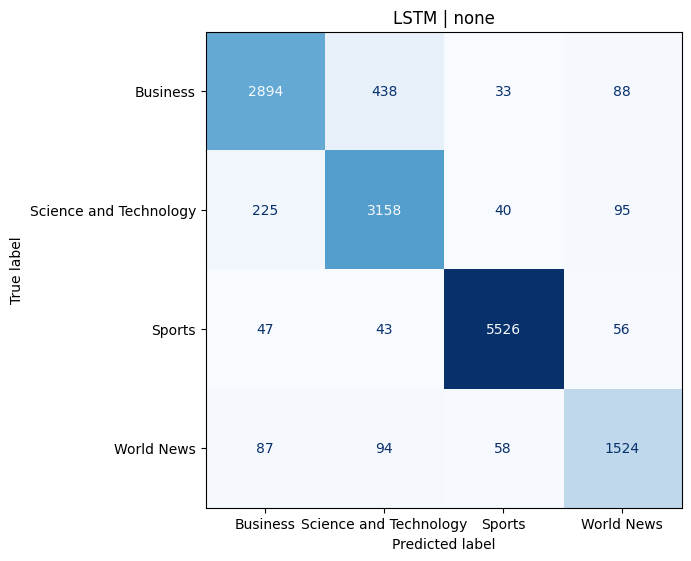

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.8960849645980842, 'macro_f1': 0.8792833254214647}


,precision,recall,f1-score,support
Business,0.847487,0.849696,0.848590,3453.000000
Science and Technology,0.855518,0.855031,0.855274,3518.000000
Sports,0.968274,0.963152,0.965706,5672.000000
World News,0.842105,0.853091,0.847563,1763.000000
accuracy,0.896085,0.896085,0.896085,0.896085
macro avg,0.878346,0.880243,0.879283,14406.000000
weighted avg,0.896346,0.896085,0.896208,14406.000000


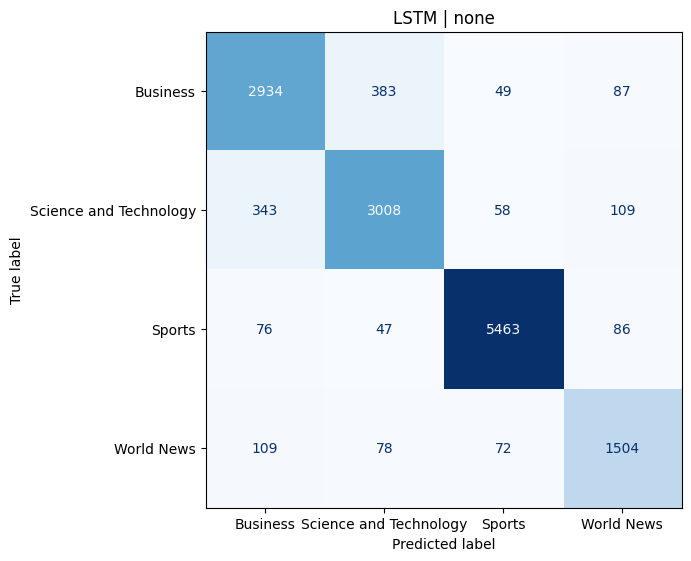

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_LSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.8949049007358045, 'macro_f1': 0.8780017149479453}


,precision,recall,f1-score,support
Business,0.848196,0.851144,0.849668,3453.000000
Science and Technology,0.844469,0.855031,0.849718,3518.000000
Sports,0.972331,0.960331,0.966294,5672.000000
World News,0.842994,0.849688,0.846328,1763.000000
accuracy,0.894905,0.894905,0.894905,0.894905
macro avg,0.876998,0.879049,0.878002,14406.000000
weighted avg,0.895525,0.894905,0.895190,14406.000000


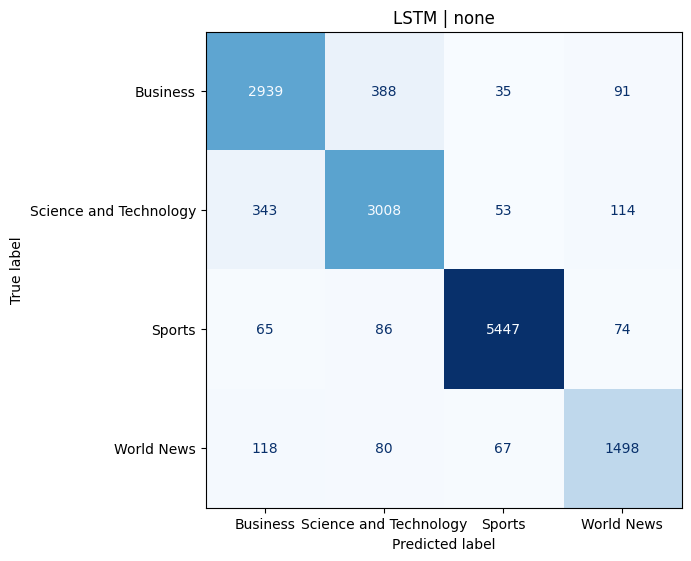

Running BiSimpleRNN on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.12682215743440234, 'macro_f1': 0.06414001016694829}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.607143,0.019329,0.037466,3518.000000
Sports,0.000000,0.000000,0.000000,5672.000000
World News,0.123059,0.997731,0.219094,1763.000000
accuracy,0.126822,0.126822,0.126822,0.126822
macro avg,0.182550,0.254265,0.064140,14406.000000
weighted avg,0.163326,0.126822,0.035962,14406.000000


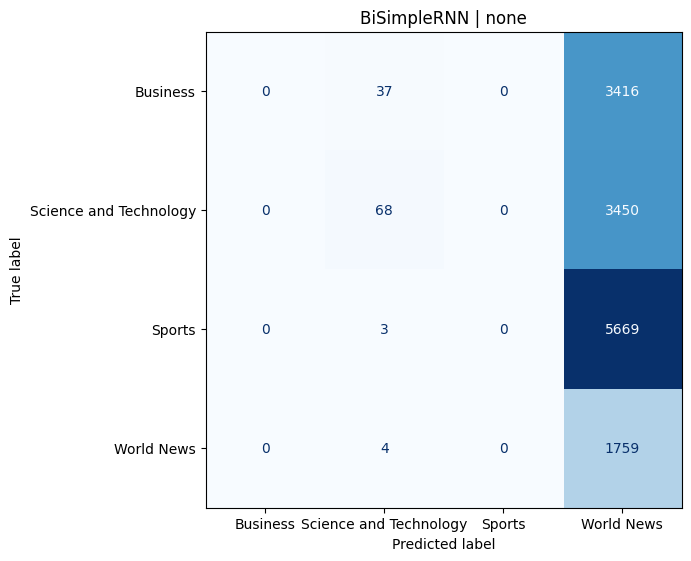

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.6948493683187561, 'macro_f1': 0.635593829980434}


,precision,recall,f1-score,support
Business,0.602386,0.263249,0.366385,3453.000000
Science and Technology,0.514983,0.683911,0.587546,3518.000000
Sports,0.934493,0.928068,0.931269,5672.000000
World News,0.552083,0.811685,0.657176,1763.000000
accuracy,0.694849,0.694849,0.694849,0.694849
macro avg,0.650986,0.671728,0.635594,14406.000000
weighted avg,0.705645,0.694849,0.678389,14406.000000


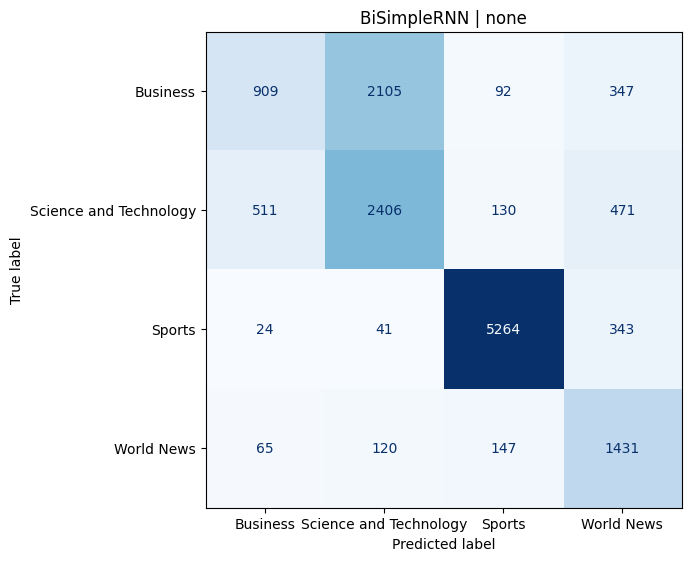

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.8277106761071775, 'macro_f1': 0.804656564491942}


,precision,recall,f1-score,support
Business,0.739095,0.790038,0.763718,3453.000000
Science and Technology,0.768933,0.733087,0.750582,3518.000000
Sports,0.936988,0.928068,0.932507,5672.000000
World News,0.776248,0.767442,0.771820,1763.000000
accuracy,0.827711,0.827711,0.827711,0.827711
macro avg,0.805316,0.804659,0.804657,14406.000000
weighted avg,0.828844,0.827711,0.827958,14406.000000


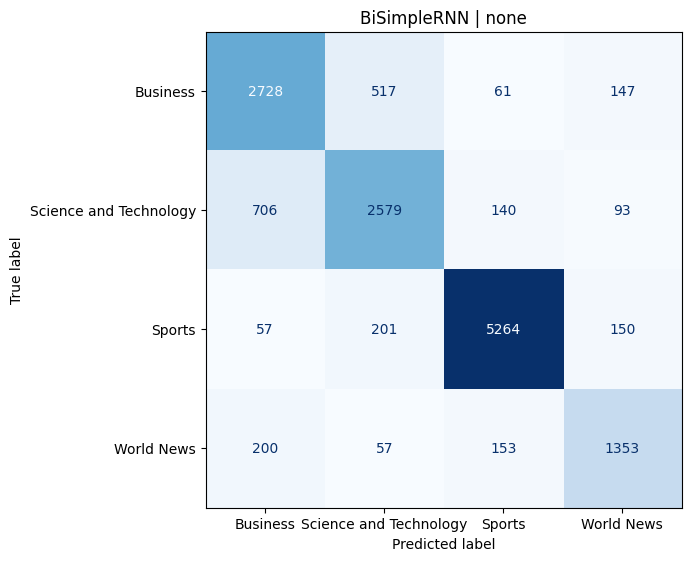

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.6918645009024018, 'macro_f1': 0.6026634619020925}


,precision,recall,f1-score,support
Business,0.475722,0.910802,0.625000,3453.000000
Science and Technology,0.346479,0.034963,0.063517,3518.000000
Sports,0.958128,0.923836,0.940670,5672.000000
World News,0.740233,0.827567,0.781468,1763.000000
accuracy,0.691865,0.691865,0.691865,0.691865
macro avg,0.630141,0.674292,0.602663,14406.000000
weighted avg,0.666466,0.691865,0.631319,14406.000000


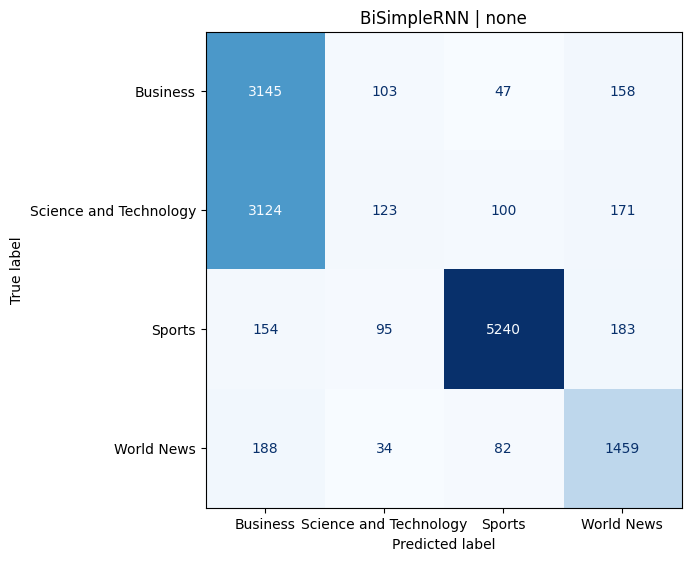

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.24586977648202138, 'macro_f1': 0.1019732182706608}


,precision,recall,f1-score,support
Business,0.896552,0.007530,0.014934,3453.00000
Science and Technology,0.244557,0.999431,0.392959,3518.00000
Sports,0.000000,0.000000,0.000000,5672.00000
World News,0.000000,0.000000,0.000000,1763.00000
accuracy,0.245870,0.245870,0.245870,0.24587
macro avg,0.285277,0.251740,0.101973,14406.00000
weighted avg,0.274618,0.245870,0.099542,14406.00000


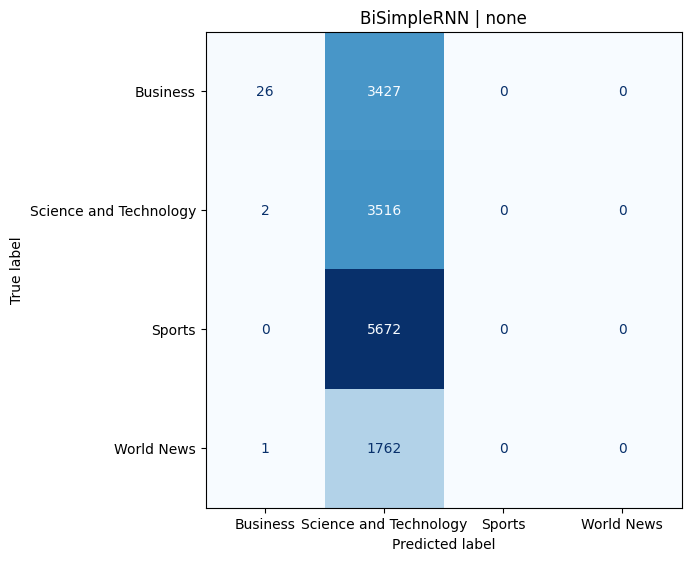

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.12237956407052616, 'macro_f1': 0.05451790463232111}


,precision,recall,f1-score,support
Business,0.000000,0.00000,0.000000,3453.00000
Science and Technology,0.000000,0.00000,0.000000,3518.00000
Sports,0.000000,0.00000,0.000000,5672.00000
World News,0.122380,1.00000,0.218072,1763.00000
accuracy,0.122380,0.12238,0.122380,0.12238
macro avg,0.030595,0.25000,0.054518,14406.00000
weighted avg,0.014977,0.12238,0.026688,14406.00000


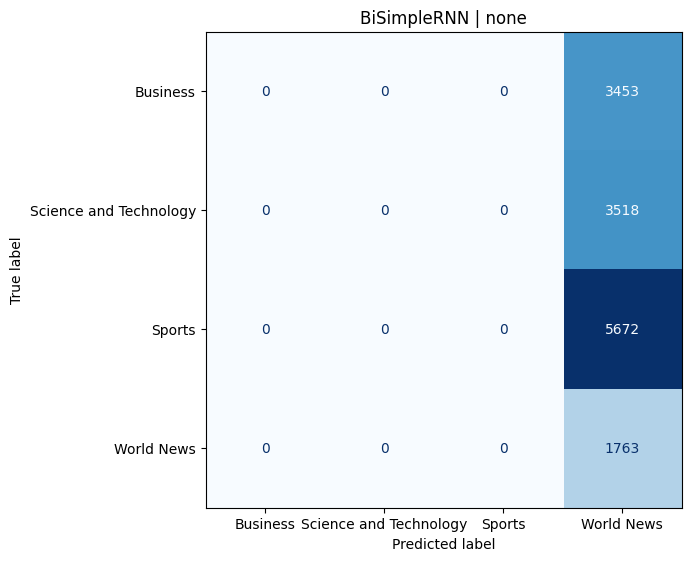

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.6398028599194779, 'macro_f1': 0.5468220851290568}


,precision,recall,f1-score,support
Business,0.485308,0.741384,0.586618,3453.000000
Science and Technology,0.425926,0.098067,0.159427,3518.000000
Sports,0.909575,0.902680,0.906115,5672.000000
World News,0.442793,0.676120,0.535129,1763.000000
accuracy,0.639803,0.639803,0.639803,0.639803
macro avg,0.565901,0.604563,0.546822,14406.000000
weighted avg,0.632648,0.639803,0.601789,14406.000000


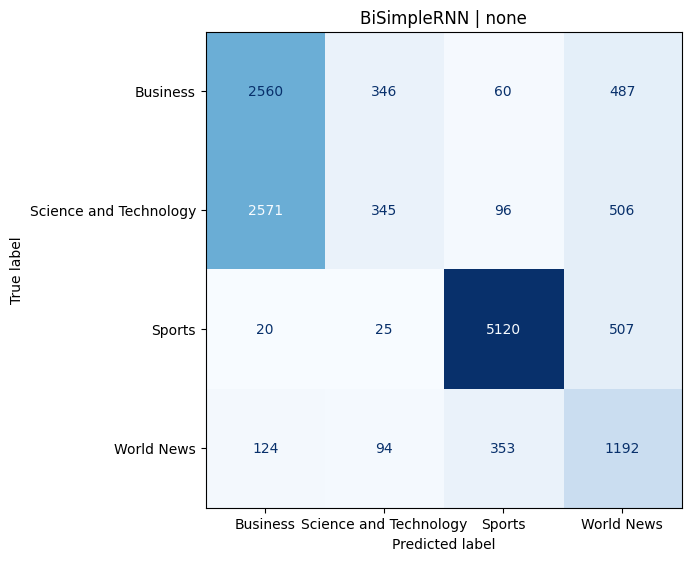

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiSimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.12237956407052616, 'macro_f1': 0.05452127659574468}


,precision,recall,f1-score,support
Business,0.000000,0.00000,0.000000,3453.00000
Science and Technology,0.000000,0.00000,0.000000,3518.00000
Sports,0.000000,0.00000,0.000000,5672.00000
World News,0.122388,1.00000,0.218085,1763.00000
accuracy,0.122380,0.12238,0.122380,0.12238
macro avg,0.030597,0.25000,0.054521,14406.00000
weighted avg,0.014978,0.12238,0.026689,14406.00000


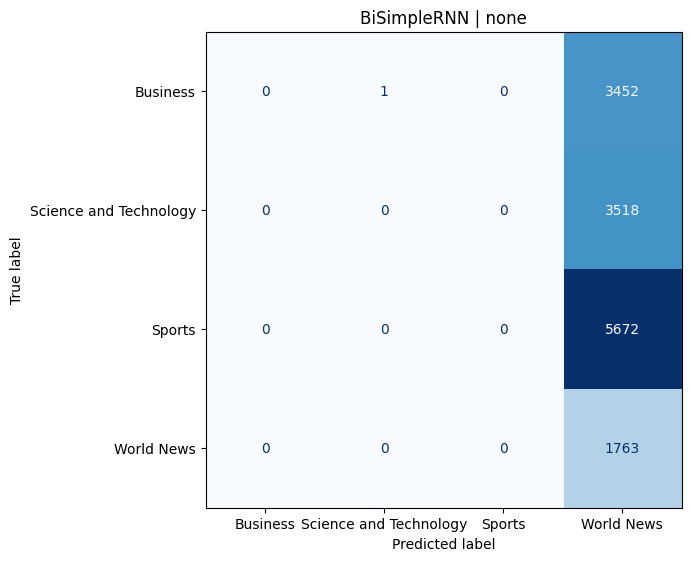

Running BiGRU on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9040677495487991, 'macro_f1': 0.8874602487402076}


,precision,recall,f1-score,support
Business,0.882478,0.841587,0.861548,3453.000000
Science and Technology,0.847926,0.889142,0.868045,3518.000000
Sports,0.981602,0.959450,0.970399,5672.000000
World News,0.823404,0.878049,0.849849,1763.000000
accuracy,0.904068,0.904068,0.904068,0.904068
macro avg,0.883853,0.892057,0.887460,14406.000000
weighted avg,0.905838,0.904068,0.904560,14406.000000


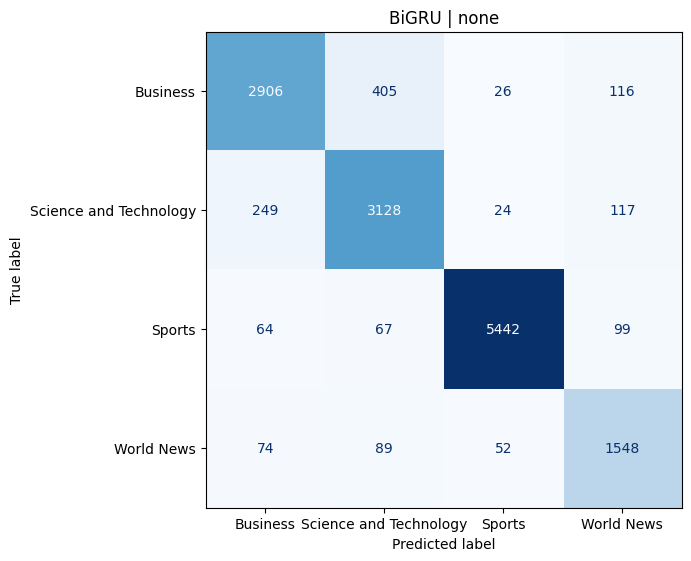

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9113563792864084, 'macro_f1': 0.8956643125096252}


,precision,recall,f1-score,support
Business,0.896160,0.844773,0.869708,3453.000000
Science and Technology,0.861058,0.893121,0.876796,3518.000000
Sports,0.976245,0.970910,0.973570,5672.000000
World News,0.839871,0.886557,0.862583,1763.000000
accuracy,0.911356,0.911356,0.911356,0.911356
macro avg,0.893333,0.898840,0.895664,14406.000000
weighted avg,0.912231,0.911356,0.911460,14406.000000


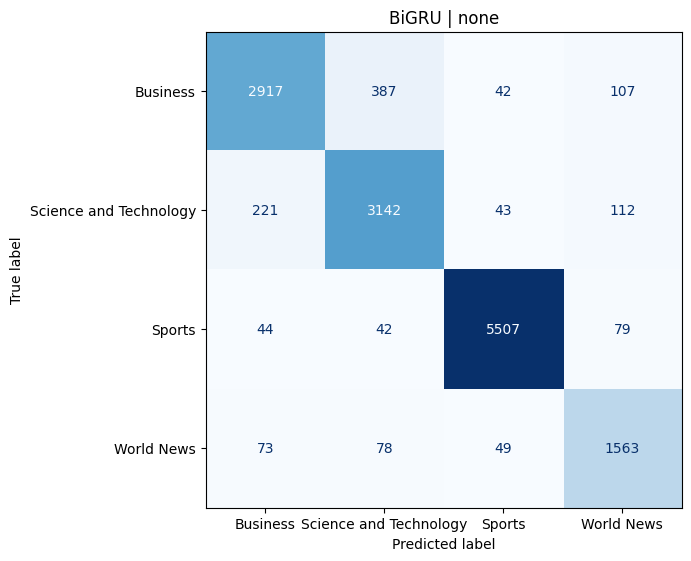

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9022629459947245, 'macro_f1': 0.8849893619928042}


,precision,recall,f1-score,support
Business,0.887246,0.834057,0.859830,3453.000000
Science and Technology,0.844879,0.884025,0.864009,3518.000000
Sports,0.976940,0.963505,0.970176,5672.000000
World News,0.818568,0.875213,0.845943,1763.000000
accuracy,0.902263,0.902263,0.902263,0.902263
macro avg,0.881908,0.889200,0.884989,14406.000000
weighted avg,0.903810,0.902263,0.902597,14406.000000


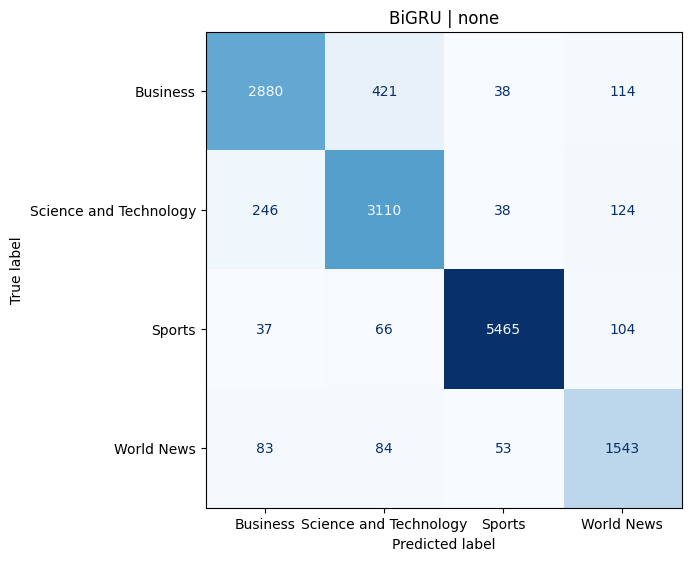

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9033041788143829, 'macro_f1': 0.8865501154089793}


,precision,recall,f1-score,support
Business,0.871246,0.848538,0.859742,3453.000000
Science and Technology,0.852730,0.878908,0.865622,3518.000000
Sports,0.969986,0.968618,0.969301,5672.000000
World News,0.853965,0.849121,0.851536,1763.000000
accuracy,0.903304,0.903304,0.903304,0.903304
macro avg,0.886982,0.886296,0.886550,14406.000000
weighted avg,0.903486,0.903304,0.903310,14406.000000


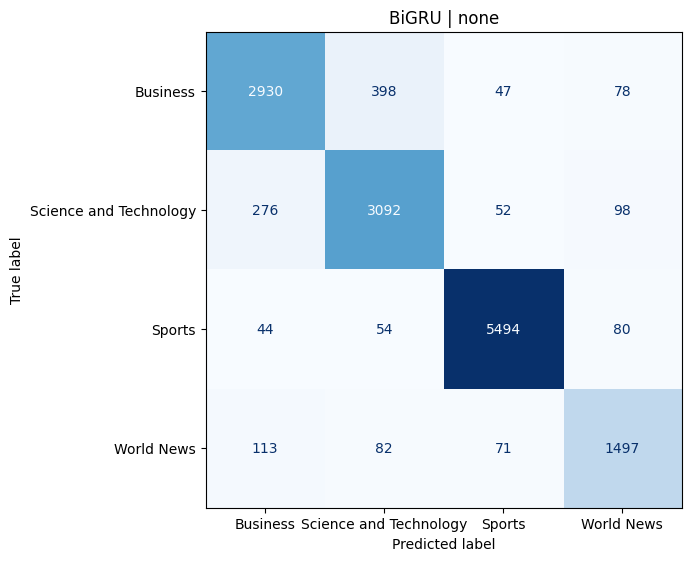

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.903443009857004, 'macro_f1': 0.8868611029192527}


,precision,recall,f1-score,support
Business,0.877600,0.843035,0.859970,3453.000000
Science and Technology,0.852909,0.883457,0.867914,3518.000000
Sports,0.977591,0.961389,0.969422,5672.000000
World News,0.826460,0.875213,0.850138,1763.000000
accuracy,0.903443,0.903443,0.903443,0.903443
macro avg,0.883640,0.890773,0.886861,14406.000000
weighted avg,0.904681,0.903443,0.903801,14406.000000


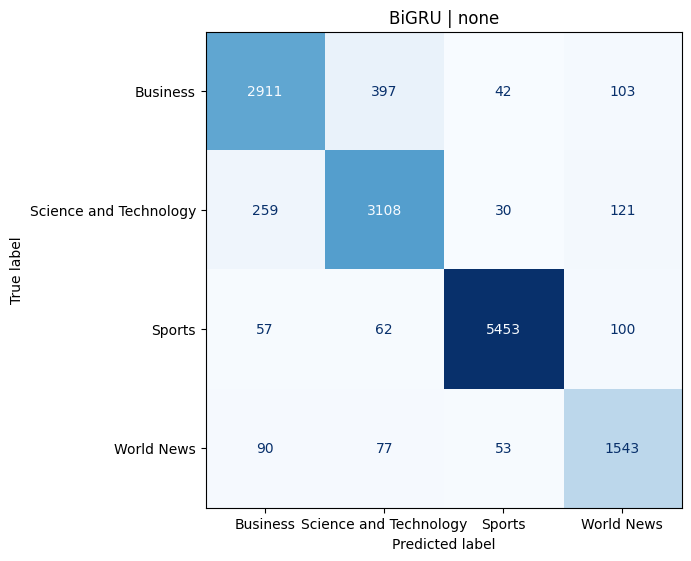

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.907746772178259, 'macro_f1': 0.8917358899629881}


,precision,recall,f1-score,support
Business,0.883023,0.852592,0.867541,3453.000000
Science and Technology,0.867227,0.880045,0.873589,3518.000000
Sports,0.979197,0.962623,0.970839,5672.000000
World News,0.818795,0.894498,0.854974,1763.000000
accuracy,0.907747,0.907747,0.907747,0.907747
macro avg,0.887061,0.897440,0.891736,14406.000000
weighted avg,0.909171,0.907747,0.908151,14406.000000


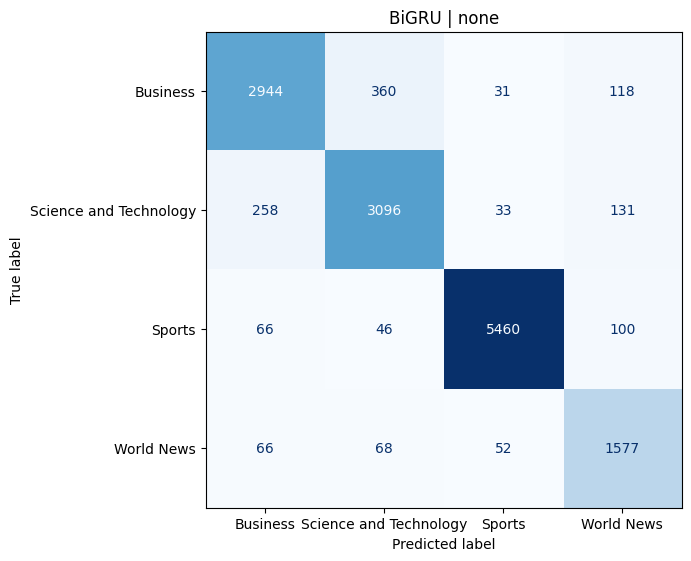

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.8974732750242954, 'macro_f1': 0.881396776896404}


,precision,recall,f1-score,support
Business,0.874924,0.832609,0.853242,3453.000000
Science and Technology,0.827923,0.891700,0.858629,3518.000000
Sports,0.983017,0.949048,0.965734,5672.000000
World News,0.826954,0.870108,0.847982,1763.000000
accuracy,0.897473,0.897473,0.897473,0.897473
macro avg,0.878204,0.885866,0.881397,14406.000000
weighted avg,0.900134,0.897473,0.898205,14406.000000


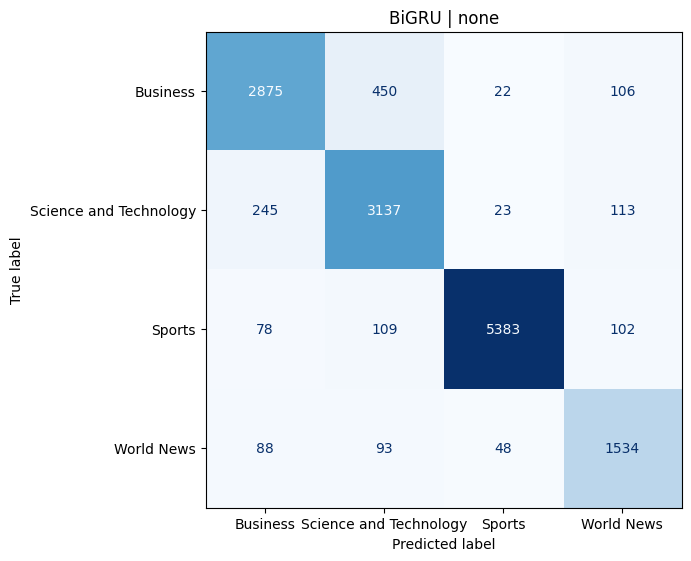

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiGRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9000416493127863, 'macro_f1': 0.8823356357194152}


,precision,recall,f1-score,support
Business,0.893404,0.827686,0.859290,3453.000000
Science and Technology,0.845051,0.888289,0.866131,3518.000000
Sports,0.978175,0.956100,0.967011,5672.000000
World News,0.793893,0.884855,0.836910,1763.000000
accuracy,0.900042,0.900042,0.900042,0.900042
macro avg,0.877631,0.889233,0.882336,14406.000000
weighted avg,0.902794,0.900042,0.900634,14406.000000


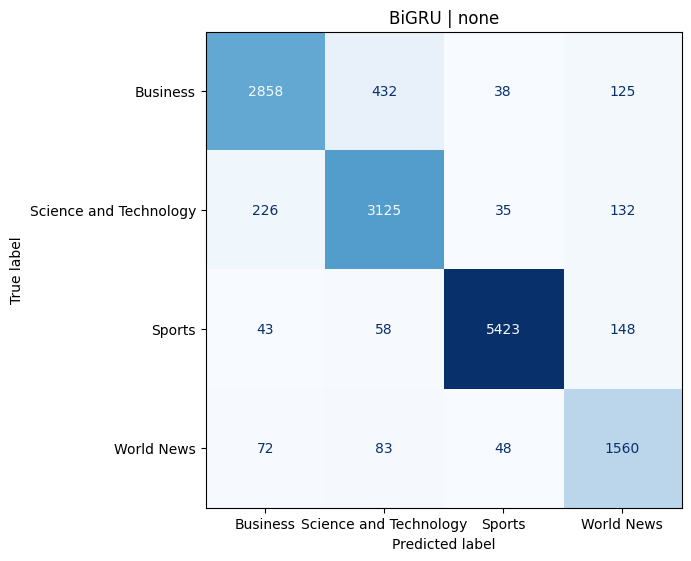

Running BiLSTM on none
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9098986533388865, 'macro_f1': 0.8942572126621624}


,precision,recall,f1-score,support
Business,0.877863,0.865914,0.871847,3453.000000
Science and Technology,0.867808,0.878908,0.873323,3518.000000
Sports,0.975306,0.967913,0.971595,5672.000000
World News,0.849558,0.871242,0.860263,1763.000000
accuracy,0.909899,0.909899,0.909899,0.909899
macro avg,0.892634,0.895994,0.894257,14406.000000
weighted avg,0.910309,0.909899,0.910063,14406.000000


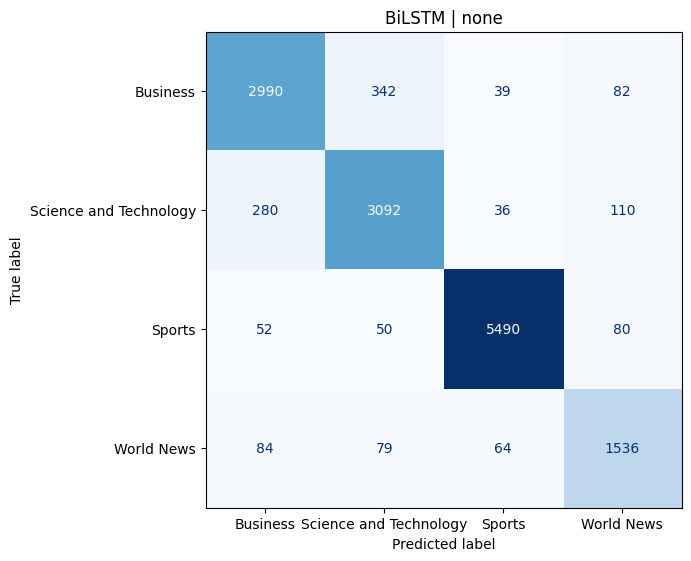

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9145494932666944, 'macro_f1': 0.8990526666868958}


,precision,recall,f1-score,support
Business,0.891045,0.864466,0.877554,3453.000000
Science and Technology,0.869433,0.893405,0.881256,3518.000000
Sports,0.979679,0.968970,0.974295,5672.000000
World News,0.847078,0.879750,0.863105,1763.000000
accuracy,0.914549,0.914549,0.914549,0.914549
macro avg,0.896809,0.901648,0.899053,14406.000000
weighted avg,0.915284,0.914549,0.914779,14406.000000


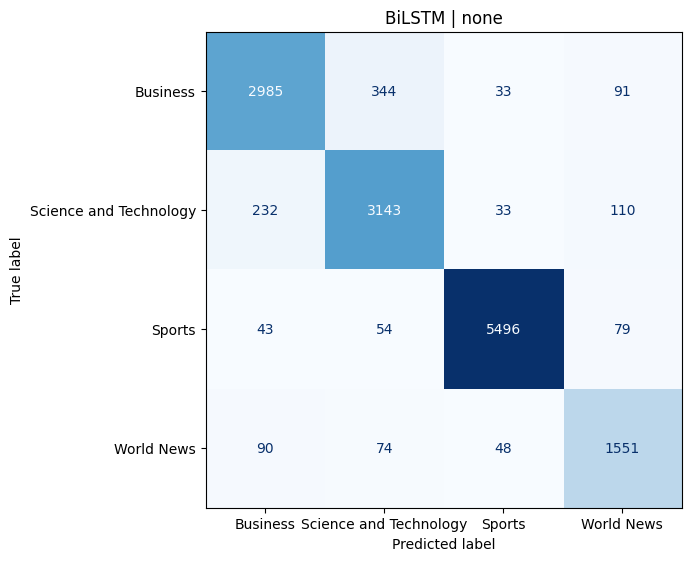

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9003193113980286, 'macro_f1': 0.8827680156508213}


,precision,recall,f1-score,support
Business,0.864078,0.850565,0.857268,3453.000000
Science and Technology,0.868226,0.865264,0.866743,3518.000000
Sports,0.975099,0.959626,0.967301,5672.000000
World News,0.805628,0.876914,0.839761,1763.000000
accuracy,0.900319,0.900319,0.900319,0.900319
macro avg,0.878258,0.888092,0.882768,14406.000000
weighted avg,0.901649,0.900319,0.900762,14406.000000


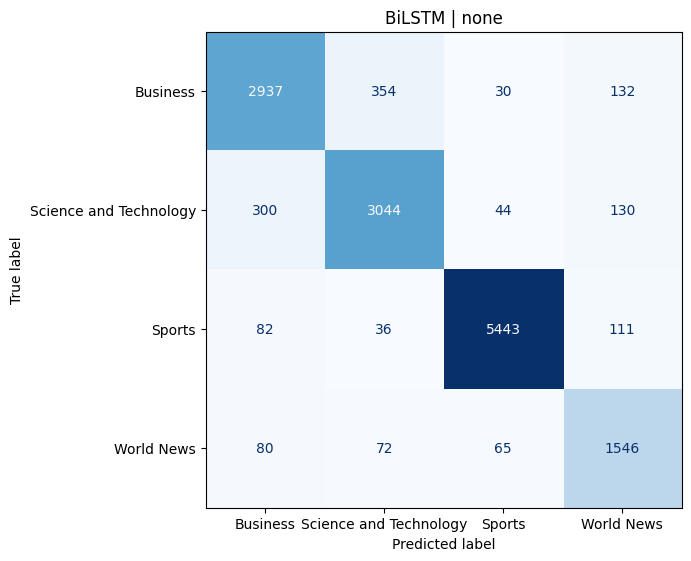

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9071914480077745, 'macro_f1': 0.8898359349544318}


,precision,recall,f1-score,support
Business,0.893020,0.848538,0.870211,3453.000000
Science and Technology,0.869345,0.879477,0.874382,3518.000000
Sports,0.978518,0.963681,0.971043,5672.000000
World News,0.797475,0.895632,0.843708,1763.000000
accuracy,0.907191,0.907191,0.907191,0.907191
macro avg,0.884590,0.896832,0.889836,14406.000000
weighted avg,0.909208,0.907191,0.907686,14406.000000


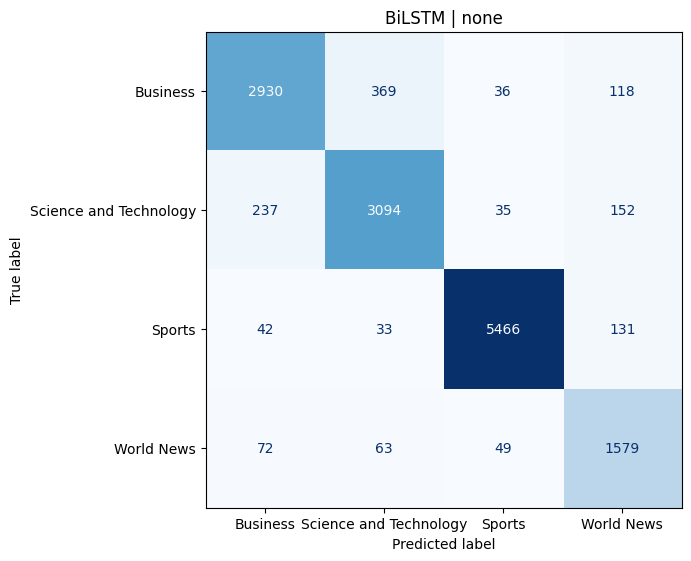

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.906011384145495, 'macro_f1': 0.8898671687357842}


,precision,recall,f1-score,support
Business,0.863427,0.869679,0.866542,3453.000000
Science and Technology,0.858538,0.874645,0.866516,3518.000000
Sports,0.977313,0.964563,0.970896,5672.000000
World News,0.859679,0.851390,0.855514,1763.000000
accuracy,0.906011,0.906011,0.906011,0.906011
macro avg,0.889739,0.890069,0.889867,14406.000000
weighted avg,0.906614,0.906011,0.906273,14406.000000


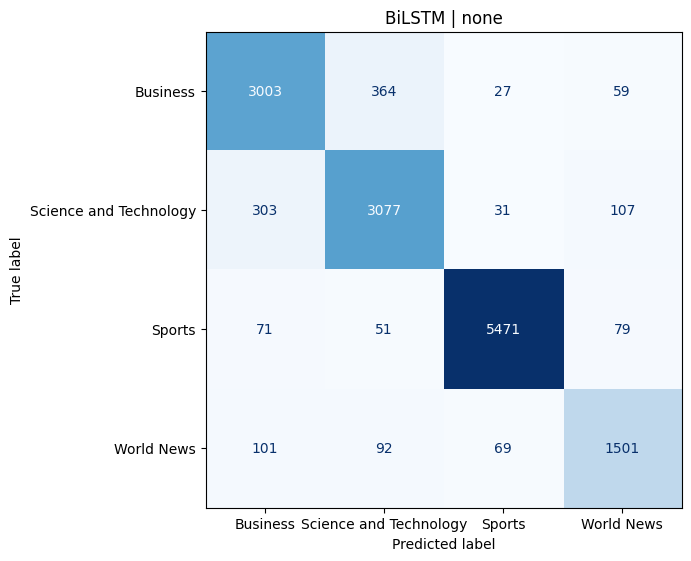

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9101763154241288, 'macro_f1': 0.8939616587308583}


,precision,recall,f1-score,support
Business,0.893095,0.854040,0.873131,3453.000000
Science and Technology,0.864595,0.885731,0.875035,3518.000000
Sports,0.977030,0.967384,0.972183,5672.000000
World News,0.828025,0.884855,0.855498,1763.000000
accuracy,0.910176,0.910176,0.910176,0.910176
macro avg,0.890686,0.898002,0.893962,14406.000000
weighted avg,0.911219,0.910176,0.910437,14406.000000


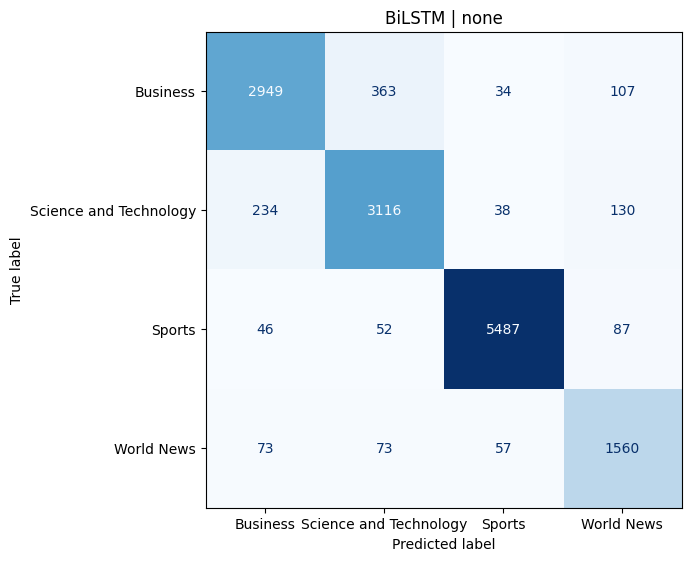

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.8956684714702208, 'macro_f1': 0.8770428026011906}


,precision,recall,f1-score,support
Business,0.883553,0.815233,0.848019,3453.000000
Science and Technology,0.842479,0.877203,0.859490,3518.000000
Sports,0.974428,0.960684,0.967507,5672.000000
World News,0.790331,0.880885,0.833155,1763.000000
accuracy,0.895668,0.895668,0.895668,0.895668
macro avg,0.872698,0.883501,0.877043,14406.000000
weighted avg,0.897894,0.895668,0.896047,14406.000000


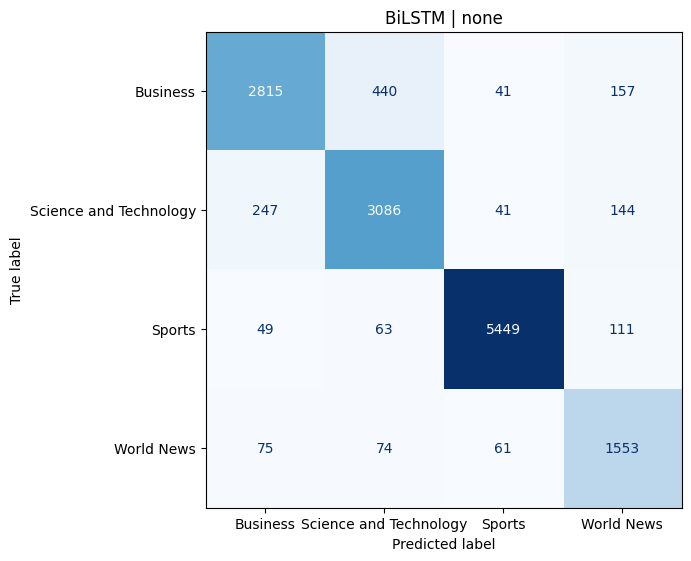

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_none_BiLSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.906011384145495, 'macro_f1': 0.8890794538228818}


,precision,recall,f1-score,support
Business,0.873972,0.861570,0.867726,3453.000000
Science and Technology,0.870625,0.862706,0.866648,3518.000000
Sports,0.976161,0.967384,0.971752,5672.000000
World News,0.820580,0.882019,0.850191,1763.000000
accuracy,0.906011,0.906011,0.906011,0.906011
macro avg,0.885335,0.893420,0.889079,14406.000000
weighted avg,0.906855,0.906011,0.906275,14406.000000


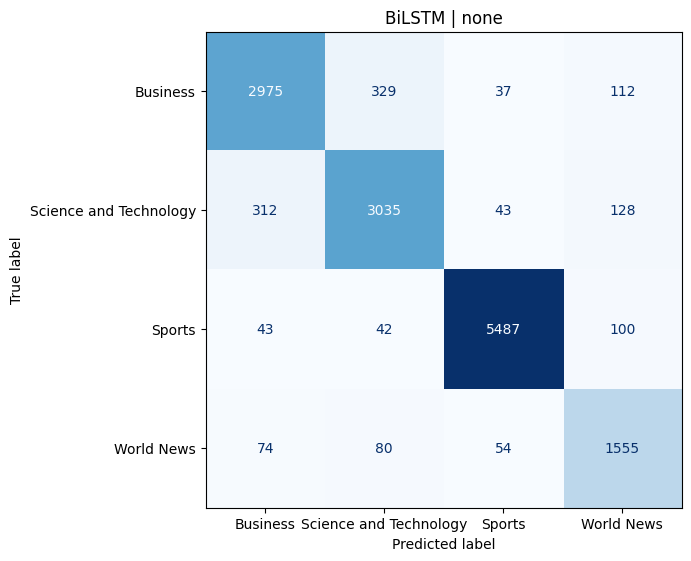

Loaded cached skip-gram inputs for extreme
Running SimpleRNN on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.6934610578925448, 'macro_f1': 0.6570184737994915}


,precision,recall,f1-score,support
Business,0.662672,0.544454,0.597774,3453.000000
Science and Technology,0.684277,0.614838,0.647702,3518.000000
Sports,0.809573,0.834979,0.822080,5672.000000
World News,0.473417,0.686897,0.560518,1763.000000
accuracy,0.693461,0.693461,0.693461,0.693461
macro avg,0.657485,0.670292,0.657018,14406.000000
weighted avg,0.702625,0.693461,0.693722,14406.000000


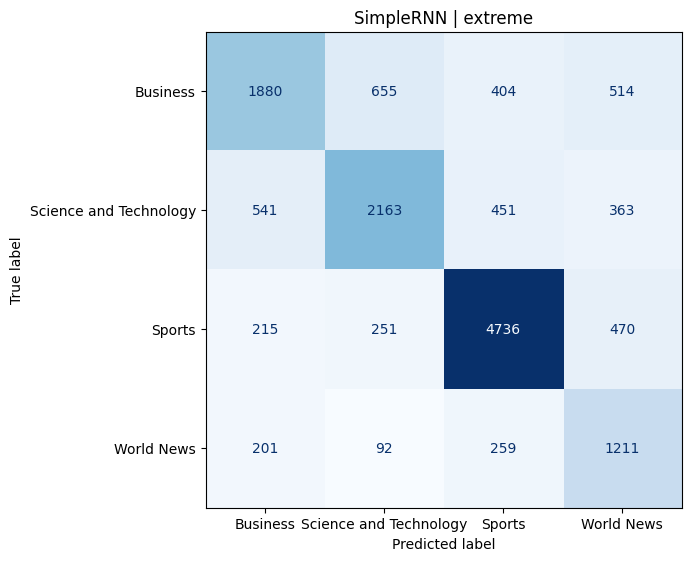

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.8232680827433014, 'macro_f1': 0.7968273048688818}


,precision,recall,f1-score,support
Business,0.750232,0.701129,0.724850,3453.000000
Science and Technology,0.775214,0.745026,0.759820,3518.000000
Sports,0.919415,0.953456,0.936126,5672.000000
World News,0.735908,0.799773,0.766513,1763.000000
accuracy,0.823268,0.823268,0.823268,0.823268
macro avg,0.795193,0.799846,0.796827,14406.000000
weighted avg,0.821192,0.823268,0.821673,14406.000000


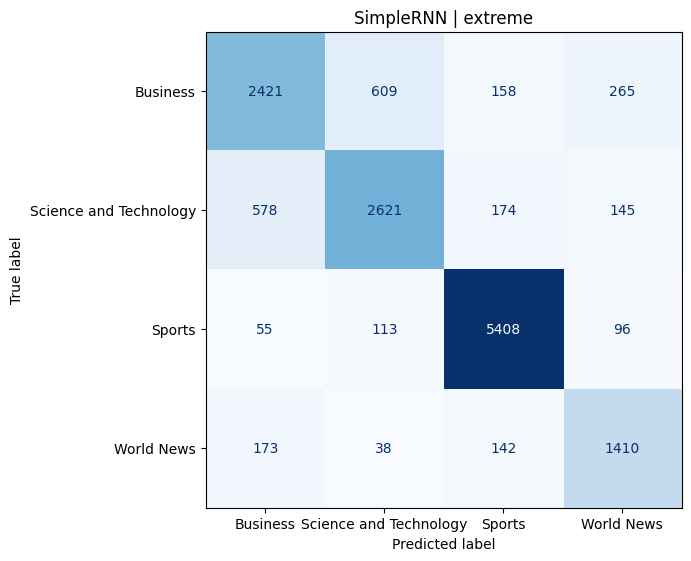

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.7848118839372483, 'macro_f1': 0.7620950895857244}


,precision,recall,f1-score,support
Business,0.713031,0.728931,0.720894,3453.000000
Science and Technology,0.674876,0.732234,0.702386,3518.000000
Sports,0.967059,0.854020,0.907031,5672.000000
World News,0.667805,0.776517,0.718070,1763.000000
accuracy,0.784812,0.784812,0.784812,0.784812
macro avg,0.755693,0.772926,0.762095,14406.000000
weighted avg,0.798196,0.784812,0.789315,14406.000000


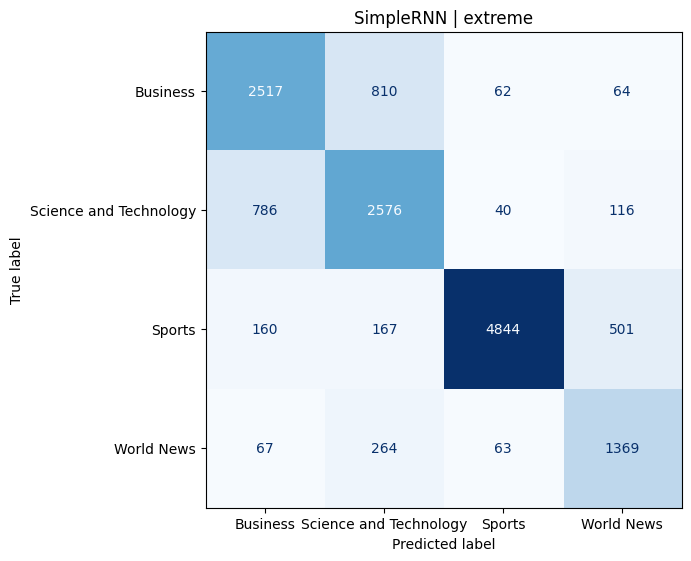

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.3147993891434125, 'macro_f1': 0.23454950987139372}


,precision,recall,f1-score,support
Business,0.491678,0.855488,0.624458,3453.000000
Science and Technology,0.250000,0.001137,0.002264,3518.000000
Sports,0.071429,0.000176,0.000352,5672.000000
World News,0.188337,0.893931,0.311124,1763.000000
accuracy,0.314799,0.314799,0.314799,0.314799
macro avg,0.250361,0.437683,0.234550,14406.000000
weighted avg,0.230074,0.314799,0.188444,14406.000000


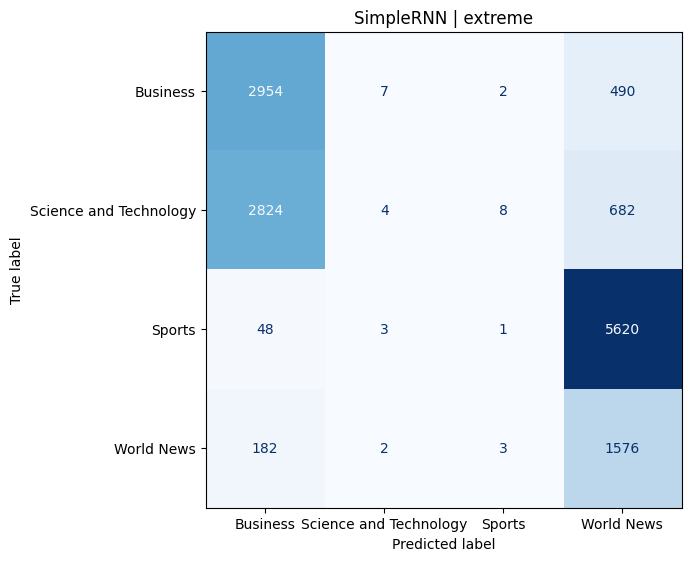

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.6097459391920034, 'macro_f1': 0.5224083857812334}


,precision,recall,f1-score,support
Business,0.498706,0.502172,0.500433,3453.000000
Science and Technology,0.568830,0.328880,0.416787,3518.000000
Sports,0.719696,0.934767,0.813253,5672.000000
World News,0.386780,0.335224,0.359161,1763.000000
accuracy,0.609746,0.609746,0.609746,0.609746
macro avg,0.543503,0.525261,0.522408,14406.000000
weighted avg,0.589142,0.609746,0.585882,14406.000000


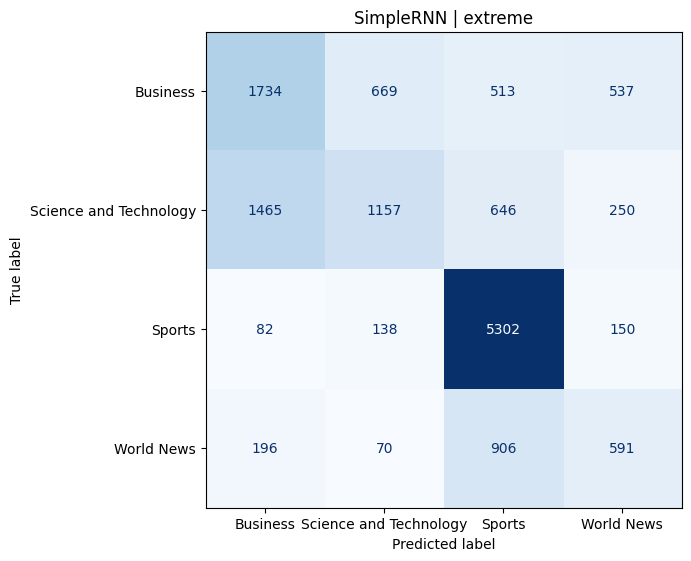

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.706025267249757, 'macro_f1': 0.673450102737829}


,precision,recall,f1-score,support
Business,0.580268,0.790327,0.669201,3453.000000
Science and Technology,0.768868,0.509665,0.612991,3518.000000
Sports,0.977594,0.769217,0.860977,5672.000000
World News,0.442228,0.729438,0.550632,1763.000000
accuracy,0.706025,0.706025,0.706025,0.706025
macro avg,0.692239,0.699662,0.673450,14406.000000
weighted avg,0.765869,0.706025,0.716471,14406.000000


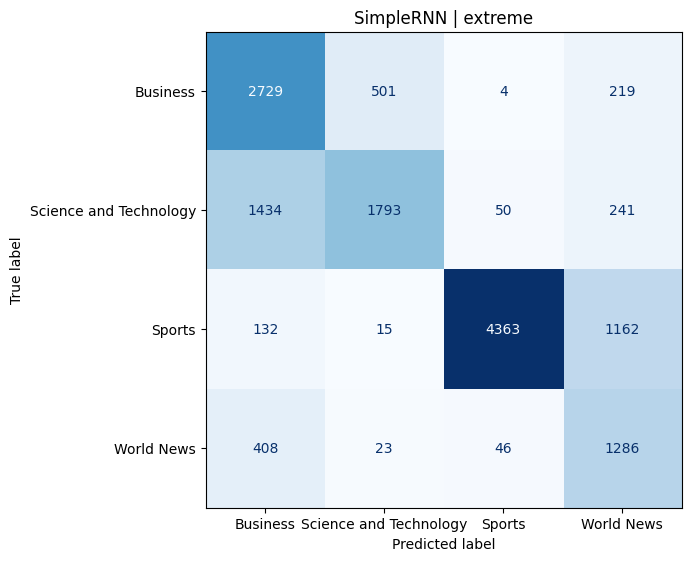

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.12328196584756351, 'macro_f1': 0.05652171049259397}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.875000,0.003980,0.007923,3518.000000
Sports,0.000000,0.000000,0.000000,5672.000000
World News,0.122446,0.999433,0.218164,1763.000000
accuracy,0.123282,0.123282,0.123282,0.123282
macro avg,0.249362,0.250853,0.056522,14406.000000
weighted avg,0.228663,0.123282,0.028634,14406.000000


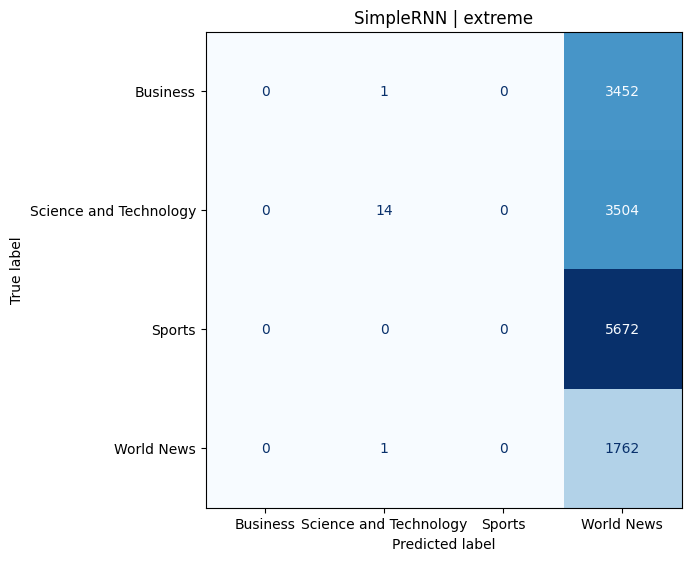

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_SimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.6146744412050534, 'macro_f1': 0.508609884291241}


,precision,recall,f1-score,support
Business,0.441853,0.795540,0.568149,3453.000000
Science and Technology,0.000000,0.000000,0.000000,3518.000000
Sports,0.814615,0.852962,0.833348,5672.000000
World News,0.564444,0.720363,0.632943,1763.000000
accuracy,0.614674,0.614674,0.614674,0.614674
macro avg,0.455228,0.592216,0.508610,14406.000000
weighted avg,0.495719,0.614674,0.541750,14406.000000


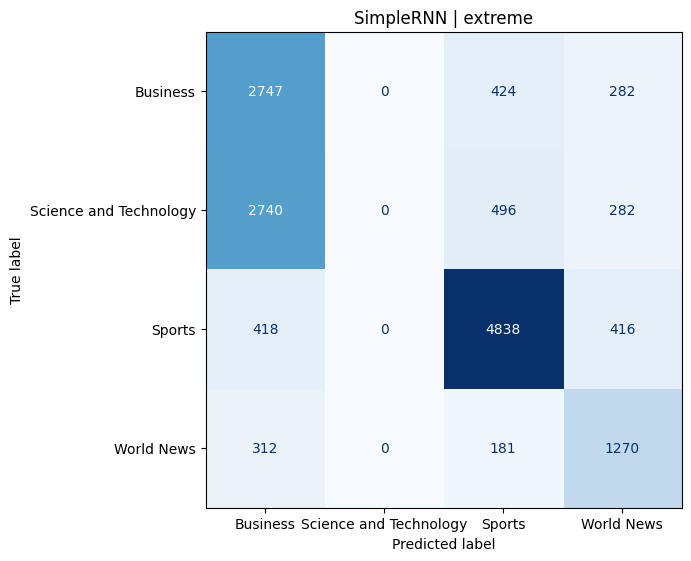

Running GRU on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9259336387616272, 'macro_f1': 0.9117837607202521}


,precision,recall,f1-score,support
Business,0.889571,0.881842,0.885689,3453.000000
Science and Technology,0.886835,0.899943,0.893341,3518.000000
Sports,0.980870,0.985367,0.983113,5672.000000
World News,0.897376,0.872944,0.884991,1763.000000
accuracy,0.925934,0.925934,0.925934,0.925934
macro avg,0.913663,0.910024,0.911784,14406.000000
weighted avg,0.925805,0.925934,0.925831,14406.000000


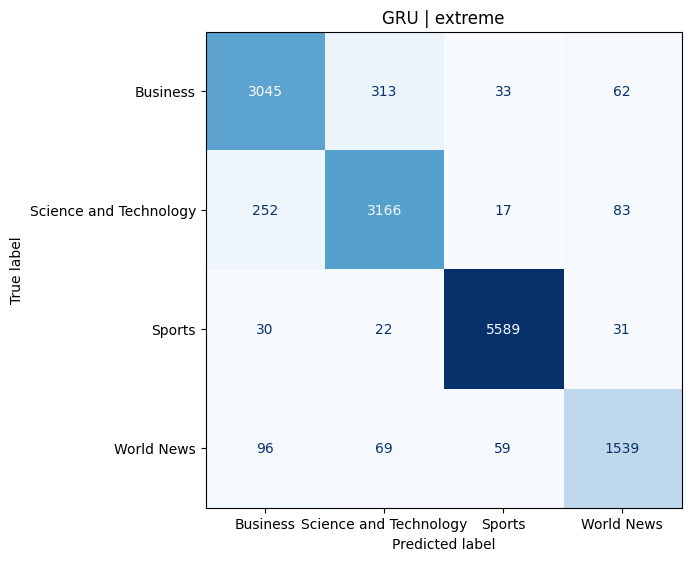

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9235735110370679, 'macro_f1': 0.9093144293776774}


,precision,recall,f1-score,support
Business,0.881813,0.890240,0.886007,3453.000000
Science and Technology,0.894311,0.880330,0.887265,3518.000000
Sports,0.983554,0.980606,0.982078,5672.000000
World News,0.872364,0.891662,0.881907,1763.000000
accuracy,0.923574,0.923574,0.923574,0.923574
macro avg,0.908011,0.910710,0.909314,14406.000000
weighted avg,0.923767,0.923574,0.923638,14406.000000


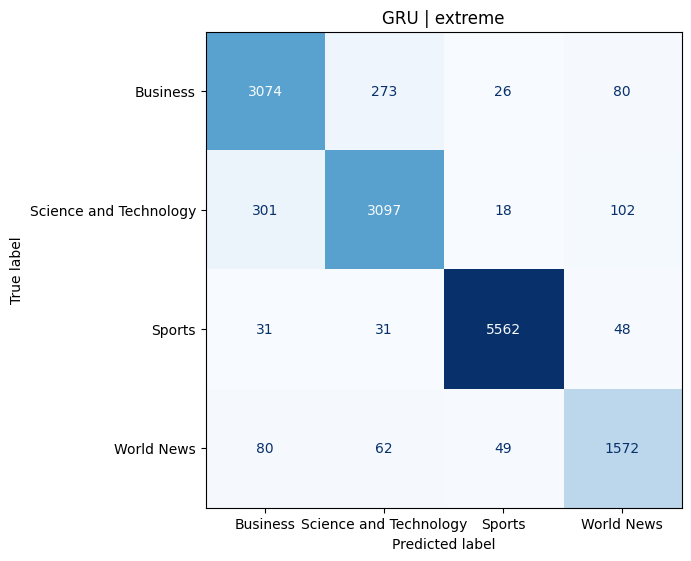

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9243370817714841, 'macro_f1': 0.9100892383292786}


,precision,recall,f1-score,support
Business,0.898468,0.866203,0.882041,3453.000000
Science and Technology,0.879368,0.901364,0.890230,3518.000000
Sports,0.979688,0.986425,0.983045,5672.000000
World News,0.885795,0.884288,0.885041,1763.000000
accuracy,0.924337,0.924337,0.924337,0.924337
macro avg,0.910830,0.909570,0.910089,14406.000000
weighted avg,0.924231,0.924337,0.924176,14406.000000


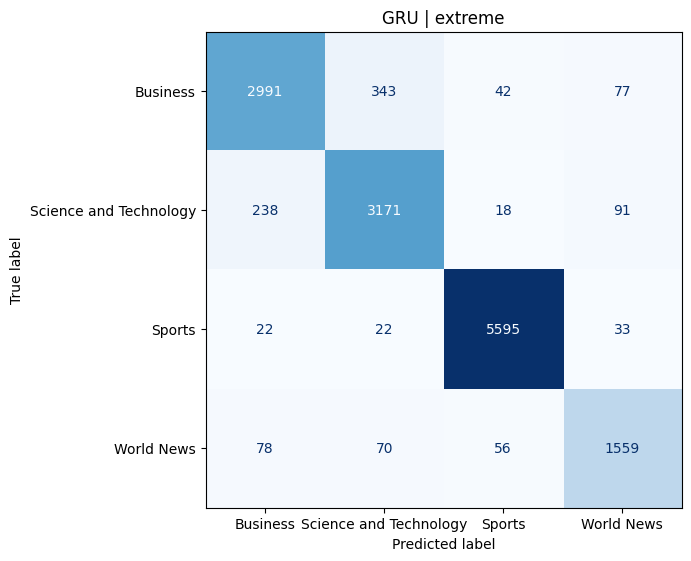

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9275996112730807, 'macro_f1': 0.913991130514747}


,precision,recall,f1-score,support
Business,0.894599,0.887344,0.890957,3453.0000
Science and Technology,0.891716,0.896532,0.894118,3518.0000
Sports,0.983416,0.982722,0.983069,5672.0000
World News,0.884572,0.891095,0.887821,1763.0000
accuracy,0.927600,0.927600,0.927600,0.9276
macro avg,0.913576,0.914423,0.913991,14406.0000
weighted avg,0.927637,0.927600,0.927612,14406.0000


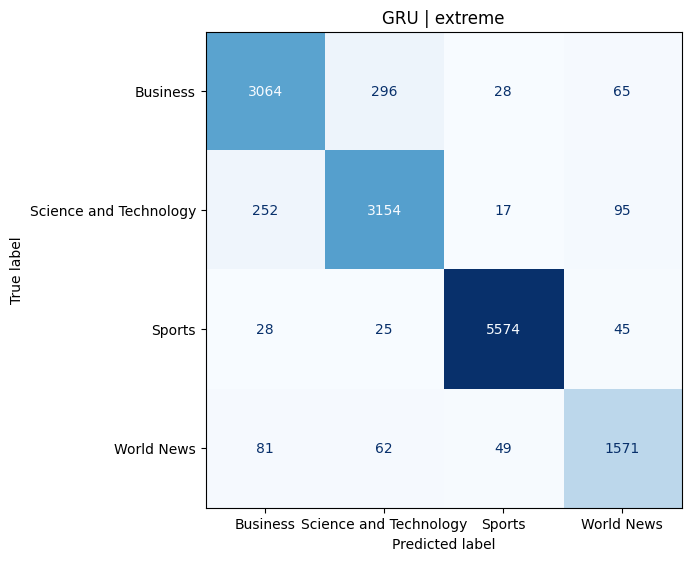

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9220463695682355, 'macro_f1': 0.9082041560997027}


,precision,recall,f1-score,support
Business,0.878359,0.880394,0.879375,3453.000000
Science and Technology,0.883523,0.884025,0.883774,3518.000000
Sports,0.976797,0.987130,0.981936,5672.000000
World News,0.906084,0.870108,0.887731,1763.000000
accuracy,0.922046,0.922046,0.922046,0.922046
macro avg,0.911191,0.905414,0.908204,14406.000000
weighted avg,0.921770,0.922046,0.921853,14406.000000


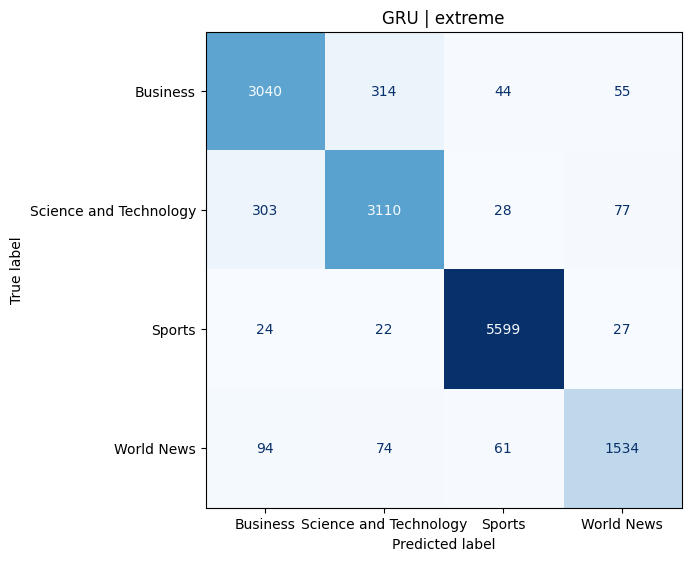

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9244064972927947, 'macro_f1': 0.910090155117881}


,precision,recall,f1-score,support
Business,0.886072,0.880683,0.883370,3453.000000
Science and Technology,0.888260,0.892553,0.890401,3518.000000
Sports,0.984624,0.982193,0.983407,5672.000000
World News,0.878720,0.887691,0.883183,1763.000000
accuracy,0.924406,0.924406,0.924406,0.924406
macro avg,0.909419,0.910780,0.910090,14406.000000
weighted avg,0.924509,0.924406,0.924451,14406.000000


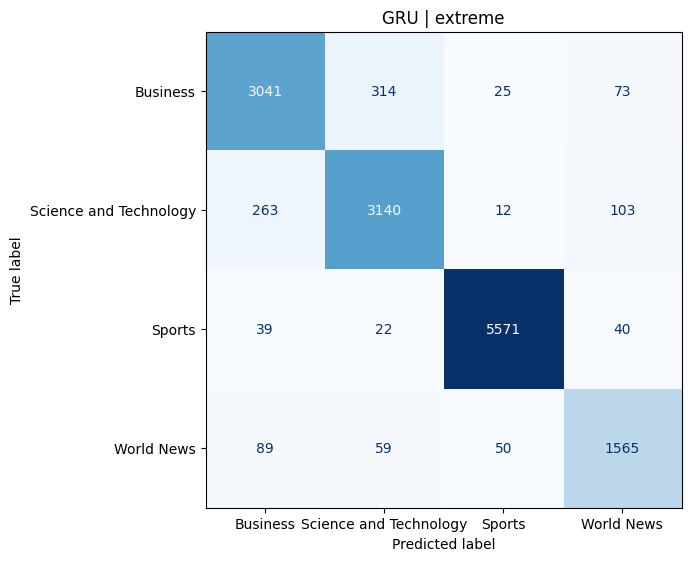

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9221852006108566, 'macro_f1': 0.9074634820049866}


,precision,recall,f1-score,support
Business,0.894753,0.864176,0.879199,3453.000000
Science and Technology,0.873348,0.901649,0.887273,3518.000000
Sports,0.984787,0.981488,0.983135,5672.000000
World News,0.874580,0.885990,0.880248,1763.000000
accuracy,0.922185,0.922185,0.922185,0.922185
macro avg,0.906867,0.908326,0.907463,14406.000000
weighted avg,0.922506,0.922185,0.922221,14406.000000


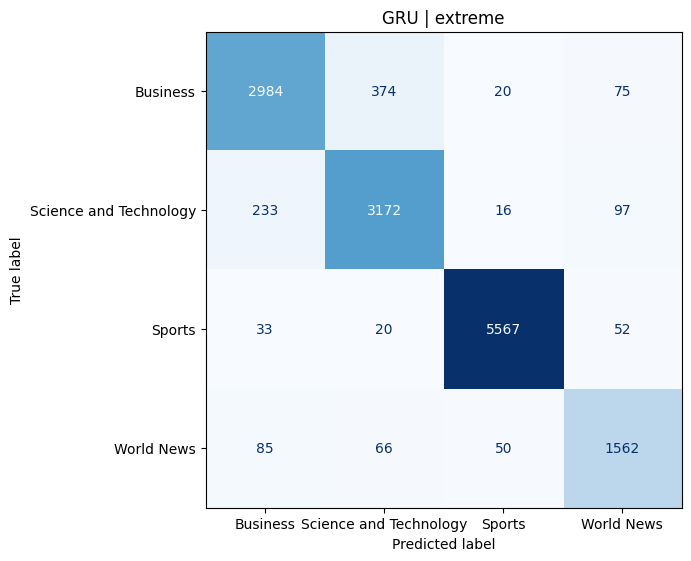

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_GRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9254477301124532, 'macro_f1': 0.9114327990138187}


,precision,recall,f1-score,support
Business,0.877452,0.893716,0.885509,3453.000000
Science and Technology,0.896731,0.881182,0.888889,3518.000000
Sports,0.984141,0.984661,0.984401,5672.000000
World News,0.888446,0.885423,0.886932,1763.000000
accuracy,0.925448,0.925448,0.925448,0.925448
macro avg,0.911693,0.911246,0.911433,14406.000000
weighted avg,0.925512,0.925448,0.925445,14406.000000


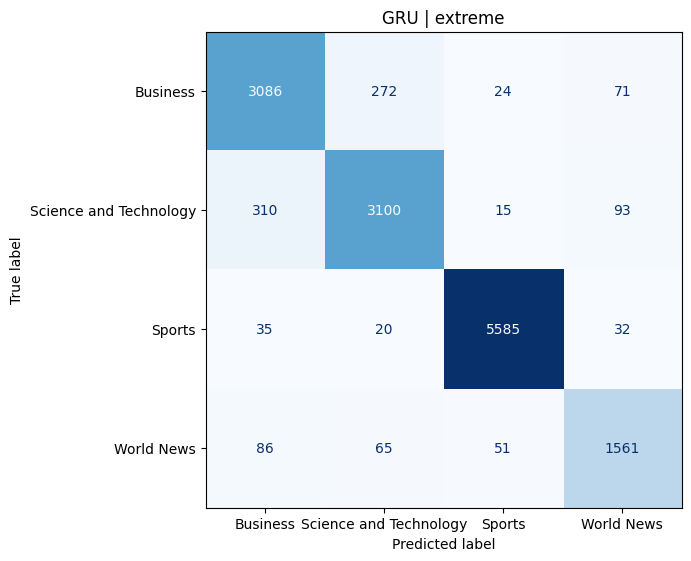

Running LSTM on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9235735110370679, 'macro_f1': 0.9091304877858705}


,precision,recall,f1-score,support
Business,0.877364,0.886765,0.882039,3453.000000
Science and Technology,0.886744,0.888005,0.887374,3518.000000
Sports,0.981563,0.985543,0.983549,5672.000000
World News,0.900471,0.867272,0.883560,1763.000000
accuracy,0.923574,0.923574,0.923574,0.923574
macro avg,0.911536,0.906896,0.909130,14406.000000
weighted avg,0.923508,0.923574,0.923495,14406.000000


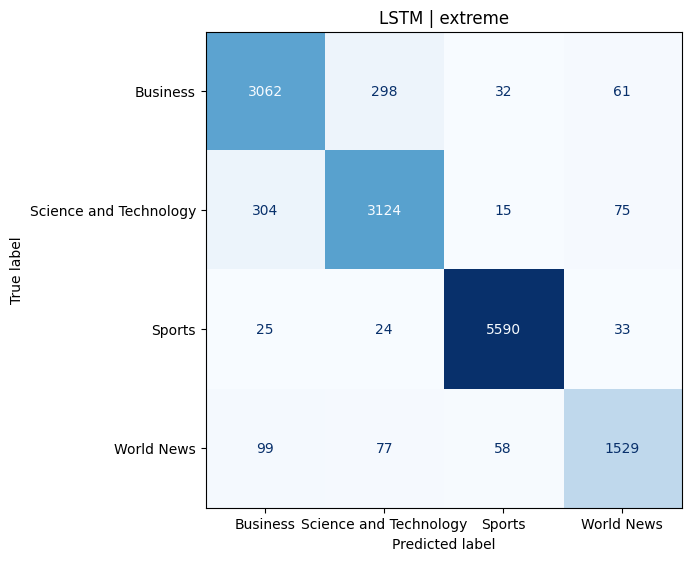

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9175343606830487, 'macro_f1': 0.9019357264479133}


,precision,recall,f1-score,support
Business,0.875000,0.877787,0.876391,3453.000000
Science and Technology,0.882604,0.882604,0.882604,3518.000000
Sports,0.981757,0.977257,0.979502,5672.000000
World News,0.865579,0.872944,0.869246,1763.000000
accuracy,0.917534,0.917534,0.917534,0.917534
macro avg,0.901235,0.902648,0.901936,14406.000000
weighted avg,0.917737,0.917534,0.917631,14406.000000


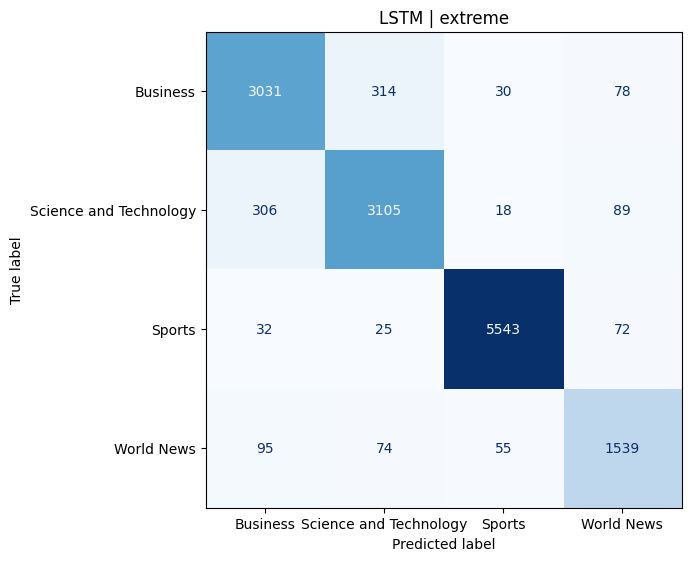

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9218381230043038, 'macro_f1': 0.9071465080309711}


,precision,recall,f1-score,support
Business,0.873537,0.886186,0.879816,3453.000000
Science and Technology,0.882236,0.883741,0.882988,3518.000000
Sports,0.982077,0.985367,0.983719,5672.000000
World News,0.901659,0.863301,0.882063,1763.000000
accuracy,0.921838,0.921838,0.921838,0.921838
macro avg,0.909877,0.904649,0.907147,14406.000000
weighted avg,0.921838,0.921838,0.921775,14406.000000


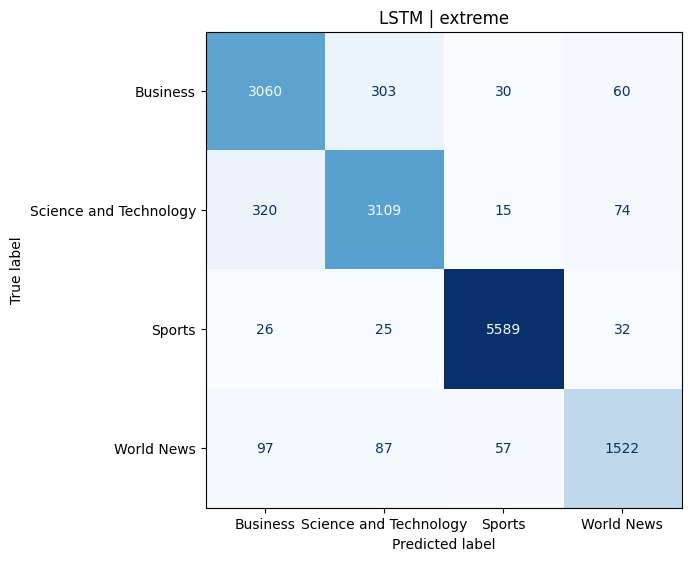

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9254477301124532, 'macro_f1': 0.9112391652832845}


,precision,recall,f1-score,support
Business,0.868003,0.902693,0.885009,3453.000000
Science and Technology,0.899045,0.883457,0.891183,3518.000000
Sports,0.981228,0.986072,0.983644,5672.000000
World News,0.913148,0.858763,0.885121,1763.000000
accuracy,0.925448,0.925448,0.925448,0.925448
macro avg,0.915356,0.907746,0.911239,14406.000000
weighted avg,0.925688,0.925448,0.925365,14406.000000


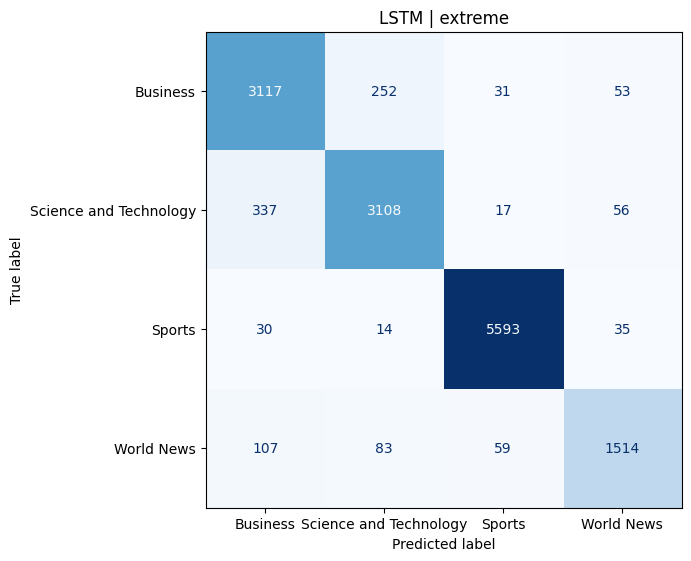

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9214216298764404, 'macro_f1': 0.9057746598593951}


,precision,recall,f1-score,support
Business,0.914934,0.841008,0.876415,3453.000000
Science and Technology,0.867751,0.910176,0.888457,3518.000000
Sports,0.976999,0.988540,0.982736,5672.000000
World News,0.865779,0.885423,0.875491,1763.000000
accuracy,0.921422,0.921422,0.921422,0.921422
macro avg,0.906366,0.906287,0.905775,14406.000000
weighted avg,0.921833,0.921422,0.921104,14406.000000


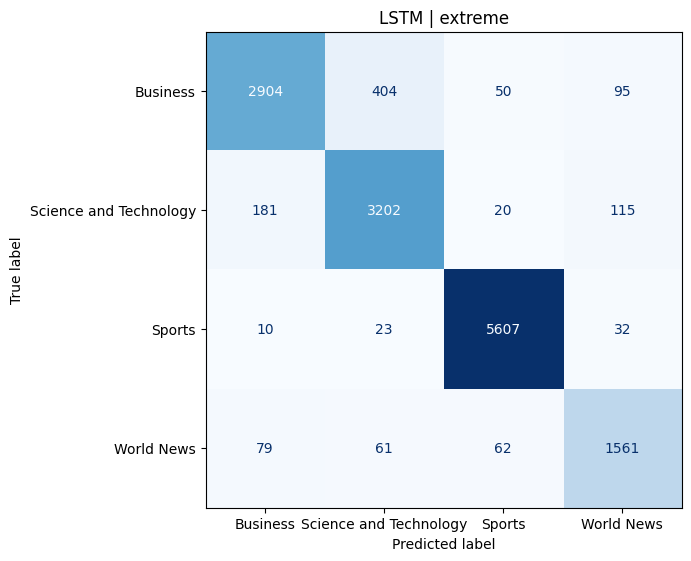

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9251700680272109, 'macro_f1': 0.9102021885489606}


,precision,recall,f1-score,support
Business,0.892154,0.879235,0.885648,3453.00000
Science and Technology,0.887020,0.899375,0.893155,3518.00000
Sports,0.984289,0.983075,0.983682,5672.00000
World News,0.876341,0.880318,0.878325,1763.00000
accuracy,0.925170,0.925170,0.925170,0.92517
macro avg,0.909951,0.910501,0.910202,14406.00000
weighted avg,0.925241,0.925170,0.925183,14406.00000


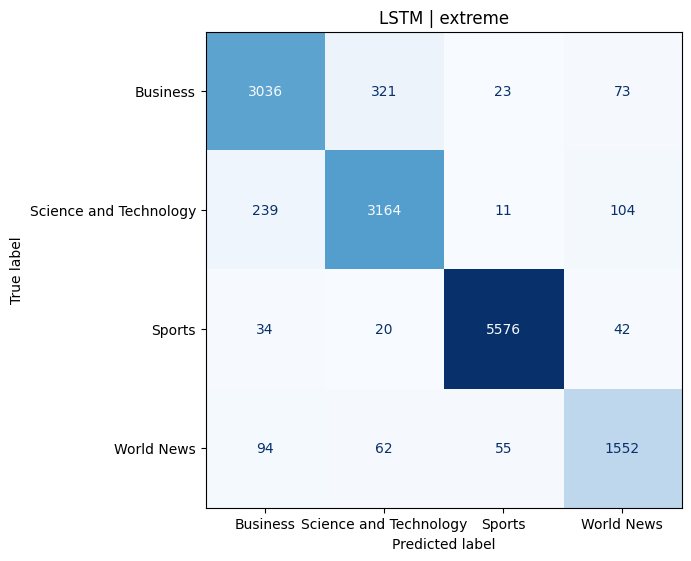

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.921491045397751, 'macro_f1': 0.9058896000801651}


,precision,recall,f1-score,support
Business,0.889185,0.869099,0.879028,3453.000000
Science and Technology,0.883282,0.890563,0.886907,3518.000000
Sports,0.978337,0.987306,0.982801,5672.000000
World News,0.875568,0.874078,0.874823,1763.000000
accuracy,0.921491,0.921491,0.921491,0.921491
macro avg,0.906593,0.905262,0.905890,14406.000000
weighted avg,0.921178,0.921491,0.921295,14406.000000


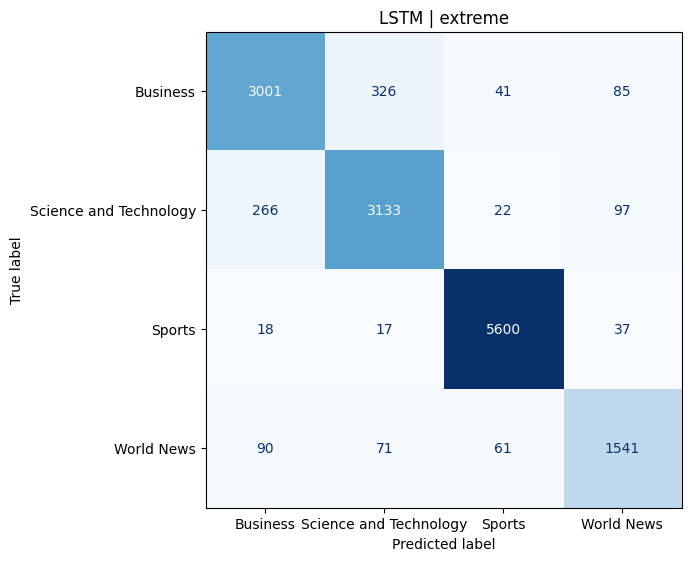

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_LSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9252394835485215, 'macro_f1': 0.9101997333718579}


,precision,recall,f1-score,support
Business,0.889761,0.885896,0.887825,3453.000000
Science and Technology,0.896100,0.894827,0.895463,3518.000000
Sports,0.985281,0.979549,0.982407,5672.000000
World News,0.862335,0.888259,0.875105,1763.000000
accuracy,0.925239,0.925239,0.925239,0.925239
macro avg,0.908369,0.912133,0.910200,14406.000000
weighted avg,0.925561,0.925239,0.925373,14406.000000


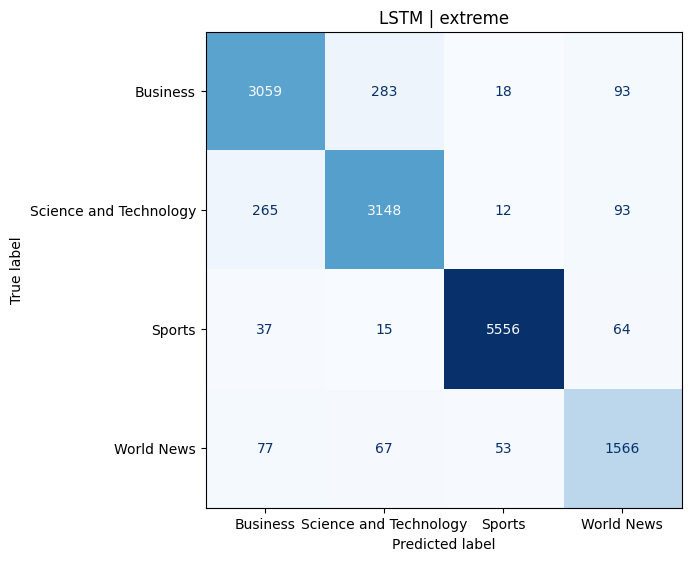

Running BiSimpleRNN on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9067749548799111, 'macro_f1': 0.8893787407149959}


,precision,recall,f1-score,support
Business,0.882299,0.835795,0.858418,3453.000000
Science and Technology,0.864135,0.873223,0.868655,3518.000000
Sports,0.966216,0.983251,0.974659,5672.000000
World News,0.845133,0.866704,0.855783,1763.000000
accuracy,0.906775,0.906775,0.906775,0.906775
macro avg,0.889446,0.889743,0.889379,14406.000000
weighted avg,0.906355,0.906775,0.906362,14406.000000


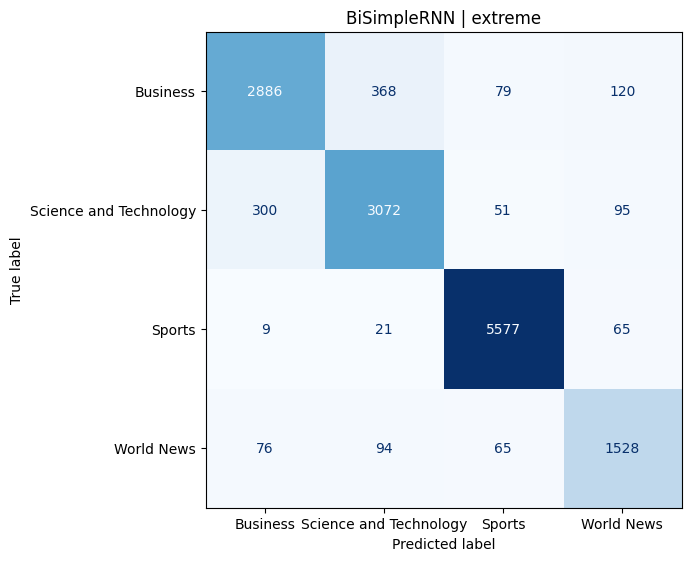

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9122587810634458, 'macro_f1': 0.8967924572900983}


,precision,recall,f1-score,support
Business,0.861772,0.870258,0.865994,3453.000000
Science and Technology,0.871671,0.874645,0.873156,3518.000000
Sports,0.973574,0.980783,0.977165,5672.000000
World News,0.893731,0.849121,0.870855,1763.000000
accuracy,0.912259,0.912259,0.912259,0.912259
macro avg,0.900187,0.893702,0.896792,14406.000000
weighted avg,0.912120,0.912259,0.912109,14406.000000


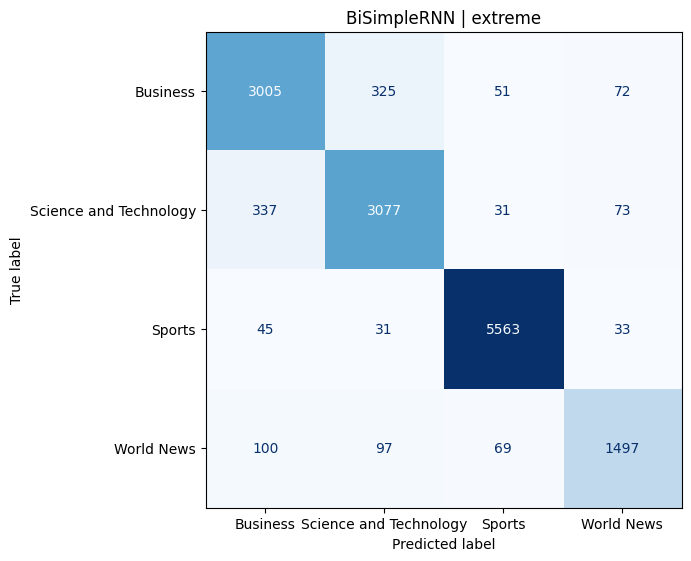

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9108010551159239, 'macro_f1': 0.8951793135762327}


,precision,recall,f1-score,support
Business,0.873161,0.859253,0.866151,3453.000000
Science and Technology,0.869836,0.873792,0.871809,3518.000000
Sports,0.964249,0.984309,0.974176,5672.000000
World News,0.888955,0.849121,0.868581,1763.000000
accuracy,0.910801,0.910801,0.910801,0.910801
macro avg,0.899050,0.891619,0.895179,14406.000000
weighted avg,0.910145,0.910801,0.910362,14406.000000


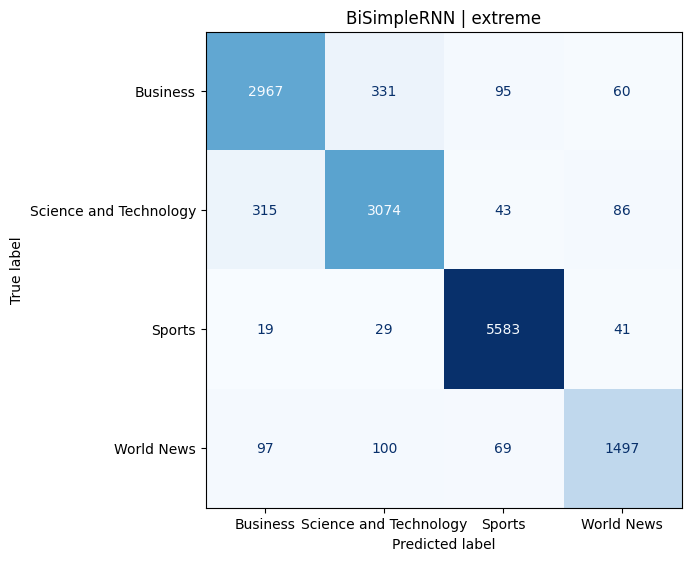

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.911425794807719, 'macro_f1': 0.8954202179219144}


,precision,recall,f1-score,support
Business,0.866725,0.864466,0.865594,3453.000000
Science and Technology,0.872050,0.871802,0.871926,3518.000000
Sports,0.968772,0.984485,0.976565,5672.000000
World News,0.888757,0.847419,0.867596,1763.000000
accuracy,0.911426,0.911426,0.911426,0.911426
macro avg,0.899076,0.892043,0.895420,14406.000000
weighted avg,0.910900,0.911426,0.911077,14406.000000


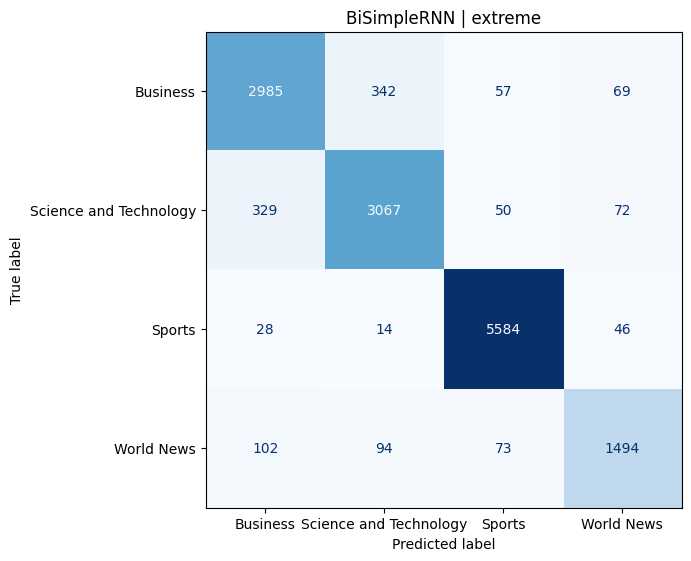

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9031653477717617, 'macro_f1': 0.8866560810241569}


,precision,recall,f1-score,support
Business,0.857392,0.854909,0.856148,3453.000000
Science and Technology,0.856819,0.860716,0.858763,3518.000000
Sports,0.969023,0.976199,0.972598,5672.000000
World News,0.871137,0.847419,0.859114,1763.000000
accuracy,0.903165,0.903165,0.903165,0.903165
macro avg,0.888593,0.884811,0.886656,14406.000000
weighted avg,0.902886,0.903165,0.902999,14406.000000


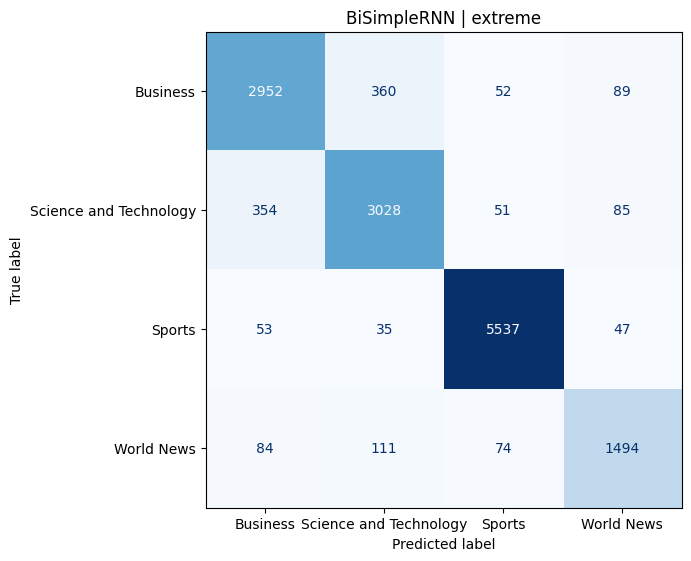

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.8990004164931279, 'macro_f1': 0.8819037495895816}


,precision,recall,f1-score,support
Business,0.844546,0.854330,0.849410,3453.000
Science and Technology,0.862489,0.845082,0.853697,3518.000
Sports,0.972963,0.970733,0.971847,5672.000
World News,0.842280,0.863301,0.852661,1763.000
accuracy,0.899000,0.899000,0.899000,0.899
macro avg,0.880570,0.883362,0.881904,14406.000
weighted avg,0.899212,0.899000,0.899061,14406.000


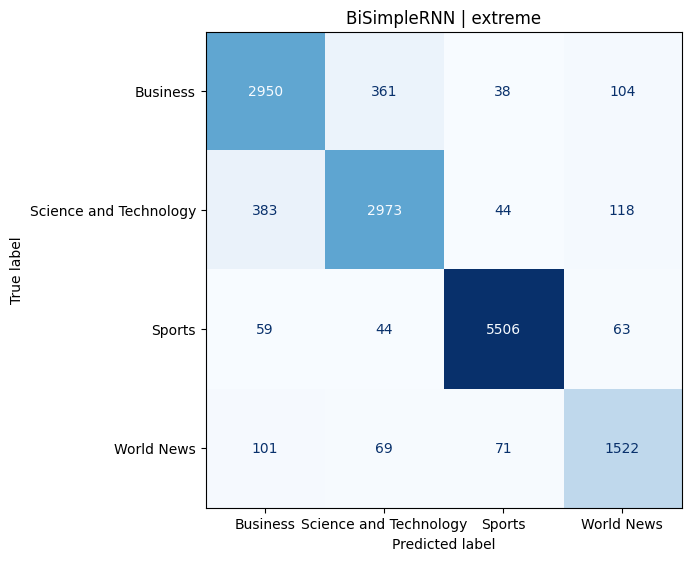

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9032347632930723, 'macro_f1': 0.8858553504980098}


,precision,recall,f1-score,support
Business,0.850686,0.861280,0.855950,3453.000000
Science and Technology,0.871908,0.841671,0.856523,3518.000000
Sports,0.970491,0.979901,0.975173,5672.000000
World News,0.850028,0.861600,0.855775,1763.000000
accuracy,0.903235,0.903235,0.903235,0.903235
macro avg,0.885778,0.886113,0.885855,14406.000000
weighted avg,0.902958,0.903235,0.903010,14406.000000


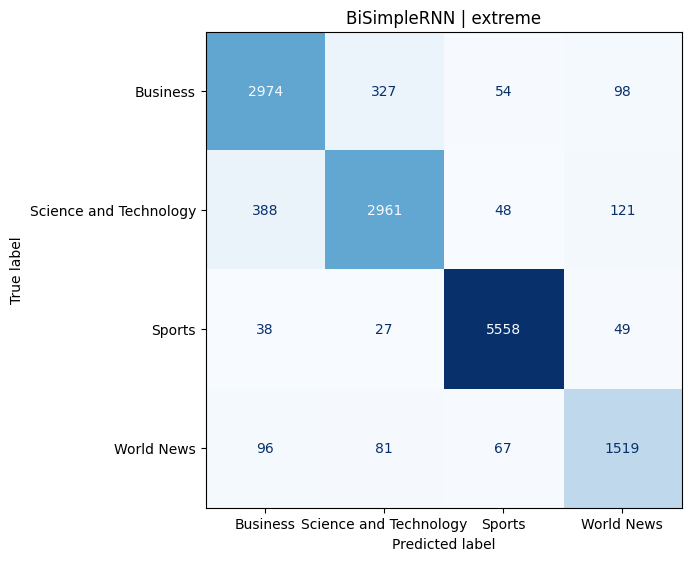

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiSimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9036512564209357, 'macro_f1': 0.8856193806993709}


,precision,recall,f1-score,support
Business,0.836509,0.877208,0.856375,3453.000000
Science and Technology,0.854438,0.859295,0.856859,3518.000000
Sports,0.966453,0.985367,0.975818,5672.000000
World News,0.940574,0.781055,0.853424,1763.000000
accuracy,0.903651,0.903651,0.903651,0.903651
macro avg,0.899493,0.875731,0.885619,14406.000000
weighted avg,0.904785,0.903651,0.903160,14406.000000


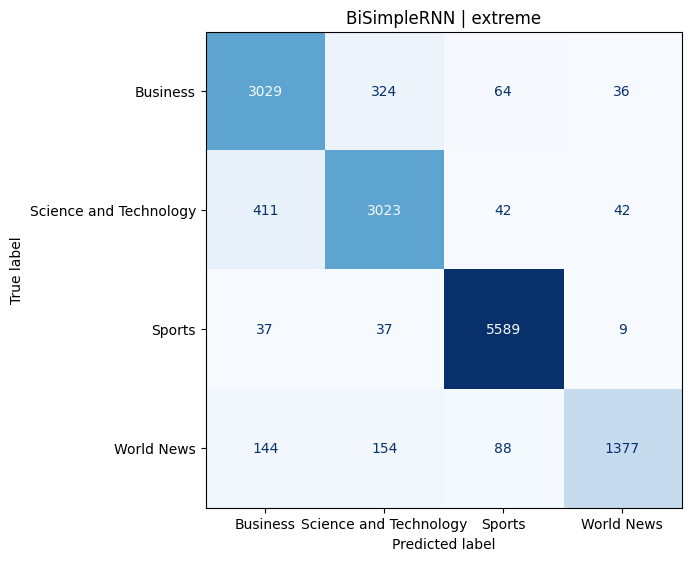

Running BiGRU on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9266972094960433, 'macro_f1': 0.9131698033904365}


,precision,recall,f1-score,support
Business,0.890123,0.882131,0.886109,3453.000000
Science and Technology,0.885283,0.899375,0.892273,3518.000000
Sports,0.981911,0.985719,0.983811,5672.000000
World News,0.902681,0.878616,0.890486,1763.000000
accuracy,0.926697,0.926697,0.926697,0.926697
macro avg,0.914999,0.911460,0.913170,14406.000000
weighted avg,0.926617,0.926697,0.926618,14406.000000


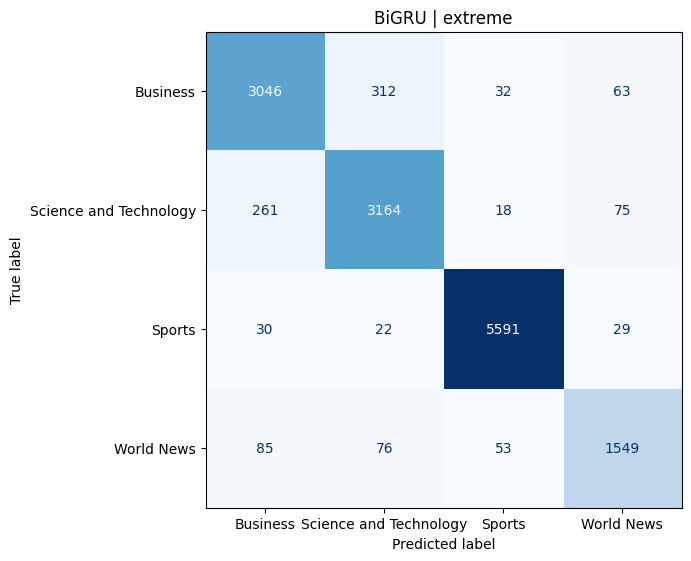

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9292655837845343, 'macro_f1': 0.915903832581811}


,precision,recall,f1-score,support
Business,0.908544,0.874602,0.891250,3453.000000
Science and Technology,0.880295,0.915577,0.897590,3518.000000
Sports,0.982929,0.984661,0.983794,5672.000000
World News,0.896611,0.885423,0.890982,1763.000000
accuracy,0.929266,0.929266,0.929266,0.929266
macro avg,0.917095,0.915066,0.915904,14406.000000
weighted avg,0.929472,0.929266,0.929202,14406.000000


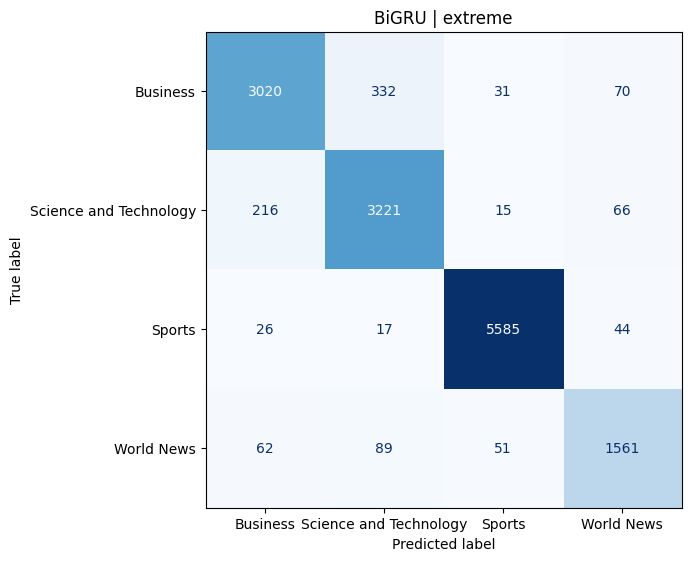

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9263501318894904, 'macro_f1': 0.9125603127205149}


,precision,recall,f1-score,support
Business,0.883109,0.894874,0.888953,3453.00000
Science and Technology,0.899477,0.880045,0.889655,3518.00000
Sports,0.983783,0.983956,0.983870,5672.00000
World News,0.880580,0.895065,0.887764,1763.00000
accuracy,0.926350,0.926350,0.926350,0.92635
macro avg,0.911737,0.913485,0.912560,14406.00000
weighted avg,0.926435,0.926350,0.926350,14406.00000


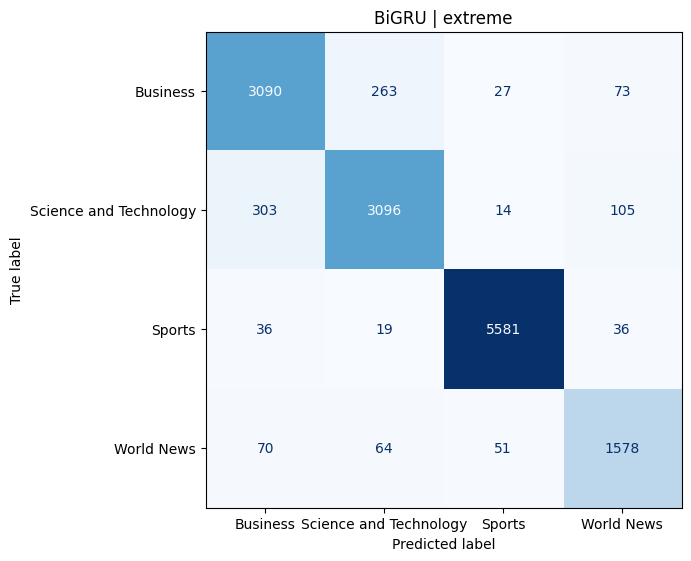

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9282243509648758, 'macro_f1': 0.9159046694876987}


,precision,recall,f1-score,support
Business,0.903206,0.872864,0.887776,3453.000000
Science and Technology,0.868879,0.922968,0.895107,3518.000000
Sports,0.986856,0.979549,0.983189,5672.000000
World News,0.913631,0.882019,0.897547,1763.000000
accuracy,0.928224,0.928224,0.928224,0.928224
macro avg,0.918143,0.914350,0.915905,14406.000000
weighted avg,0.929034,0.928224,0.928328,14406.000000


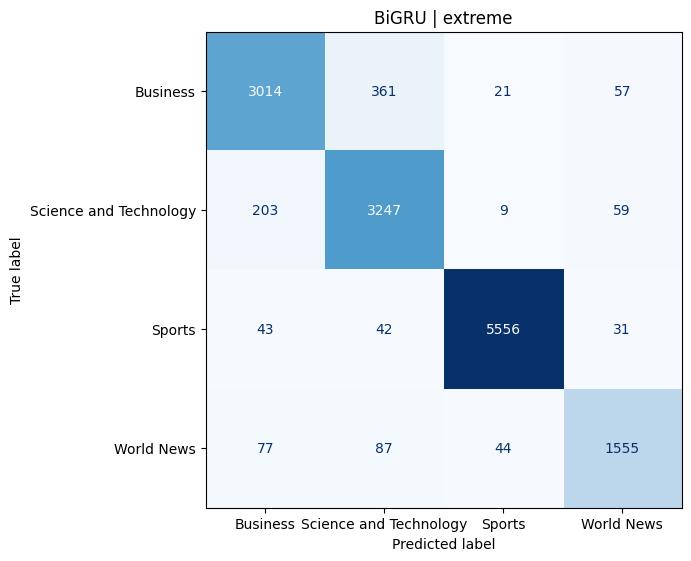

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9233652644731362, 'macro_f1': 0.9088199024791249}


,precision,recall,f1-score,support
Business,0.890990,0.873443,0.882129,3453.000000
Science and Technology,0.879152,0.895395,0.887199,3518.000000
Sports,0.982237,0.984661,0.983448,5672.000000
World News,0.885274,0.879750,0.882504,1763.000000
accuracy,0.923365,0.923365,0.923365,0.923365
macro avg,0.909413,0.908313,0.908820,14406.000000
weighted avg,0.923326,0.923365,0.923305,14406.000000


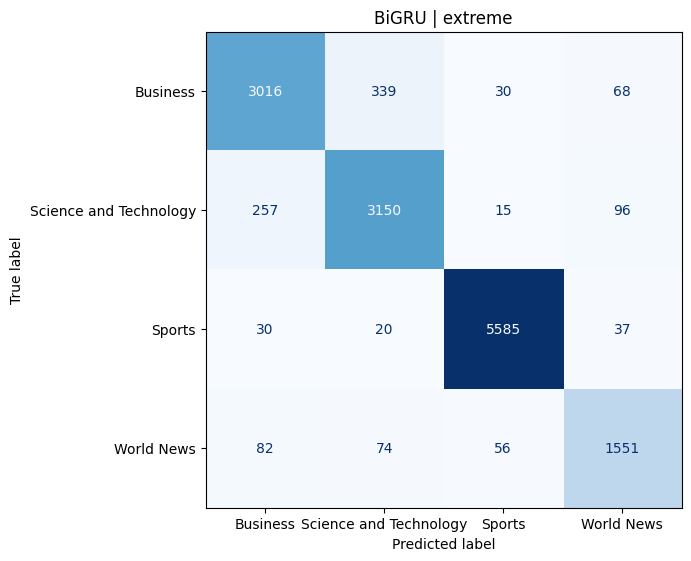

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9263501318894904, 'macro_f1': 0.912499237437612}


,precision,recall,f1-score,support
Business,0.913724,0.861859,0.887034,3453.00000
Science and Technology,0.866435,0.920125,0.892473,3518.00000
Sports,0.986180,0.981312,0.983740,5672.00000
World News,0.885246,0.888259,0.886750,1763.00000
accuracy,0.926350,0.926350,0.926350,0.92635
macro avg,0.912896,0.912889,0.912499,14406.00000
weighted avg,0.927218,0.926350,0.926403,14406.00000


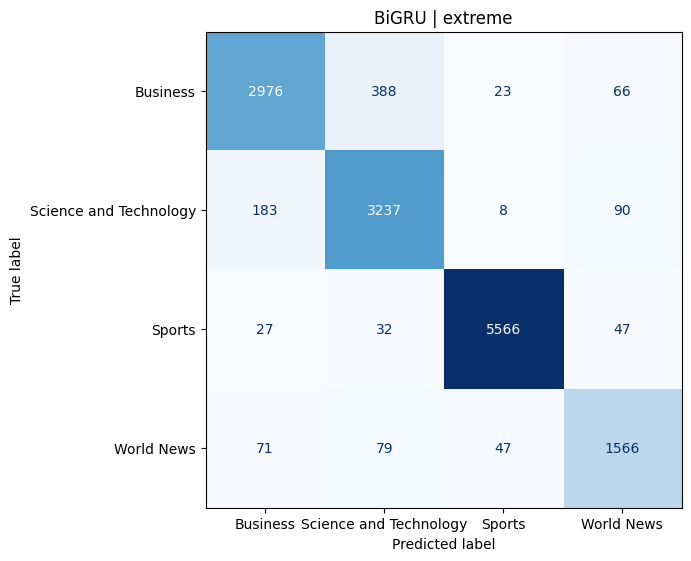

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9209357212272664, 'macro_f1': 0.9057780540704735}


,precision,recall,f1-score,support
Business,0.877733,0.883579,0.880647,3453.000000
Science and Technology,0.889855,0.872655,0.881171,3518.000000
Sports,0.983774,0.983427,0.983601,5672.000000
World News,0.866298,0.889393,0.877694,1763.000000
accuracy,0.920936,0.920936,0.920936,0.920936
macro avg,0.904415,0.907264,0.905778,14406.000000
weighted avg,0.921045,0.920936,0.920949,14406.000000


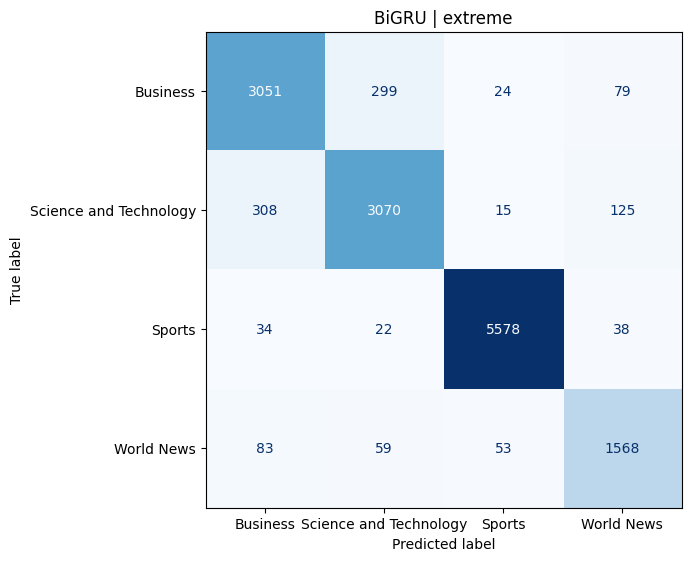

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiGRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9248229904206581, 'macro_f1': 0.9105262115764647}


,precision,recall,f1-score,support
Business,0.891677,0.874891,0.883204,3453.000000
Science and Technology,0.877410,0.905344,0.891158,3518.000000
Sports,0.982920,0.984133,0.983526,5672.000000
World News,0.898186,0.870675,0.884217,1763.000000
accuracy,0.924823,0.924823,0.924823,0.924823
macro avg,0.912548,0.908761,0.910526,14406.000000
weighted avg,0.924914,0.924823,0.924770,14406.000000


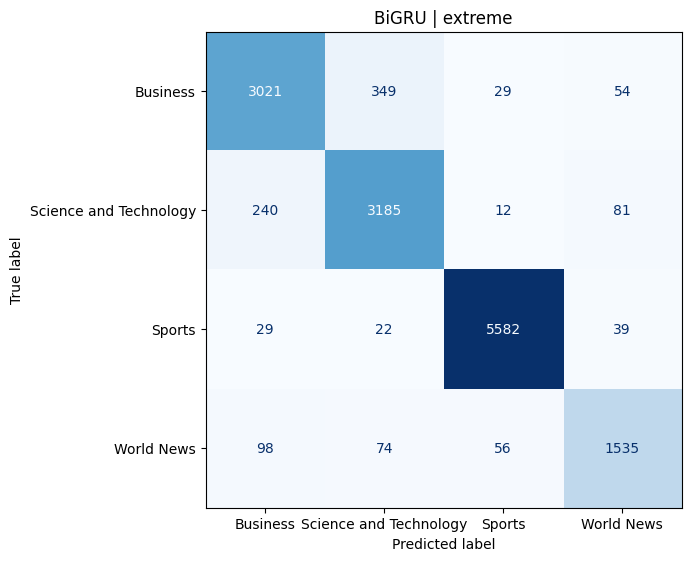

Running BiLSTM on extreme
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9278078578370124, 'macro_f1': 0.9141722354377246}


,precision,recall,f1-score,support
Business,0.895558,0.881552,0.888500,3453.000000
Science and Technology,0.885264,0.910176,0.897547,3518.000000
Sports,0.985648,0.980783,0.983210,5672.000000
World News,0.891753,0.883154,0.887432,1763.000000
accuracy,0.927808,0.927808,0.927808,0.927808
macro avg,0.914556,0.913916,0.914172,14406.000000
weighted avg,0.928049,0.927808,0.927868,14406.000000


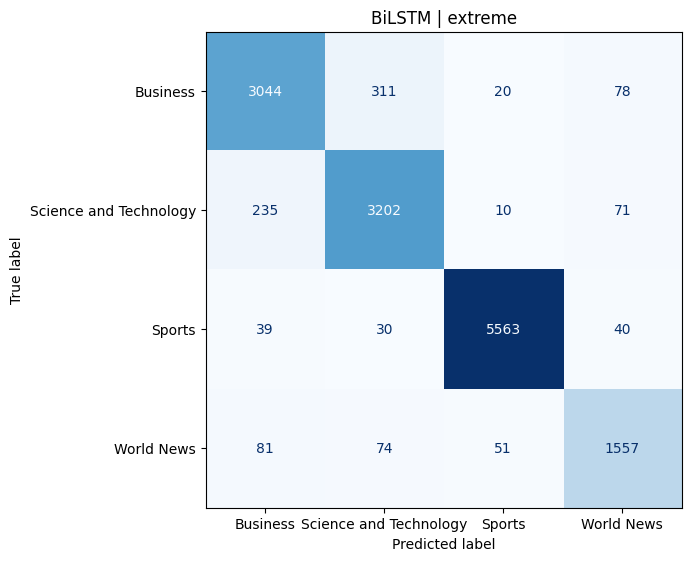

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9310009718172984, 'macro_f1': 0.917697134088941}


,precision,recall,f1-score,support
Business,0.894798,0.891688,0.893240,3453.000000
Science and Technology,0.890162,0.905344,0.897689,3518.000000
Sports,0.985561,0.986777,0.986169,5672.000000
World News,0.908080,0.879750,0.893691,1763.000000
accuracy,0.931001,0.931001,0.931001,0.931001
macro avg,0.919650,0.915890,0.917697,14406.000000
weighted avg,0.931027,0.931001,0.930970,14406.000000


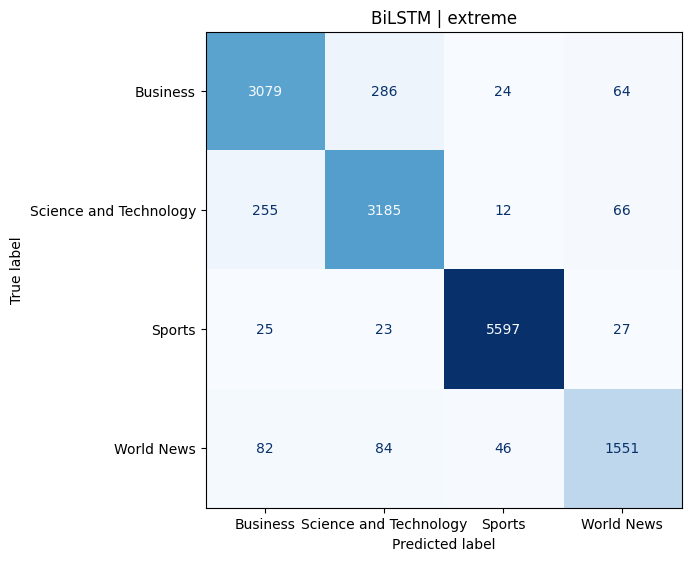

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9275996112730807, 'macro_f1': 0.9140348626971407}


,precision,recall,f1-score,support
Business,0.879252,0.898349,0.888698,3453.0000
Science and Technology,0.897502,0.888573,0.893015,3518.0000
Sports,0.983457,0.985190,0.984323,5672.0000
World News,0.903094,0.877482,0.890104,1763.0000
accuracy,0.927600,0.927600,0.927600,0.9276
macro avg,0.915826,0.912399,0.914035,14406.0000
weighted avg,0.927654,0.927600,0.927574,14406.0000


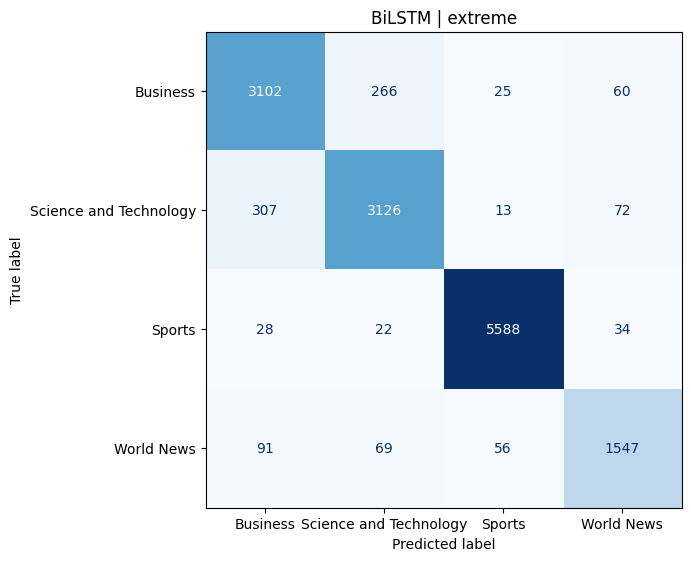

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9298209079550187, 'macro_f1': 0.9167033166610301}


,precision,recall,f1-score,support
Business,0.884781,0.894005,0.889369,3453.000000
Science and Technology,0.896875,0.897385,0.897130,3518.000000
Sports,0.982641,0.988011,0.985319,5672.000000
World News,0.913223,0.877482,0.894996,1763.000000
accuracy,0.929821,0.929821,0.929821,0.929821
macro avg,0.919380,0.914221,0.916703,14406.000000
weighted avg,0.929745,0.929821,0.929731,14406.000000


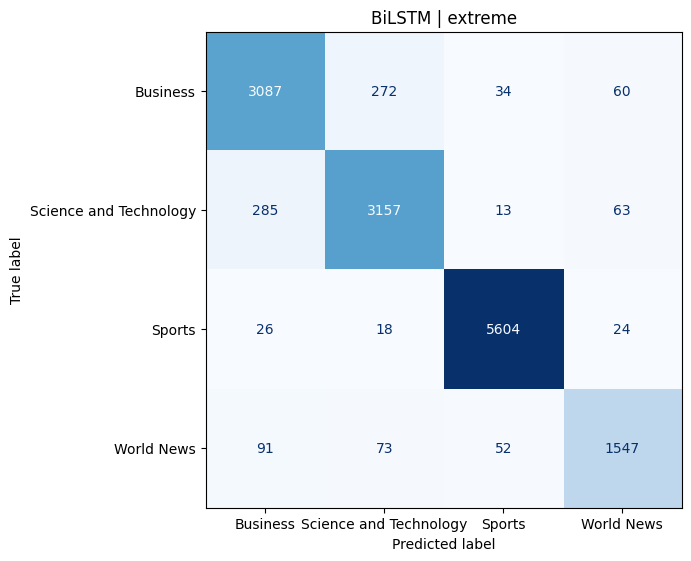

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.923226433430515, 'macro_f1': 0.9089832362314546}


,precision,recall,f1-score,support
Business,0.898402,0.863018,0.880355,3453.000000
Science and Technology,0.867551,0.910460,0.888488,3518.000000
Sports,0.981703,0.983780,0.982740,5672.000000
World News,0.897256,0.871809,0.884350,1763.000000
accuracy,0.923226,0.923226,0.923226,0.923226
macro avg,0.911228,0.907267,0.908983,14406.000000
weighted avg,0.923526,0.923226,0.923142,14406.000000


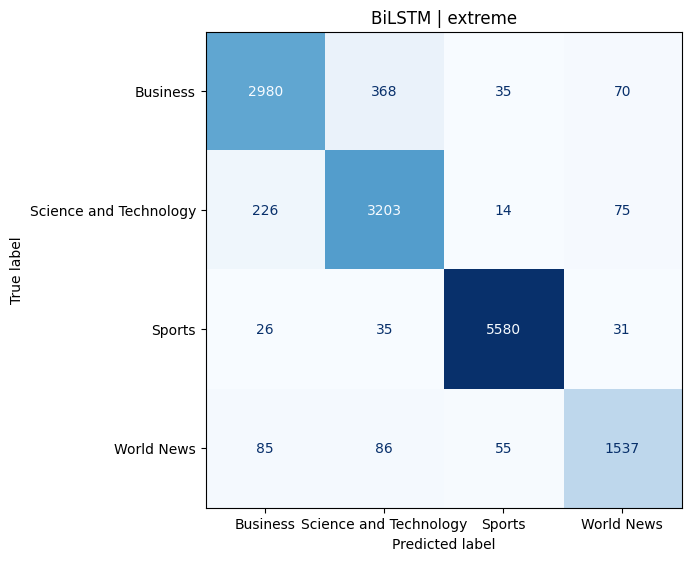

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9255171456337637, 'macro_f1': 0.9116402884028584}


,precision,recall,f1-score,support
Business,0.899074,0.871995,0.885328,3453.000000
Science and Technology,0.870214,0.911029,0.890154,3518.000000
Sports,0.984808,0.982898,0.983852,5672.000000
World News,0.900175,0.874645,0.887227,1763.000000
accuracy,0.925517,0.925517,0.925517,0.925517
macro avg,0.913568,0.910142,0.911640,14406.000000
weighted avg,0.925917,0.925517,0.925530,14406.000000


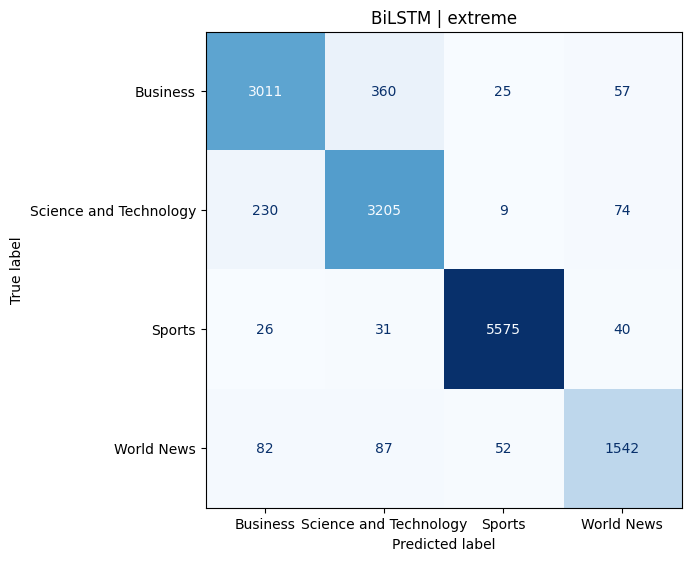

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9224628626960989, 'macro_f1': 0.9081567786362896}


,precision,recall,f1-score,support
Business,0.880856,0.882131,0.881493,3453.000000
Science and Technology,0.885942,0.883172,0.884555,3518.000000
Sports,0.984102,0.982193,0.983147,5672.000000
World News,0.879213,0.887691,0.883432,1763.000000
accuracy,0.922463,0.922463,0.922463,0.922463
macro avg,0.907528,0.908797,0.908157,14406.000000
weighted avg,0.922548,0.922463,0.922502,14406.000000


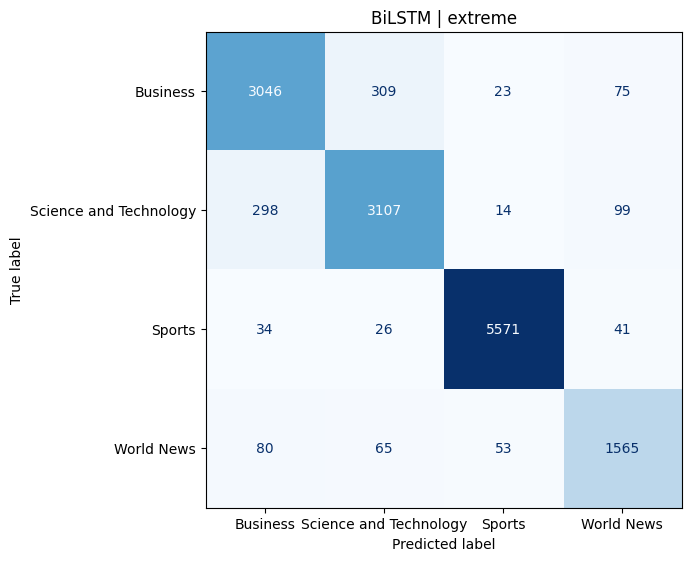

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_extreme_BiLSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9257253921976955, 'macro_f1': 0.911696127583826}


,precision,recall,f1-score,support
Business,0.880000,0.891978,0.885949,3453.000000
Science and Technology,0.893452,0.884309,0.888857,3518.000000
Sports,0.983809,0.985543,0.984675,5672.000000
World News,0.892652,0.882019,0.887304,1763.000000
accuracy,0.925725,0.925725,0.925725,0.925725
macro avg,0.912478,0.910962,0.911696,14406.000000
weighted avg,0.925705,0.925725,0.925696,14406.000000


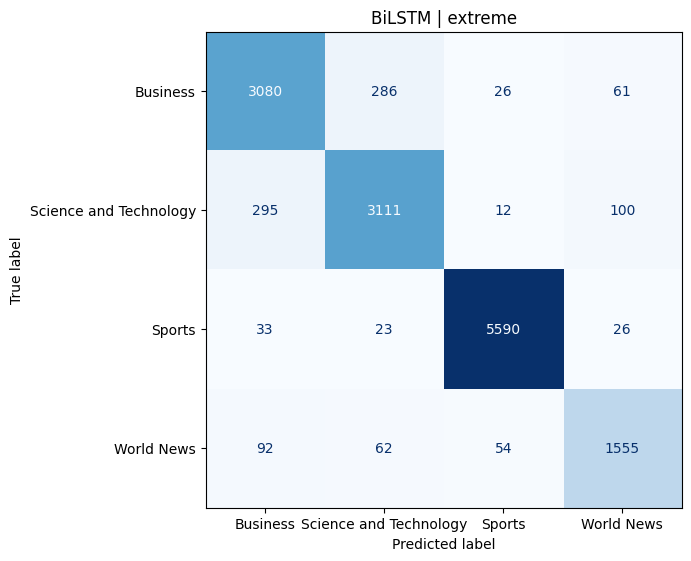

Loaded cached skip-gram inputs for optimum
Running SimpleRNN on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.25170068027210885, 'macro_f1': 0.10938494155015607}


,precision,recall,f1-score,support
Business,0.000000,0.000000,0.000000,3453.000000
Science and Technology,0.245665,0.994599,0.394009,3518.000000
Sports,0.779141,0.022391,0.043530,5672.000000
World News,0.000000,0.000000,0.000000,1763.000000
accuracy,0.251701,0.251701,0.251701,0.251701
macro avg,0.256201,0.254247,0.109385,14406.000000
weighted avg,0.366759,0.251701,0.113358,14406.000000


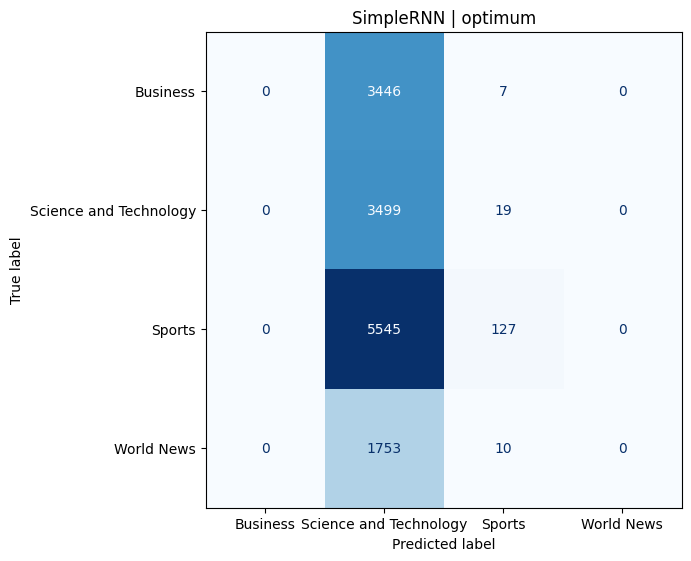

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.6096765236706928, 'macro_f1': 0.5655364080425747}


,precision,recall,f1-score,support
Business,0.552089,0.317695,0.403309,3453.000000
Science and Technology,0.562555,0.731097,0.635847,3518.000000
Sports,0.869084,0.705748,0.778945,5672.000000
World News,0.342795,0.630176,0.444045,1763.000000
accuracy,0.609677,0.609677,0.609677,0.609677
macro avg,0.581631,0.596179,0.565536,14406.000000
weighted avg,0.653840,0.609677,0.612978,14406.000000


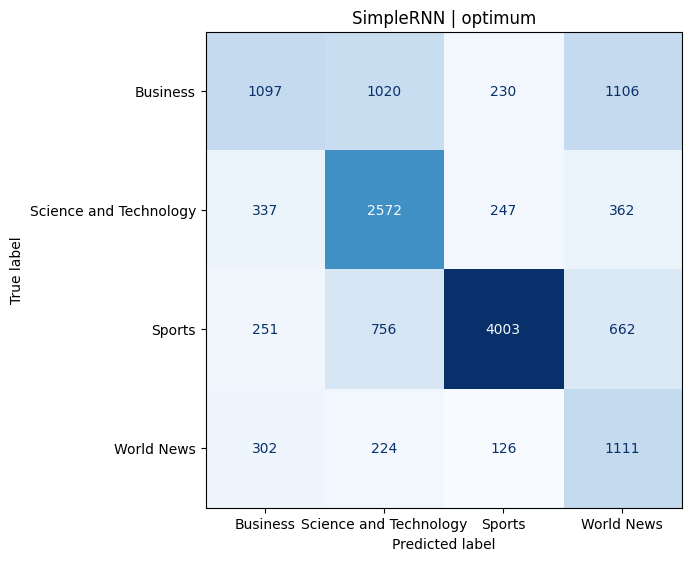

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.2452450367902263, 'macro_f1': 0.11991864163247451}


,precision,recall,f1-score,support
Business,0.244739,0.980017,0.391667,3453.000000
Science and Technology,0.322222,0.032973,0.059825,3518.000000
Sports,0.727273,0.001410,0.002815,5672.000000
World News,0.120192,0.014180,0.025368,1763.000000
accuracy,0.245245,0.245245,0.245245,0.245245
macro avg,0.353606,0.257145,0.119919,14406.000000
weighted avg,0.438404,0.245245,0.112702,14406.000000


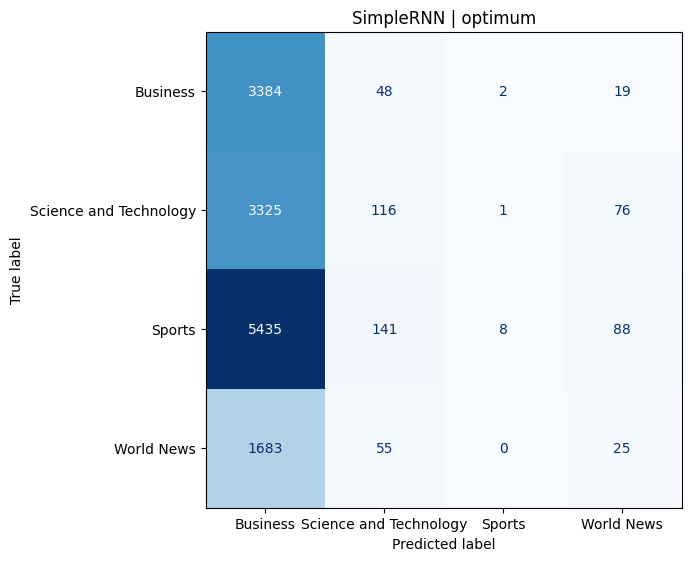

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.8175065944745245, 'macro_f1': 0.7908023835163218}


,precision,recall,f1-score,support
Business,0.678993,0.749783,0.712634,3453.000000
Science and Technology,0.780435,0.723422,0.750848,3518.000000
Sports,0.979264,0.924189,0.950930,5672.000000
World News,0.707933,0.794668,0.748797,1763.000000
accuracy,0.817507,0.817507,0.817507,0.817507
macro avg,0.786656,0.798016,0.790802,14406.000000
weighted avg,0.825531,0.817507,0.820215,14406.000000


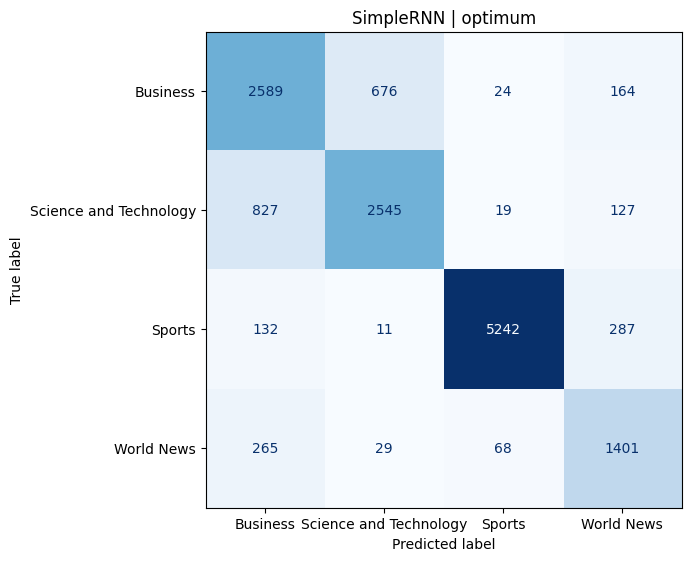

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.5960016659725115, 'macro_f1': 0.36894851160554515}


,precision,recall,f1-score,support
Business,0.399221,0.920649,0.556938,3453.000000
Science and Technology,0.700000,0.001990,0.003968,3518.000000
Sports,0.853678,0.949401,0.898998,5672.000000
World News,0.120000,0.008508,0.015890,1763.000000
accuracy,0.596002,0.596002,0.596002,0.596002
macro avg,0.518225,0.470137,0.368949,14406.000000
weighted avg,0.617432,0.596002,0.490365,14406.000000


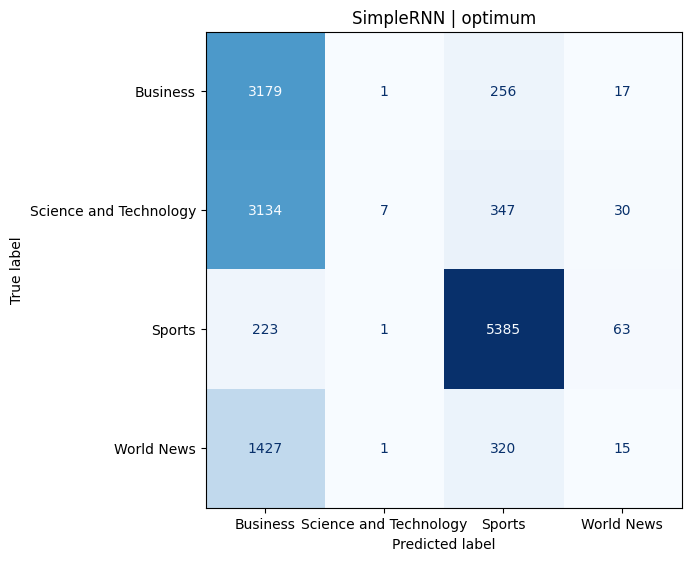

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.4757739830626128, 'macro_f1': 0.300665692207185}


,precision,recall,f1-score,support
Business,0.321244,0.933681,0.478019,3453.000000
Science and Technology,0.375000,0.000853,0.001702,3518.000000
Sports,0.831499,0.639457,0.722942,5672.000000
World News,0.000000,0.000000,0.000000,1763.000000
accuracy,0.475774,0.475774,0.475774,0.475774
macro avg,0.381936,0.393498,0.300666,14406.000000
weighted avg,0.495958,0.475774,0.399633,14406.000000


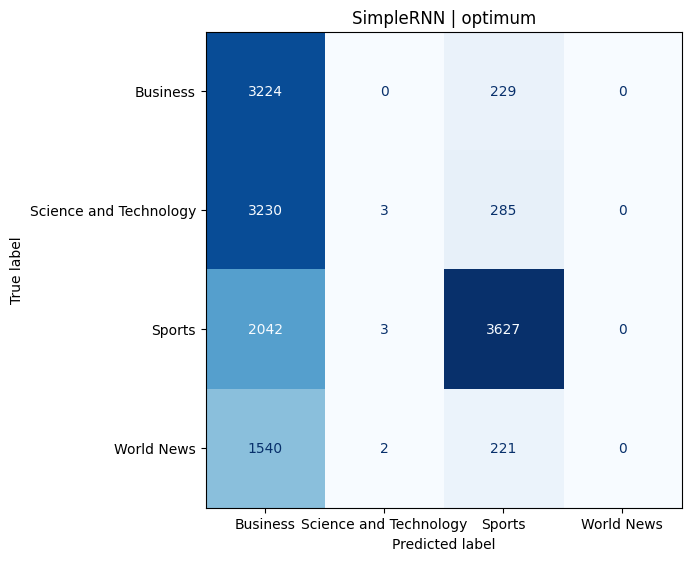

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.7244203803970568, 'macro_f1': 0.6476726171853608}


,precision,recall,f1-score,support
Business,0.514350,0.856357,0.642686,3453.00000
Science and Technology,0.837580,0.149517,0.253739,3518.00000
Sports,0.965954,0.955395,0.960645,5672.00000
World News,0.634146,0.870108,0.733620,1763.00000
accuracy,0.724420,0.724420,0.724420,0.72442
macro avg,0.738007,0.707844,0.647673,14406.00000
weighted avg,0.785752,0.724420,0.684021,14406.00000


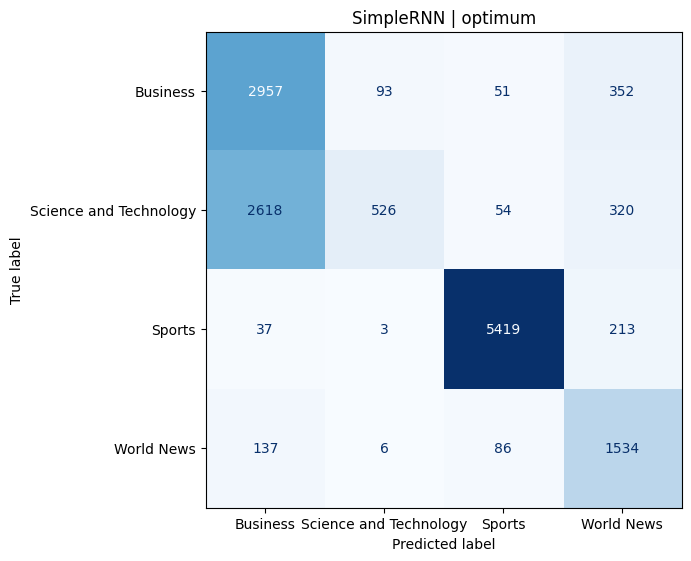

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_SimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.6245314452311537, 'macro_f1': 0.5863100028226781}


,precision,recall,f1-score,support
Business,0.472986,0.433536,0.452403,3453.000000
Science and Technology,0.522514,0.458499,0.488418,3518.000000
Sports,0.840672,0.811178,0.825662,5672.000000
World News,0.479672,0.729438,0.578758,1763.000000
accuracy,0.624531,0.624531,0.624531,0.624531
macro avg,0.578961,0.608163,0.586310,14406.000000
weighted avg,0.630666,0.624531,0.623622,14406.000000


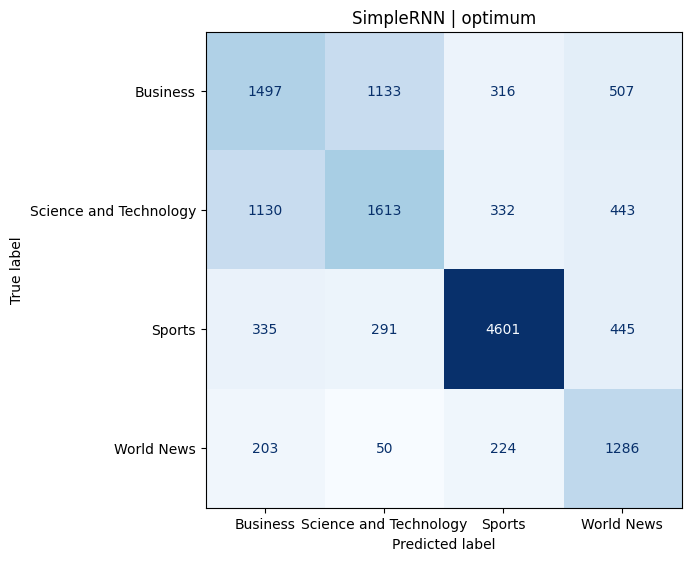

Running GRU on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9265583784534221, 'macro_f1': 0.9115839379721746}


,precision,recall,f1-score,support
Business,0.917182,0.859542,0.887427,3453.000000
Science and Technology,0.871691,0.917283,0.893906,3518.000000
Sports,0.984328,0.985543,0.984935,5672.000000
World News,0.873672,0.886557,0.880068,1763.000000
accuracy,0.926558,0.926558,0.926558,0.926558
macro avg,0.911718,0.912231,0.911584,14406.000000
weighted avg,0.927185,0.926558,0.926500,14406.000000


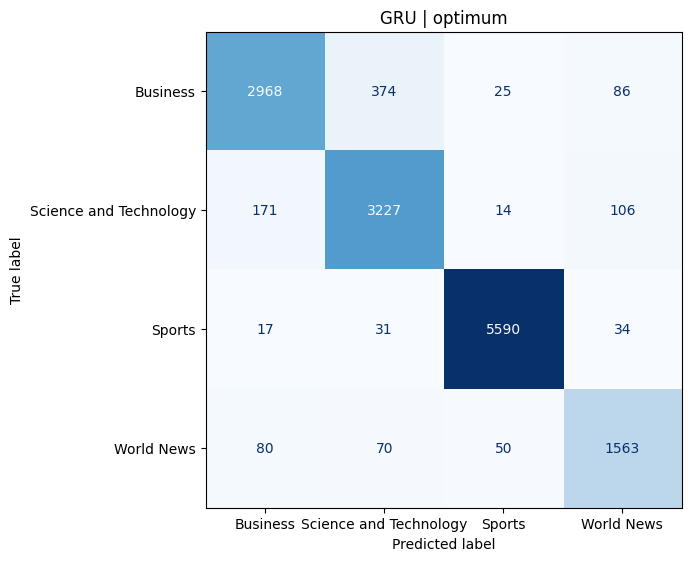

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9276690267943912, 'macro_f1': 0.913872669839461}


,precision,recall,f1-score,support
Business,0.901109,0.870837,0.885714,3453.000000
Science and Technology,0.874865,0.918135,0.895978,3518.000000
Sports,0.983635,0.985543,0.984588,5672.000000
World News,0.907320,0.871809,0.889210,1763.000000
accuracy,0.927669,0.927669,0.927669,0.927669
macro avg,0.916732,0.911581,0.913873,14406.000000
weighted avg,0.927953,0.927669,0.927578,14406.000000


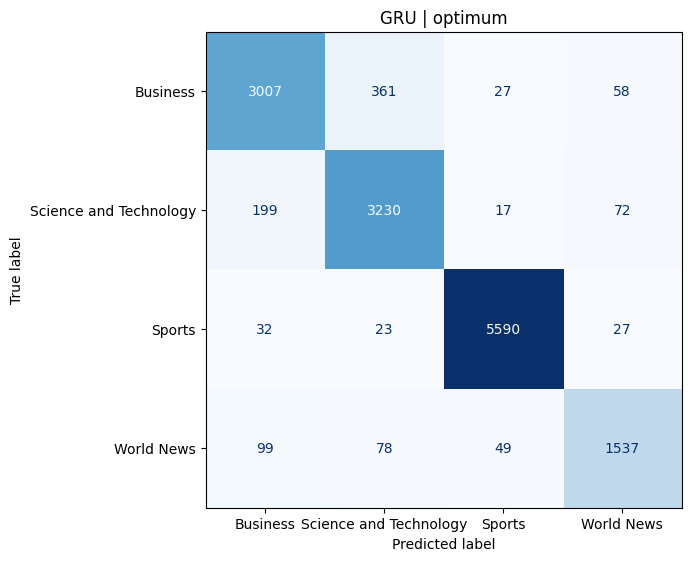

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9263501318894904, 'macro_f1': 0.9115563746994655}


,precision,recall,f1-score,support
Business,0.903724,0.864466,0.883659,3453.00000
Science and Technology,0.885205,0.903070,0.894048,3518.00000
Sports,0.980951,0.989598,0.985255,5672.00000
World News,0.876116,0.890528,0.883263,1763.00000
accuracy,0.926350,0.926350,0.926350,0.92635
macro avg,0.911499,0.911915,0.911556,14406.00000
weighted avg,0.926229,0.926350,0.926149,14406.00000


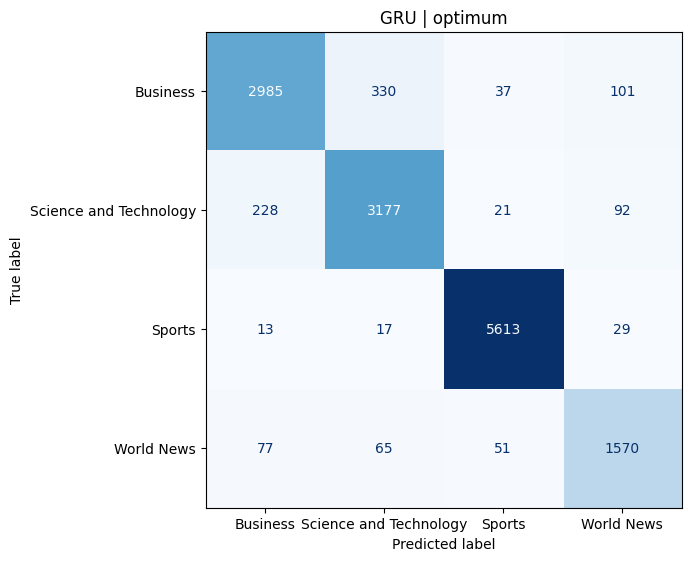

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9310009718172984, 'macro_f1': 0.9182836895243216}


,precision,recall,f1-score,support
Business,0.896994,0.890240,0.893605,3453.000000
Science and Technology,0.884541,0.905912,0.895099,3518.000000
Sports,0.986248,0.986248,0.986248,5672.000000
World News,0.913732,0.883154,0.898183,1763.000000
accuracy,0.931001,0.931001,0.931001,0.931001
macro avg,0.920379,0.916389,0.918284,14406.000000
weighted avg,0.931143,0.931001,0.931006,14406.000000


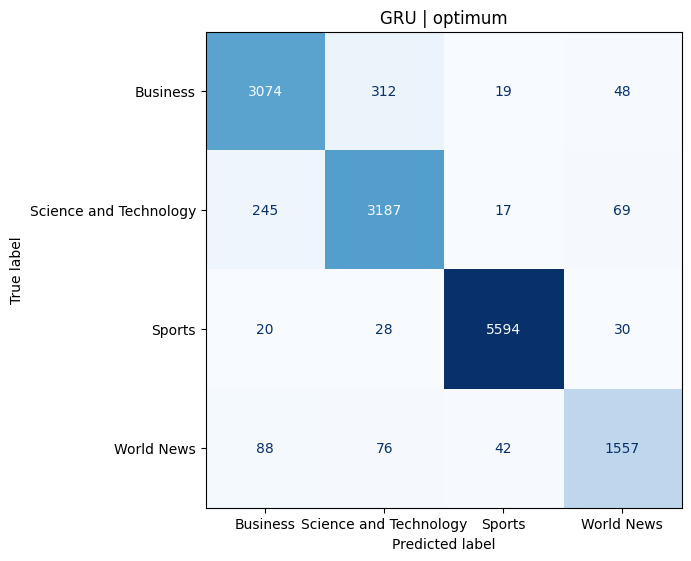

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9241288352075524, 'macro_f1': 0.9098009644483598}


,precision,recall,f1-score,support
Business,0.894328,0.867651,0.880788,3453.000000
Science and Technology,0.875138,0.904491,0.889572,3518.000000
Sports,0.984303,0.983956,0.984130,5672.000000
World News,0.888000,0.881452,0.884714,1763.000000
accuracy,0.924129,0.924129,0.924129,0.924129
macro avg,0.910442,0.909388,0.909801,14406.000000
weighted avg,0.924293,0.924129,0.924102,14406.000000


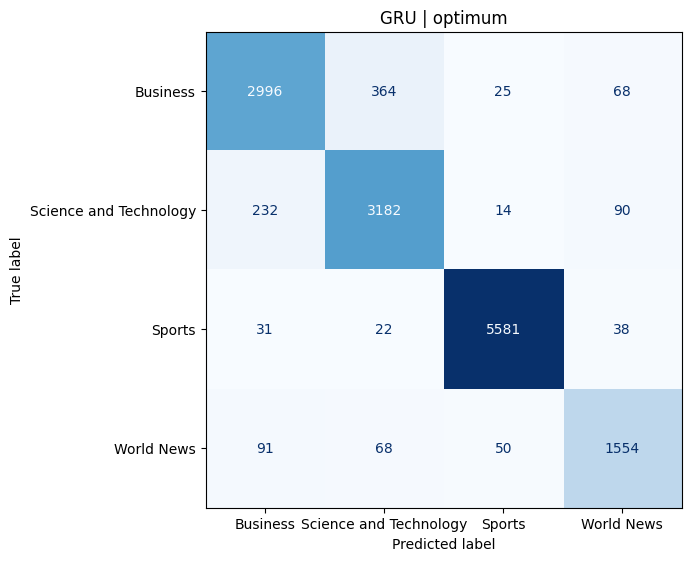

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9261418853255587, 'macro_f1': 0.9124556873486996}


,precision,recall,f1-score,support
Business,0.903968,0.864176,0.883625,3453.000000
Science and Technology,0.865932,0.916146,0.890331,3518.000000
Sports,0.985362,0.985014,0.985188,5672.000000
World News,0.903678,0.878049,0.890679,1763.000000
accuracy,0.926142,0.926142,0.926142,0.926142
macro avg,0.914735,0.910846,0.912456,14406.000000
weighted avg,0.926691,0.926142,0.926114,14406.000000


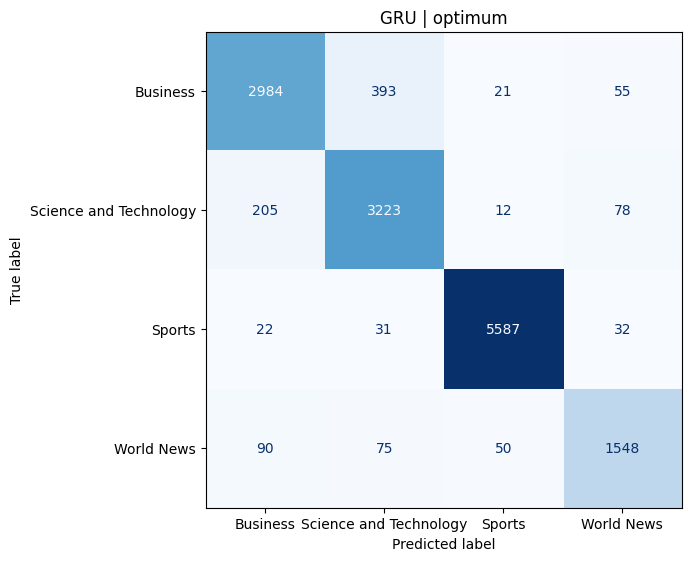

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9197556573649868, 'macro_f1': 0.9046133533435179}


,precision,recall,f1-score,support
Business,0.893579,0.858384,0.875628,3453.000000
Science and Technology,0.865937,0.899659,0.882476,3518.000000
Sports,0.981869,0.983427,0.982648,5672.000000
World News,0.880205,0.875213,0.877702,1763.000000
accuracy,0.919756,0.919756,0.919756,0.919756
macro avg,0.905398,0.904171,0.904613,14406.000000
weighted avg,0.919954,0.919756,0.919690,14406.000000


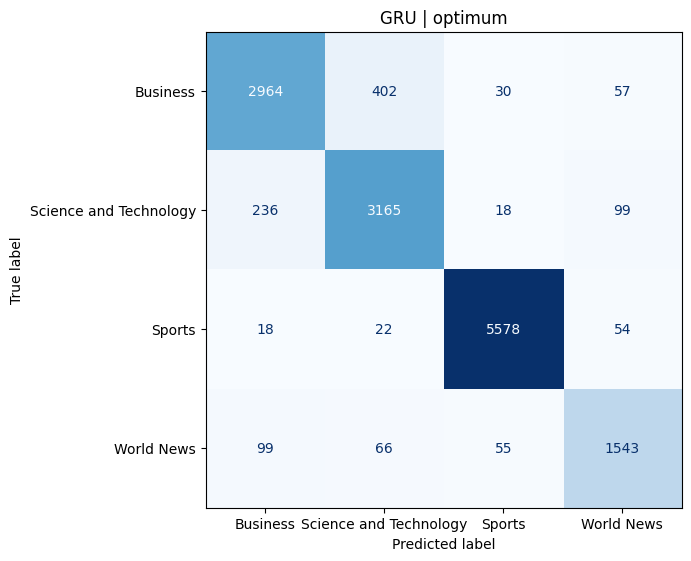

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_GRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9239205886436207, 'macro_f1': 0.9098353609372658}


,precision,recall,f1-score,support
Business,0.891613,0.874312,0.882878,3453.000000
Science and Technology,0.877178,0.901364,0.889107,3518.000000
Sports,0.985125,0.980783,0.982949,5672.000000
World News,0.885666,0.883154,0.884408,1763.000000
accuracy,0.923921,0.923921,0.923921,0.923921
macro avg,0.909895,0.909903,0.909835,14406.000000
weighted avg,0.924178,0.923921,0.923987,14406.000000


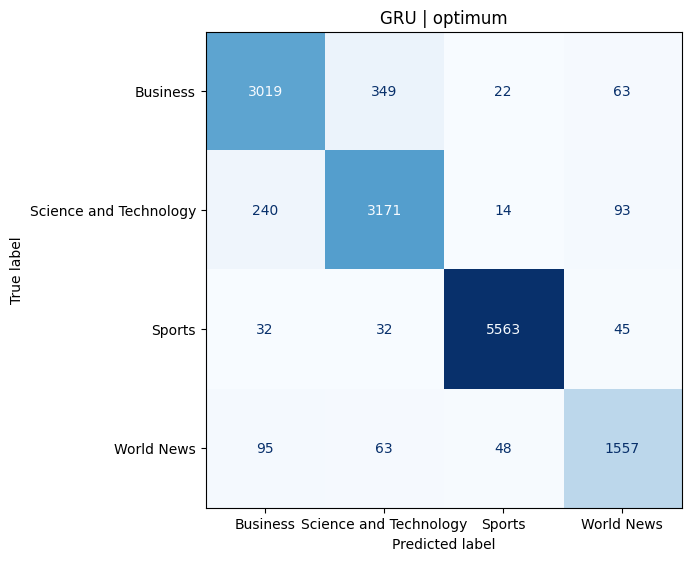

Running LSTM on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.9262807163681799, 'macro_f1': 0.9117130047161803}


,precision,recall,f1-score,support
Business,0.899401,0.869968,0.884440,3453.000000
Science and Technology,0.874560,0.917567,0.895547,3518.000000
Sports,0.983791,0.984485,0.984138,5672.000000
World News,0.899353,0.866704,0.882727,1763.000000
accuracy,0.926281,0.926281,0.926281,0.926281
macro avg,0.914276,0.909681,0.911713,14406.000000
weighted avg,0.926555,0.926281,0.926196,14406.000000


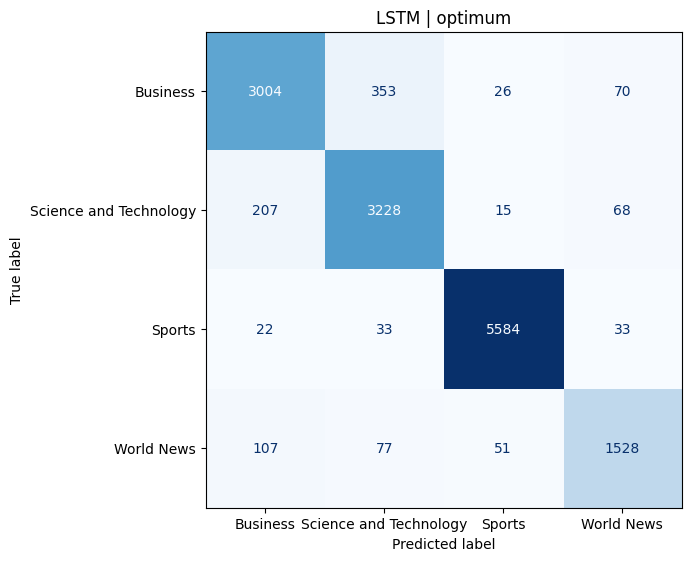

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9315562959877829, 'macro_f1': 0.9176685802646837}


,precision,recall,f1-score,support
Business,0.894767,0.891399,0.893080,3453.000000
Science and Technology,0.893965,0.901080,0.897508,3518.000000
Sports,0.985446,0.990832,0.988132,5672.000000
World News,0.903902,0.880318,0.891954,1763.000000
accuracy,0.931556,0.931556,0.931556,0.931556
macro avg,0.919520,0.915907,0.917669,14406.000000
weighted avg,0.931392,0.931556,0.931448,14406.000000


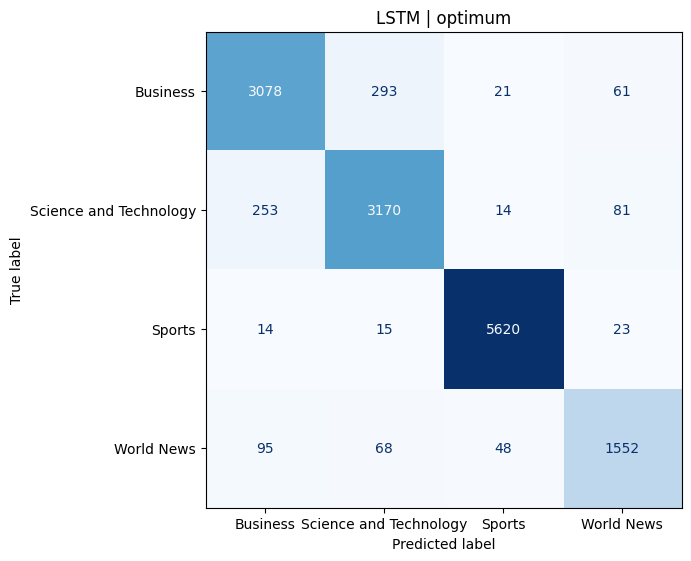

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9243370817714841, 'macro_f1': 0.9097007029999001}


,precision,recall,f1-score,support
Business,0.877429,0.889372,0.883360,3453.000000
Science and Technology,0.885795,0.886299,0.886047,3518.000000
Sports,0.983661,0.987130,0.985392,5672.000000
World News,0.902007,0.866704,0.884003,1763.000000
accuracy,0.924337,0.924337,0.924337,0.924337
macro avg,0.912223,0.907376,0.909701,14406.000000
weighted avg,0.924306,0.924337,0.924268,14406.000000


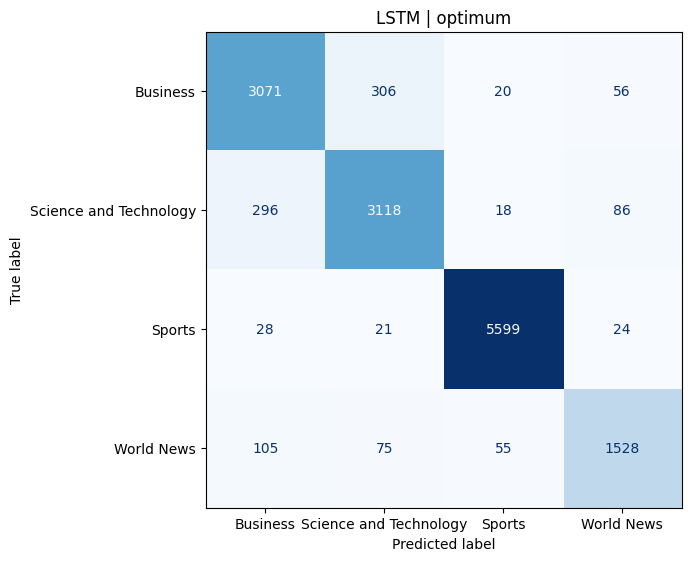

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9258642232403166, 'macro_f1': 0.9118185762738644}


,precision,recall,f1-score,support
Business,0.882151,0.893136,0.887610,3453.000000
Science and Technology,0.891398,0.886583,0.888984,3518.000000
Sports,0.986893,0.982370,0.984626,5672.000000
World News,0.885552,0.886557,0.886054,1763.000000
accuracy,0.925864,0.925864,0.925864,0.925864
macro avg,0.911499,0.912162,0.911819,14406.000000
weighted avg,0.926065,0.925864,0.925953,14406.000000


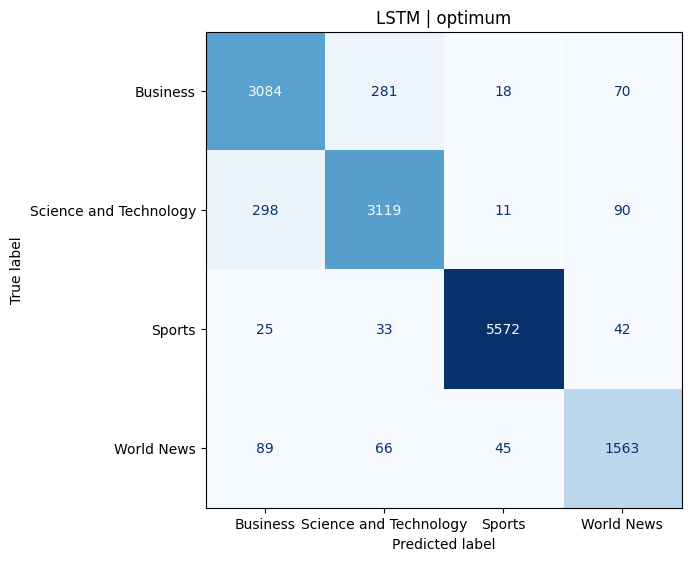

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9212827988338192, 'macro_f1': 0.90611059920039}


,precision,recall,f1-score,support
Business,0.881188,0.876339,0.878757,3453.000000
Science and Technology,0.888953,0.880614,0.884764,3518.000000
Sports,0.979685,0.986248,0.982956,5672.000000
World News,0.874508,0.881452,0.877966,1763.000000
accuracy,0.921283,0.921283,0.921283,0.921283
macro avg,0.906083,0.906163,0.906111,14406.000000
weighted avg,0.921047,0.921283,0.921153,14406.000000


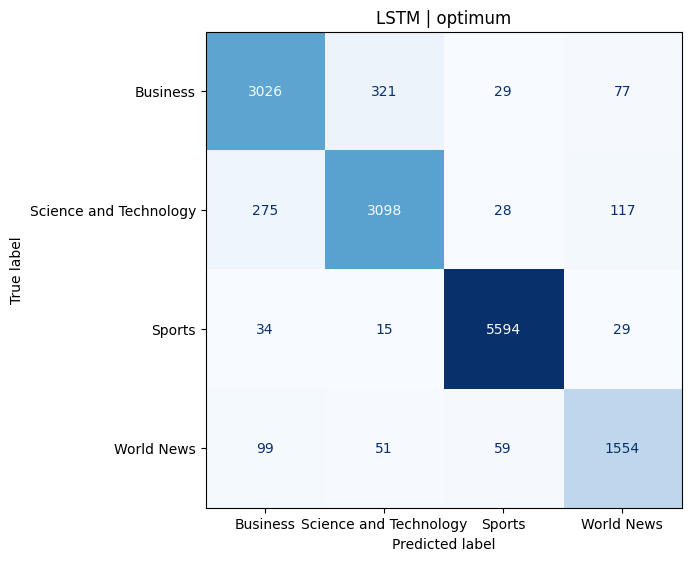

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9271831181452173, 'macro_f1': 0.9132059104529054}


,precision,recall,f1-score,support
Business,0.896154,0.877208,0.886580,3453.000000
Science and Technology,0.873059,0.911029,0.891640,3518.000000
Sports,0.984350,0.986953,0.985650,5672.000000
World News,0.914269,0.865003,0.888954,1763.000000
accuracy,0.927183,0.927183,0.927183,0.927183
macro avg,0.916958,0.910048,0.913206,14406.000000
weighted avg,0.927456,0.927183,0.927112,14406.000000


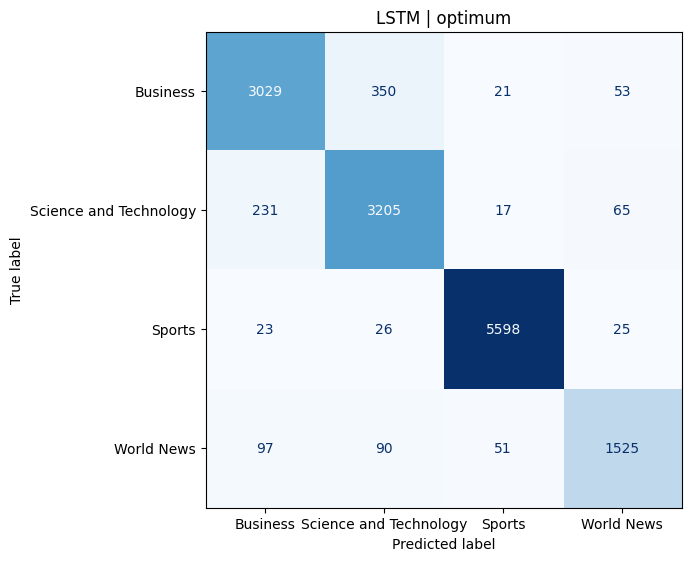

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9206580591420241, 'macro_f1': 0.9054289747376683}


,precision,recall,f1-score,support
Business,0.890378,0.865624,0.877827,3453.000000
Science and Technology,0.872158,0.893974,0.882931,3518.000000
Sports,0.983430,0.983604,0.983517,5672.000000
World News,0.875706,0.879183,0.877441,1763.000000
accuracy,0.920658,0.920658,0.920658,0.920658
macro avg,0.905418,0.905596,0.905429,14406.000000
weighted avg,0.920770,0.920658,0.920639,14406.000000


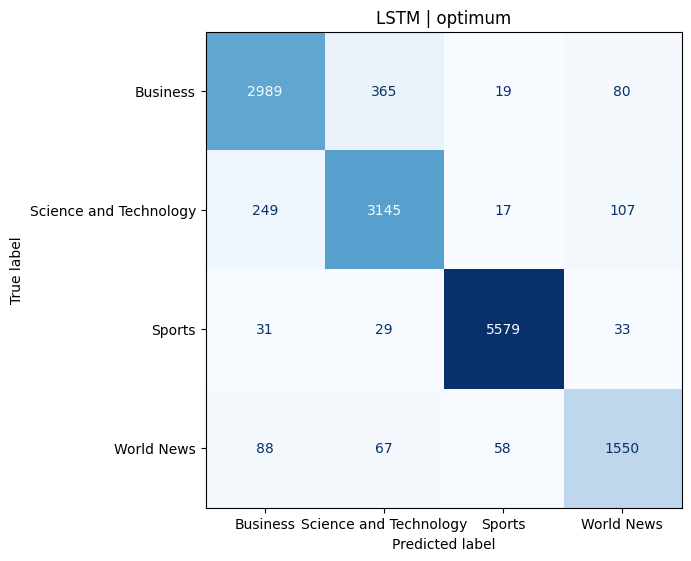

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_LSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.926419547410801, 'macro_f1': 0.9123576740033194}


,precision,recall,f1-score,support
Business,0.885706,0.886476,0.886091,3453.00000
Science and Technology,0.884518,0.894827,0.889643,3518.00000
Sports,0.985033,0.986248,0.985640,5672.00000
World News,0.901285,0.875213,0.888058,1763.00000
accuracy,0.926420,0.926420,0.926420,0.92642
macro avg,0.914135,0.910691,0.912358,14406.00000
weighted avg,0.926430,0.926420,0.926394,14406.00000


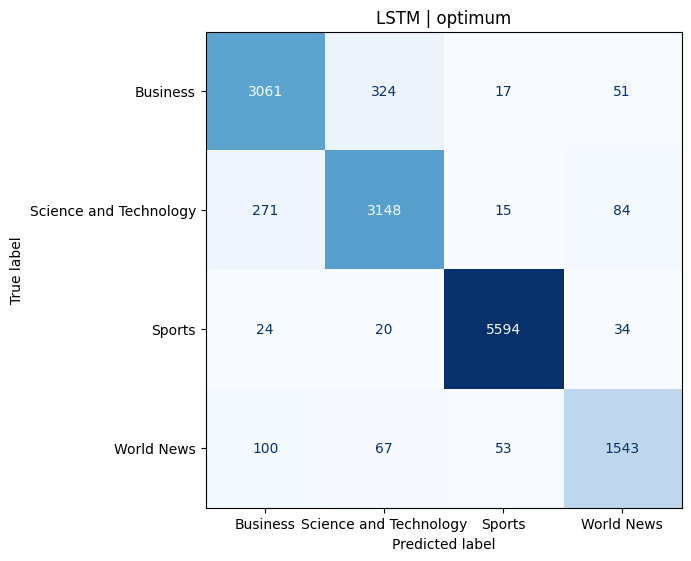

Running BiSimpleRNN on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.8894210745522699, 'macro_f1': 0.869520699711716}


,precision,recall,f1-score,support
Business,0.830528,0.828844,0.829685,3453.000000
Science and Technology,0.849315,0.845935,0.847622,3518.000000
Sports,0.971706,0.968794,0.970248,5672.000000
World News,0.821766,0.839478,0.830527,1763.000000
accuracy,0.889421,0.889421,0.889421,0.889421
macro avg,0.868329,0.870763,0.869521,14406.000000
weighted avg,0.889629,0.889421,0.889512,14406.000000


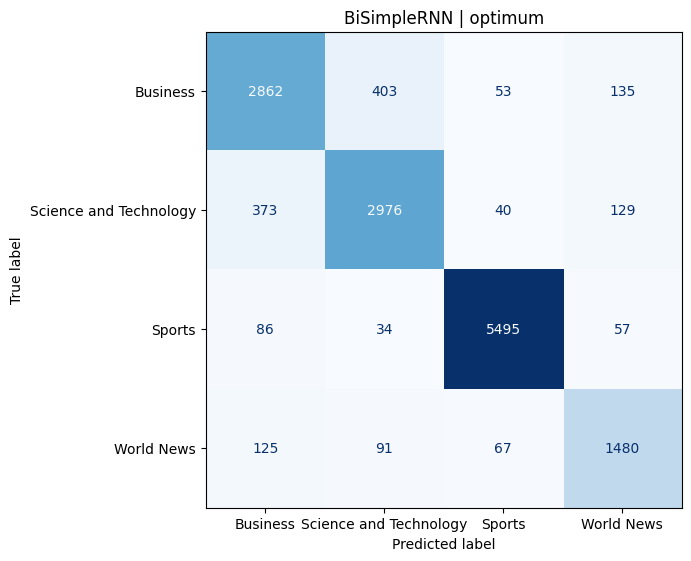

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.8908093849784812, 'macro_f1': 0.8727878421112804}


,precision,recall,f1-score,support
Business,0.826265,0.874602,0.849747,3453.000000
Science and Technology,0.810717,0.864412,0.836704,3518.000000
Sports,0.977834,0.956629,0.967115,5672.000000
World News,0.927636,0.763471,0.837586,1763.000000
accuracy,0.890809,0.890809,0.890809,0.890809
macro avg,0.885613,0.864778,0.872788,14406.000000
weighted avg,0.894550,0.890809,0.891284,14406.000000


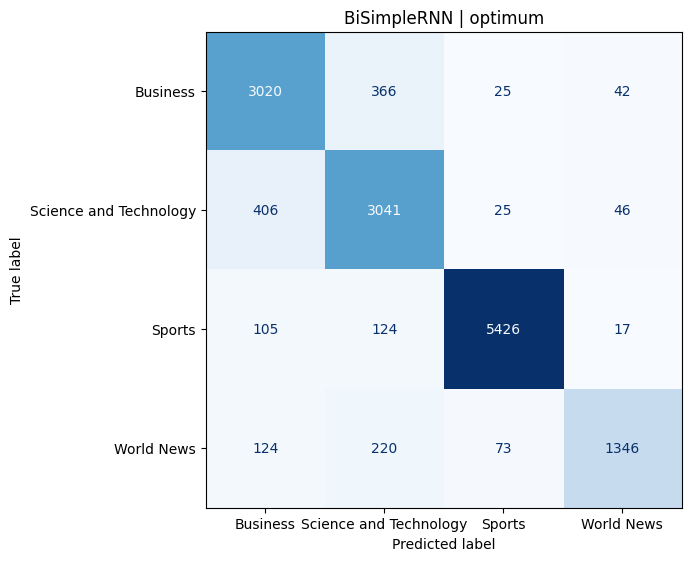

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.8960155490767736, 'macro_f1': 0.8775524351061449}


,precision,recall,f1-score,support
Business,0.845242,0.846221,0.845731,3453.000000
Science and Technology,0.841571,0.871234,0.856145,3518.000000
Sports,0.953329,0.979549,0.966261,5672.000000
World News,0.922921,0.774248,0.842073,1763.000000
accuracy,0.896016,0.896016,0.896016,0.896016
macro avg,0.890765,0.867813,0.877552,14406.000000
weighted avg,0.896408,0.896016,0.895282,14406.000000


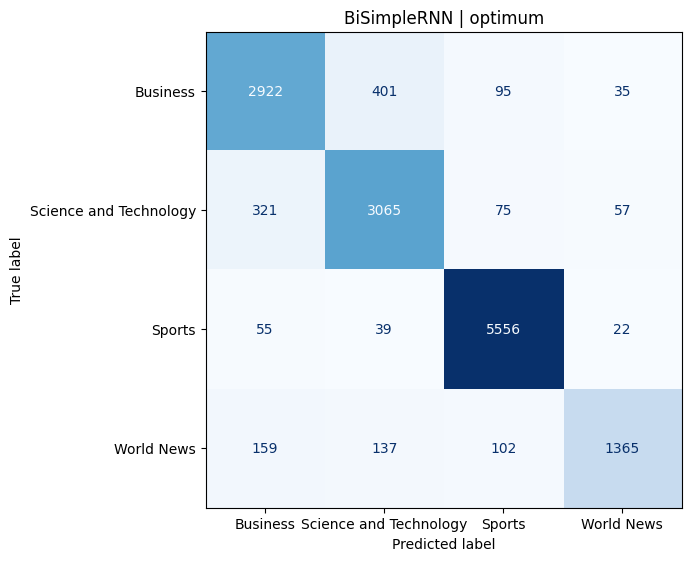

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.8896987366375122, 'macro_f1': 0.870908821845124}


,precision,recall,f1-score,support
Business,0.844722,0.841297,0.843006,3453.000000
Science and Technology,0.861571,0.813815,0.837012,3518.000000
Sports,0.951011,0.978843,0.964726,5672.000000
World News,0.828904,0.849121,0.838890,1763.000000
accuracy,0.889699,0.889699,0.889699,0.889699
macro avg,0.871552,0.870769,0.870909,14406.000000
weighted avg,0.888749,0.889699,0.888963,14406.000000


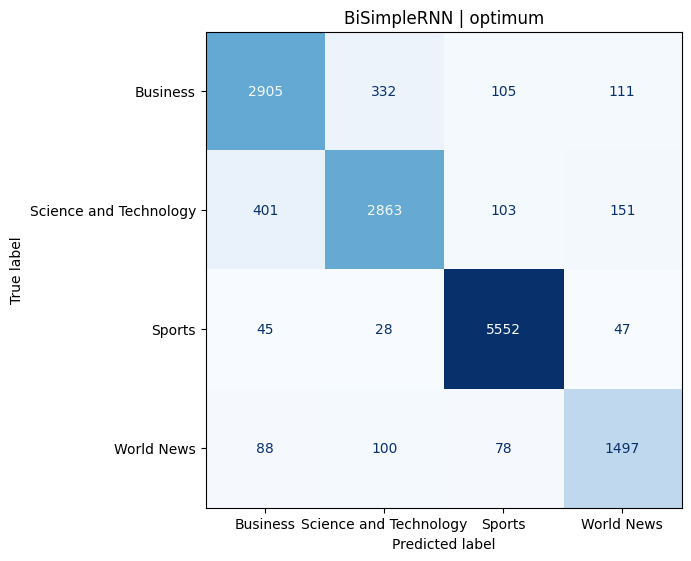

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.8801193946966541, 'macro_f1': 0.8610746880084427}


,precision,recall,f1-score,support
Business,0.896872,0.755575,0.820182,3453.000000
Science and Technology,0.770727,0.901080,0.830822,3518.000000
Sports,0.962904,0.961037,0.961969,5672.000000
World News,0.840975,0.821894,0.831325,1763.000000
accuracy,0.880119,0.880119,0.880119,0.880119
macro avg,0.867869,0.859897,0.861075,14406.000000
weighted avg,0.885225,0.880119,0.879969,14406.000000


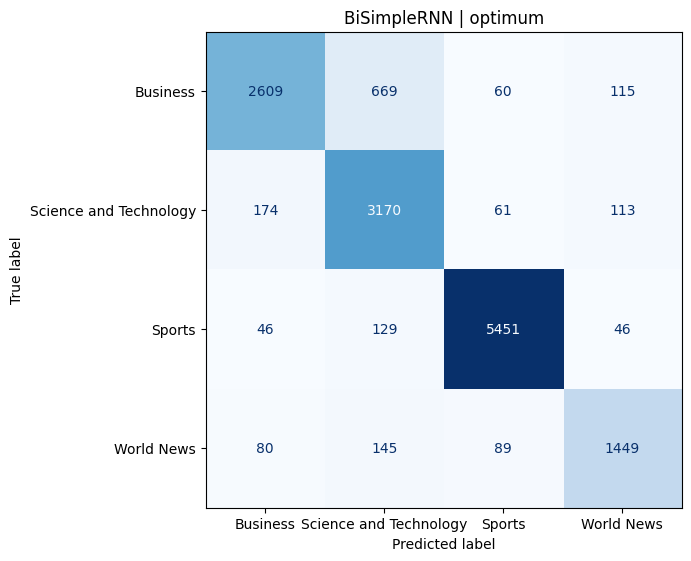

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.883659586283493, 'macro_f1': 0.8631177503524037}


,precision,recall,f1-score,support
Business,0.865732,0.804807,0.834159,3453.00000
Science and Technology,0.844246,0.832007,0.838082,3518.00000
Sports,0.939594,0.979020,0.958902,5672.00000
World News,0.808686,0.834373,0.821329,1763.00000
accuracy,0.883660,0.883660,0.883660,0.88366
macro avg,0.864564,0.862552,0.863118,14406.00000
weighted avg,0.882585,0.883660,0.882661,14406.00000


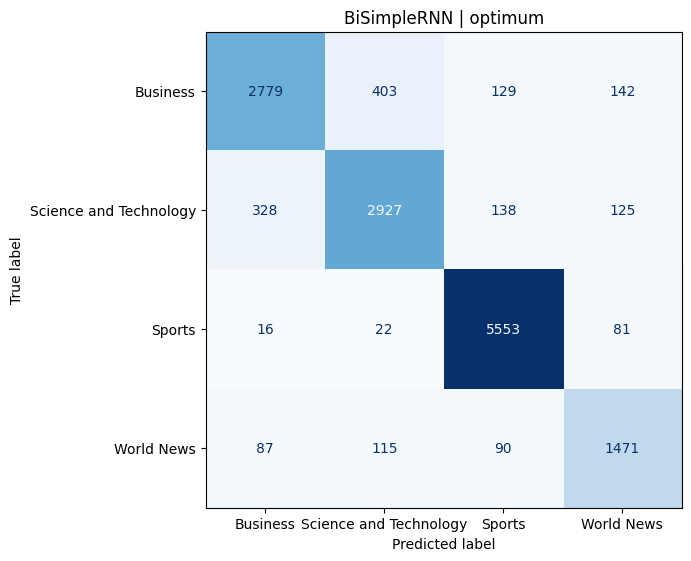

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.8923365264473136, 'macro_f1': 0.8752981930405364}


,precision,recall,f1-score,support
Business,0.867971,0.822473,0.844610,3453.000000
Science and Technology,0.848250,0.840534,0.844375,3518.000000
Sports,0.940779,0.983075,0.961462,5672.000000
World News,0.861127,0.840613,0.850746,1763.000000
accuracy,0.892337,0.892337,0.892337,0.892337
macro avg,0.879532,0.871674,0.875298,14406.000000
weighted avg,0.890984,0.892337,0.891311,14406.000000


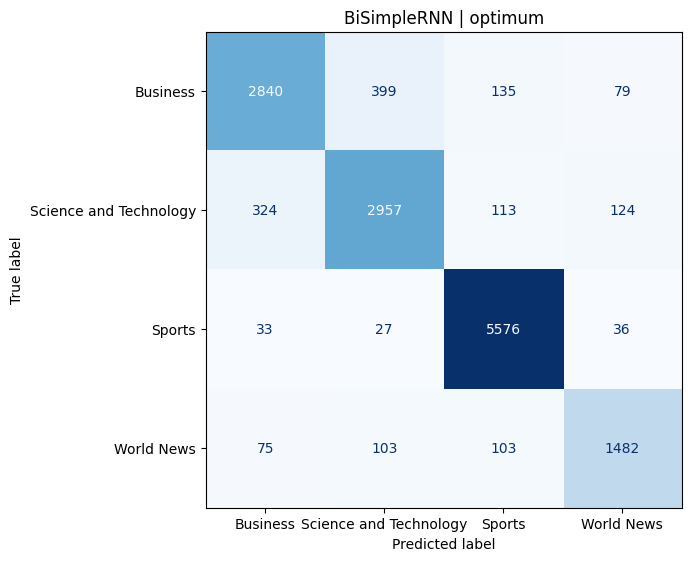

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiSimpleRNN_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.89802859919478, 'macro_f1': 0.8809268513295692}


,precision,recall,f1-score,support
Business,0.830157,0.870547,0.849873,3453.000000
Science and Technology,0.855351,0.833712,0.844393,3518.000000
Sports,0.978149,0.970733,0.974427,5672.000000
World News,0.863926,0.846285,0.855014,1763.000000
accuracy,0.898029,0.898029,0.898029,0.898029
macro avg,0.881896,0.880319,0.880927,14406.000000
weighted avg,0.898710,0.898029,0.898204,14406.000000


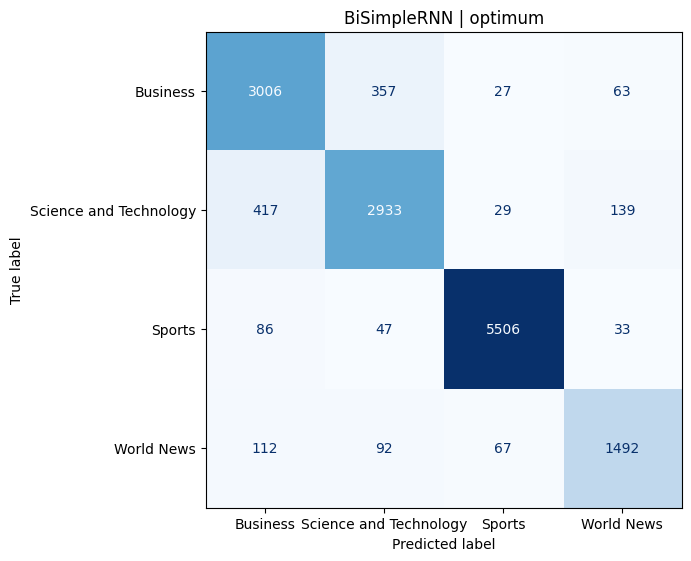

Running BiGRU on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.927391364709149, 'macro_f1': 0.9135028412045408}


,precision,recall,f1-score,support
Business,0.898753,0.876629,0.887553,3453.000000
Science and Technology,0.878897,0.905628,0.892062,3518.000000
Sports,0.982124,0.988011,0.985059,5672.000000
World News,0.903925,0.875213,0.889337,1763.000000
accuracy,0.927391,0.927391,0.927391,0.927391
macro avg,0.915925,0.911370,0.913503,14406.000000
weighted avg,0.927362,0.927391,0.927263,14406.000000


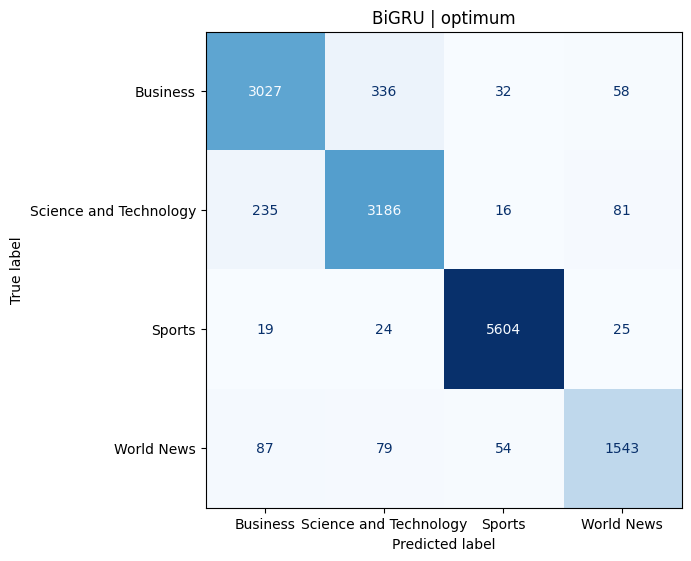

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9313480494238512, 'macro_f1': 0.917946472578528}


,precision,recall,f1-score,support
Business,0.906853,0.885317,0.895955,3453.000000
Science and Technology,0.884912,0.913587,0.899021,3518.000000
Sports,0.987261,0.983780,0.985517,5672.000000
World News,0.894346,0.888259,0.891292,1763.000000
accuracy,0.931348,0.931348,0.931348,0.931348
macro avg,0.918343,0.917736,0.917946,14406.000000
weighted avg,0.931623,0.931348,0.931396,14406.000000


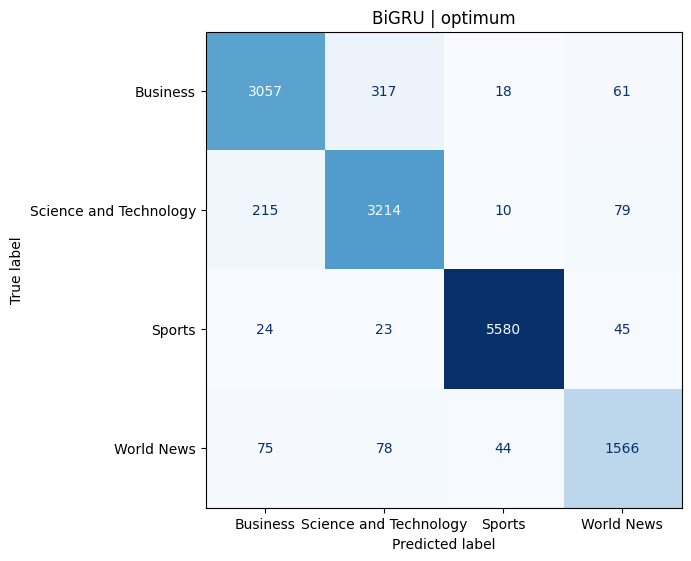

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9266277939747327, 'macro_f1': 0.9129128927142488}


,precision,recall,f1-score,support
Business,0.902690,0.865045,0.883466,3453.000000
Science and Technology,0.871634,0.911029,0.890896,3518.000000
Sports,0.983670,0.987659,0.985660,5672.000000
World News,0.901449,0.882019,0.891628,1763.000000
accuracy,0.926628,0.926628,0.926628,0.926628
macro avg,0.914861,0.911438,0.912913,14406.000000
weighted avg,0.926838,0.926628,0.926516,14406.000000


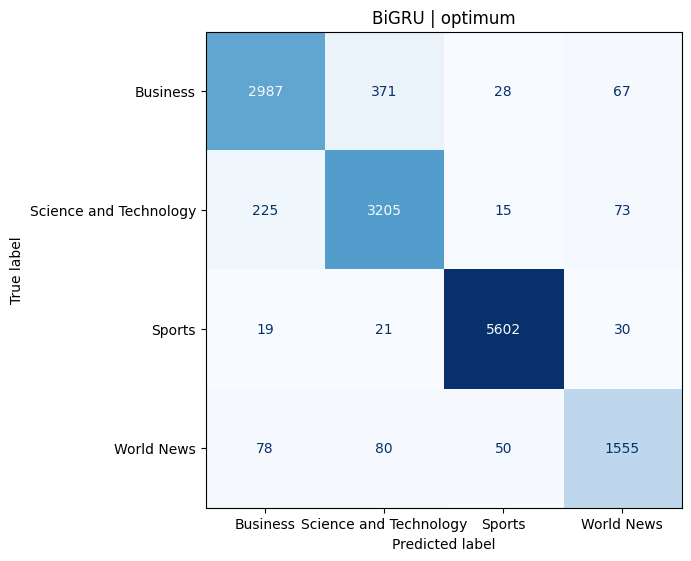

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9290573372206026, 'macro_f1': 0.915615012034303}


,precision,recall,f1-score,support
Business,0.905188,0.879235,0.892023,3453.000000
Science and Technology,0.880328,0.915861,0.897743,3518.000000
Sports,0.985141,0.981841,0.983488,5672.000000
World News,0.895342,0.883154,0.889206,1763.000000
accuracy,0.929057,0.929057,0.929057,0.929057
macro avg,0.916500,0.915023,0.915615,14406.000000
weighted avg,0.929391,0.929057,0.929087,14406.000000


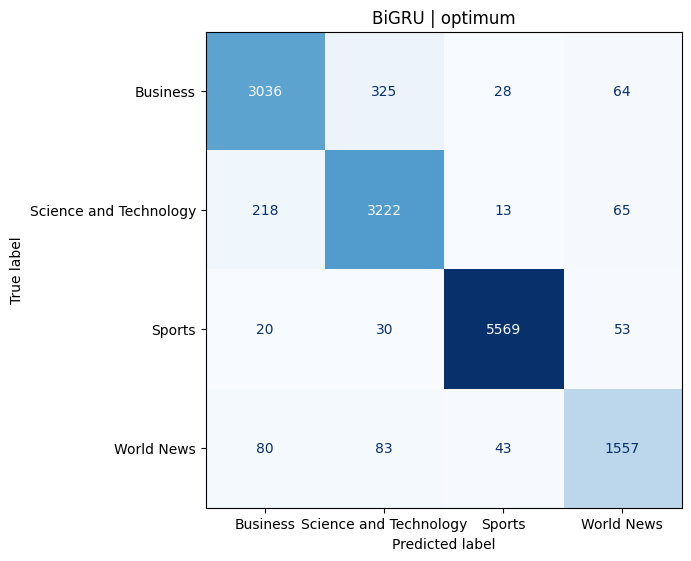

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.9206580591420241, 'macro_f1': 0.9064573812631254}


,precision,recall,f1-score,support
Business,0.889253,0.865045,0.876982,3453.000000
Science and Technology,0.868226,0.897101,0.882427,3518.000000
Sports,0.984253,0.980783,0.982515,5672.000000
World News,0.884659,0.883154,0.883906,1763.000000
accuracy,0.920658,0.920658,0.920658,0.920658
macro avg,0.906598,0.906521,0.906457,14406.000000
weighted avg,0.920960,0.920658,0.920710,14406.000000


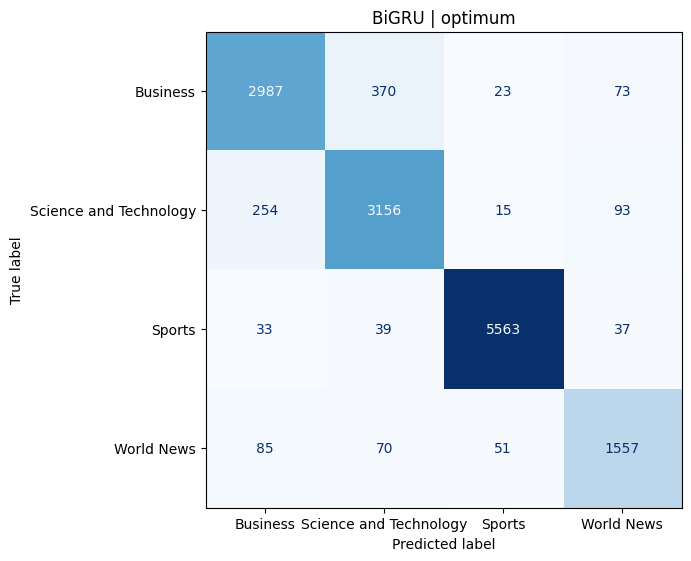

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9260030542829376, 'macro_f1': 0.9118352552496682}


,precision,recall,f1-score,support
Business,0.908007,0.860411,0.883569,3453.000000
Science and Technology,0.866273,0.916998,0.890914,3518.000000
Sports,0.982124,0.988011,0.985059,5672.000000
World News,0.903169,0.872944,0.887799,1763.000000
accuracy,0.926003,0.926003,0.926003,0.926003
macro avg,0.914893,0.909591,0.911835,14406.000000
weighted avg,0.926405,0.926003,0.925839,14406.000000


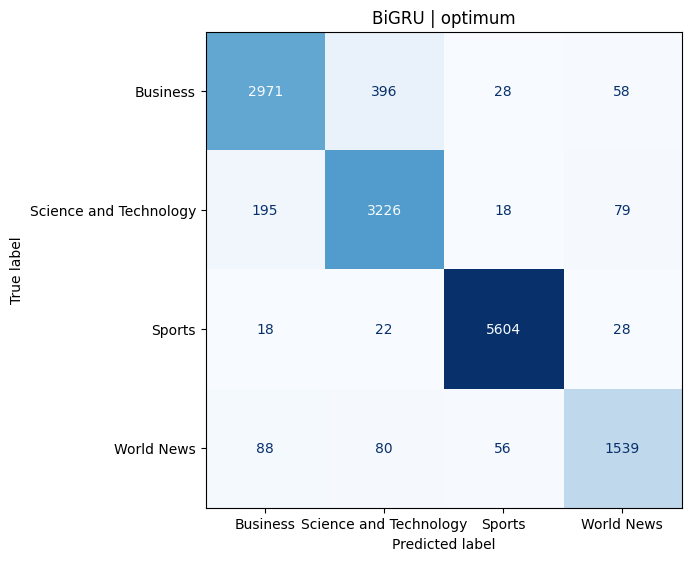

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9232958489518256, 'macro_f1': 0.9088644082839448}


,precision,recall,f1-score,support
Business,0.902350,0.856357,0.878752,3453.000000
Science and Technology,0.869565,0.903923,0.886411,3518.000000
Sports,0.982108,0.987130,0.984613,5672.000000
World News,0.883682,0.887691,0.885682,1763.000000
accuracy,0.923296,0.923296,0.923296,0.923296
macro avg,0.909426,0.908775,0.908864,14406.000000
weighted avg,0.923462,0.923296,0.923150,14406.000000


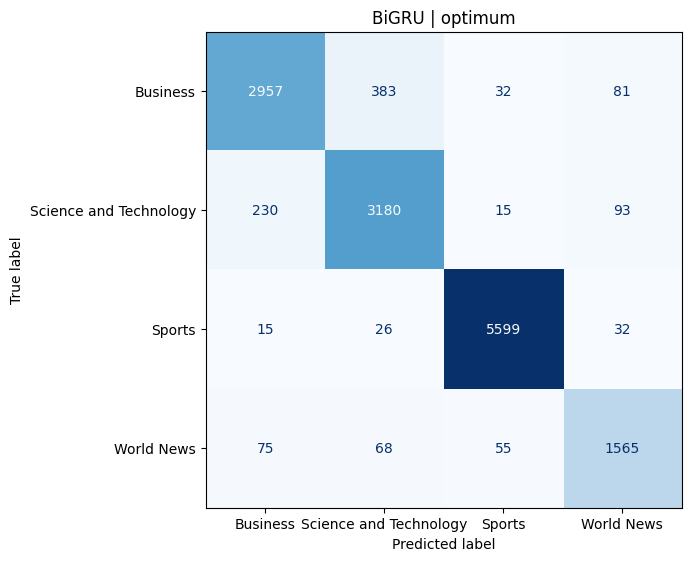

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiGRU_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.9249618214632792, 'macro_f1': 0.9112576862421069}


,precision,recall,f1-score,support
Business,0.896521,0.873154,0.884683,3453.000000
Science and Technology,0.874656,0.904491,0.889324,3518.000000
Sports,0.983931,0.982370,0.983150,5672.000000
World News,0.893226,0.882587,0.887874,1763.000000
accuracy,0.924962,0.924962,0.924962,0.924962
macro avg,0.912084,0.910650,0.911258,14406.000000
weighted avg,0.925194,0.924962,0.924976,14406.000000


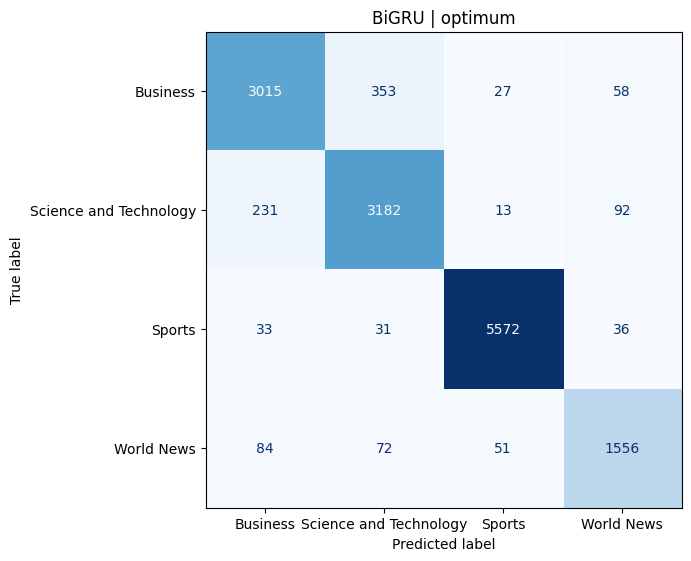

Running BiLSTM on optimum
Training with units=128, dropout_rate=0.3, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.3_bs32_ep5_seed42
{'accuracy': 0.928502013050118, 'macro_f1': 0.9147298792697259}


,precision,recall,f1-score,support
Business,0.893107,0.885607,0.889341,3453.000000
Science and Technology,0.884252,0.903354,0.893701,3518.000000
Sports,0.983497,0.987659,0.985574,5672.000000
World News,0.908983,0.872377,0.890304,1763.000000
accuracy,0.928502,0.928502,0.928502,0.928502
macro avg,0.917460,0.912249,0.914730,14406.000000
weighted avg,0.928476,0.928502,0.928413,14406.000000


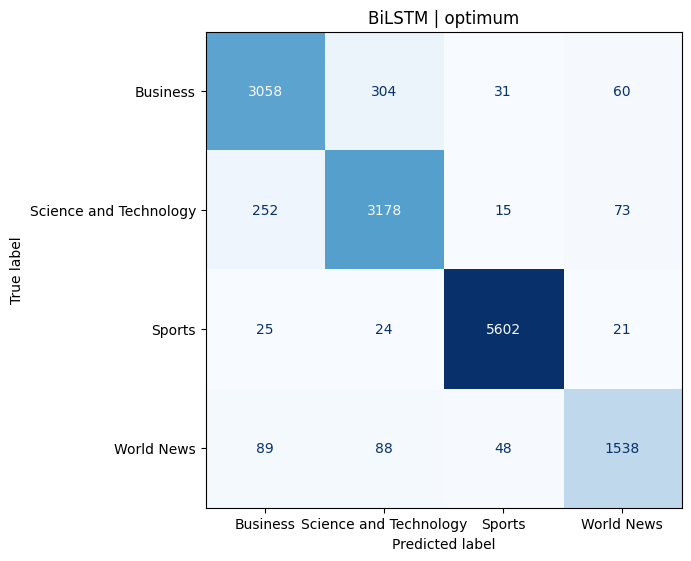

Training with units=128, dropout_rate=0.3, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.3_bs32_ep8_seed42
{'accuracy': 0.9291267527419131, 'macro_f1': 0.9149882139472345}


,precision,recall,f1-score,support
Business,0.892126,0.895743,0.893931,3453.000000
Science and Technology,0.892546,0.901933,0.897215,3518.000000
Sports,0.986197,0.982546,0.984368,5672.000000
World News,0.892095,0.876914,0.884439,1763.000000
accuracy,0.929127,0.929127,0.929127,0.929127
macro avg,0.915741,0.914284,0.914988,14406.000000
weighted avg,0.929263,0.929127,0.929179,14406.000000


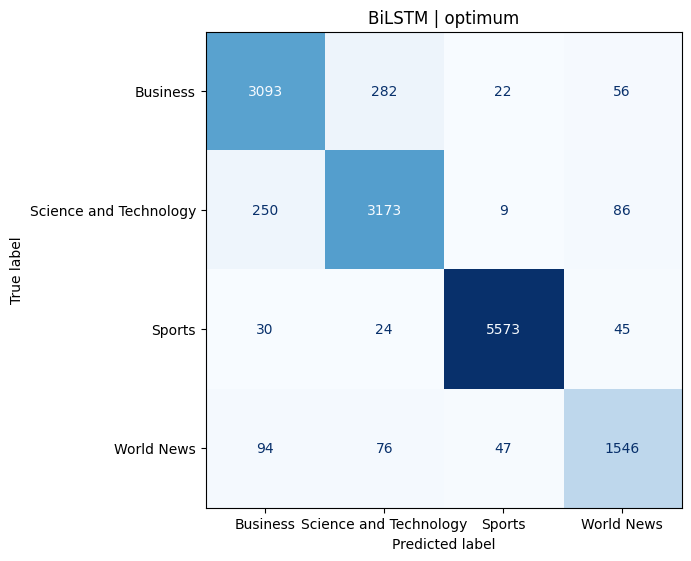

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.3_bs64_ep5_seed42
{'accuracy': 0.9278772733583229, 'macro_f1': 0.9143298272166931}


,precision,recall,f1-score,support
Business,0.886272,0.893716,0.889978,3453.000000
Science and Technology,0.892786,0.889994,0.891388,3518.000000
Sports,0.985188,0.985014,0.985101,5672.000000
World News,0.895189,0.886557,0.890852,1763.000000
accuracy,0.927877,0.927877,0.927877,0.927877
macro avg,0.914859,0.913820,0.914330,14406.000000
weighted avg,0.927900,0.927877,0.927882,14406.000000


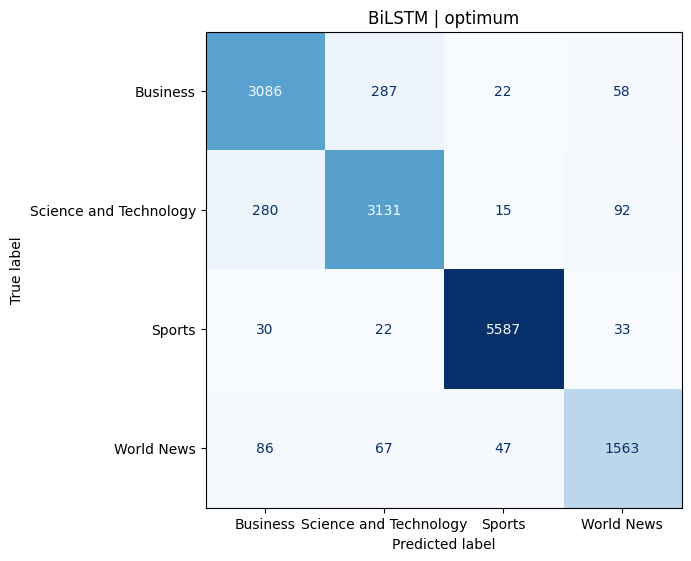

Training with units=128, dropout_rate=0.3, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.3_bs64_ep8_seed42
{'accuracy': 0.9288490906566709, 'macro_f1': 0.9150926104916496}


,precision,recall,f1-score,support
Business,0.885044,0.896322,0.890647,3453.000000
Science and Technology,0.896621,0.889994,0.893295,3518.000000
Sports,0.985558,0.986601,0.986079,5672.000000
World News,0.896492,0.884288,0.890348,1763.000000
accuracy,0.928849,0.928849,0.928849,0.928849
macro avg,0.915929,0.914301,0.915093,14406.000000
weighted avg,0.928847,0.928849,0.928831,14406.000000


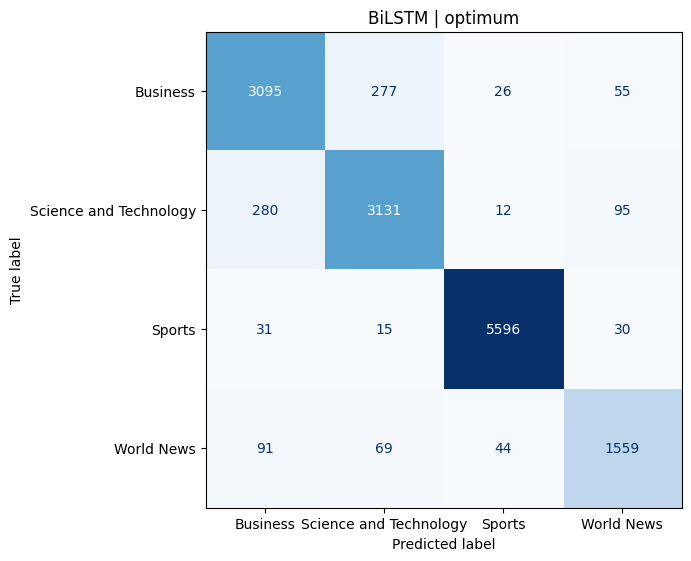

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.5_bs32_ep5_seed42
{'accuracy': 0.925794807719006, 'macro_f1': 0.9121789884009208}


,precision,recall,f1-score,support
Business,0.897299,0.875471,0.886250,3453.000000
Science and Technology,0.870063,0.907902,0.888580,3518.000000
Sports,0.985336,0.983251,0.984292,5672.000000
World News,0.904455,0.875213,0.889594,1763.000000
accuracy,0.925795,0.925795,0.925795,0.925795
macro avg,0.914288,0.910459,0.912179,14406.000000
weighted avg,0.926186,0.925795,0.925830,14406.000000


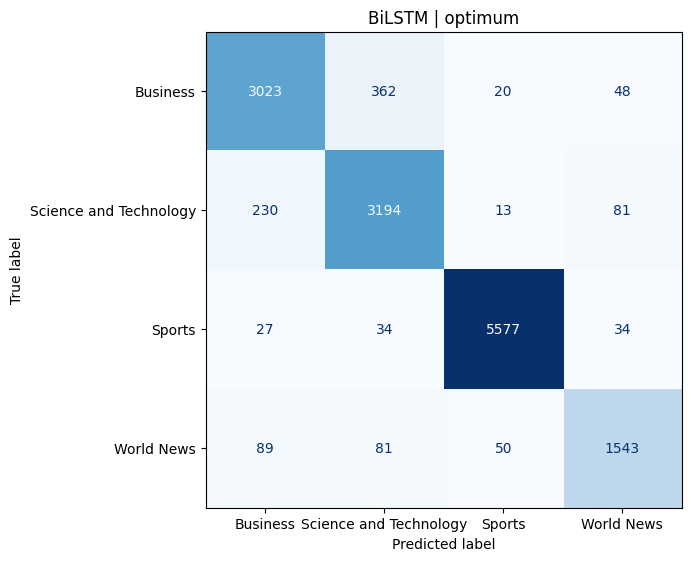

Training with units=128, dropout_rate=0.5, batch_size=32, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.5_bs32_ep8_seed42
{'accuracy': 0.9277384423157018, 'macro_f1': 0.9138463714278}


,precision,recall,f1-score,support
Business,0.897808,0.877787,0.887685,3453.000000
Science and Technology,0.877808,0.910745,0.893973,3518.000000
Sports,0.986568,0.984133,0.985349,5672.000000
World News,0.898955,0.878049,0.888379,1763.000000
accuracy,0.927738,0.927738,0.927738,0.927738
macro avg,0.915285,0.912678,0.913846,14406.000000
weighted avg,0.928011,0.927738,0.927758,14406.000000


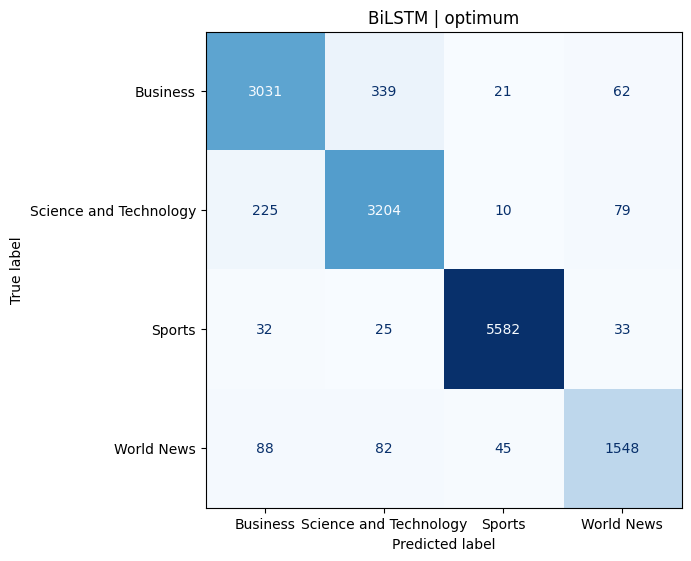

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=5
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.5_bs64_ep5_seed42
{'accuracy': 0.9254477301124532, 'macro_f1': 0.9116277213147279}


,precision,recall,f1-score,support
Business,0.899520,0.868520,0.883748,3453.000000
Science and Technology,0.869850,0.906197,0.887651,3518.000000
Sports,0.981102,0.988540,0.984807,5672.000000
World News,0.908983,0.872377,0.890304,1763.000000
accuracy,0.925448,0.925448,0.925448,0.925448
macro avg,0.914864,0.908908,0.911628,14406.000000
weighted avg,0.925554,0.925448,0.925293,14406.000000


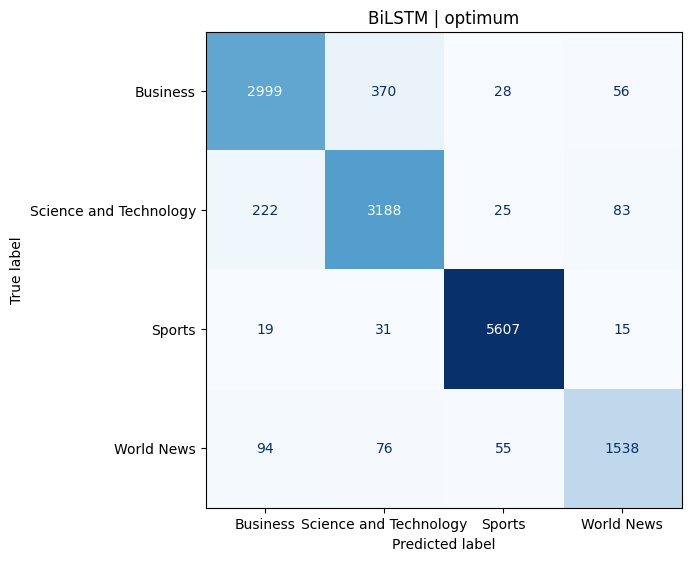

Training with units=128, dropout_rate=0.5, batch_size=64, epochs=8
Loaded saved checkpoint for SKIPGRAM_optimum_BiLSTM_u128_d0.5_bs64_ep8_seed42
{'accuracy': 0.926905456059975, 'macro_f1': 0.9132971121603349}


,precision,recall,f1-score,support
Business,0.903811,0.865334,0.884154,3453.000000
Science and Technology,0.874147,0.910176,0.891798,3518.000000
Sports,0.983488,0.987130,0.985306,5672.000000
World News,0.896789,0.887124,0.891930,1763.000000
accuracy,0.926905,0.926905,0.926905,0.926905
macro avg,0.914559,0.912441,0.913297,14406.000000
weighted avg,0.927079,0.926905,0.926798,14406.000000


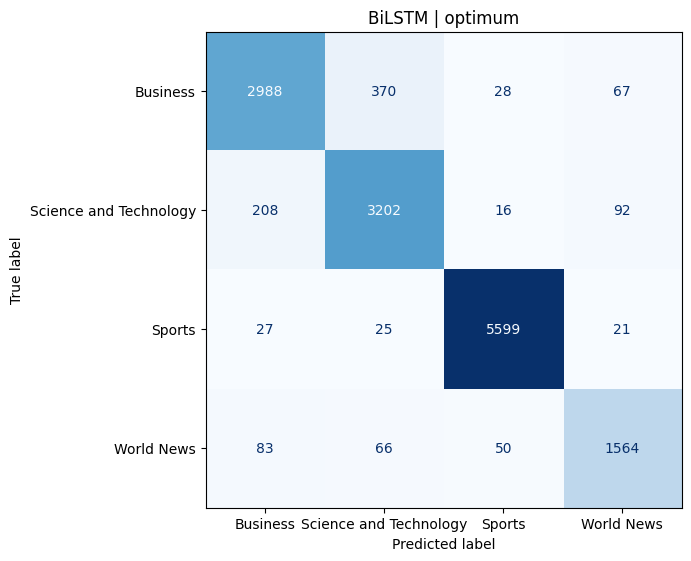

In [34]:
import itertools

hyperparameters = {
    'units': [128],
    'dropout_rate': [0.3, 0.5],
    'batch_size': [32, 64],
    'epochs': [5, 8]
}

results = []


sequence_runs_all = {}

for preprocessing_name in ["none", "extreme", "optimum"]:
    prepared_data = prepare_skipgram_inputs(
        preprocessing_name,
        train_versions[preprocessing_name],
        train_df["News Topic"],
        max_vocab=50000,
        max_len=60
    )

    for model_name in ["SimpleRNN", "GRU", "LSTM", "BiSimpleRNN", "BiGRU", "BiLSTM"]:
        print("=" * 80)
        print(f"Running {model_name} on {preprocessing_name}")
    
        for (units, dropout_rate, batch_size, epochs) in itertools.product(
            hyperparameters['units'],
            hyperparameters['dropout_rate'],
            hyperparameters['batch_size'],
            hyperparameters['epochs']
        ):

            print(f"Training with units={units}, dropout_rate={dropout_rate}, batch_size={batch_size}, epochs={epochs}")
            
            result = run_sequence_model(
                prepared_data,
                model_name=model_name,
                units=units,
                dropout_rate=dropout_rate,
                batch_size=batch_size,
                epochs=epochs
            )
            metrics = result[2]  
            
            results.append({
                'preprocessing': preprocessing_name,
                'model': model_name,
                'units': units,
                'dropout_rate': dropout_rate,
                'batch_size': batch_size,
                'epochs': epochs,
                'accuracy': metrics['accuracy'],
                'macro_f1': metrics['macro_f1']
            })
            sequence_runs_all[(preprocessing_name, model_name)] = result


In [35]:

results_df = pd.DataFrame(results)

best_result = results_df.loc[results_df['accuracy'].idxmax()] 
print("Best Hyperparameters:")
print(best_result)

results_df.to_csv("hyperparameter_tuning_results.csv", index=False)

Best Hyperparameters:
preprocessing     optimum
model                LSTM
units                 128
dropout_rate          0.3
batch_size             32
epochs                  8
accuracy         0.931556
macro_f1         0.917669
Name: 113, dtype: object


## Experiment results table

In [36]:
results_df = pd.DataFrame(EXPERIMENT_LOG)
results_df.sort_values(["representation", "macro_f1"], ascending=[True, False])

,preprocessing,representation,model,split,accuracy,macro_f1,params
128,optimum,Skip-gram,GRU,validation,0.9310,0.9183,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 64, 'epochs': 8}"
150,optimum,Skip-gram,BiGRU,validation,0.9313,0.9179,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
110,extreme,Skip-gram,BiLSTM,validation,0.9310,0.9177,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
134,optimum,Skip-gram,LSTM,validation,0.9316,0.9177,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
112,extreme,Skip-gram,BiLSTM,validation,0.9298,0.9167,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 64, 'epochs': 8}"
...,...,...,...,...,...,...,...
16,optimum,TF-IDF,LogisticRegression,validation,0.9209,0.9061,"{'C': 5.0, 'class_weight': 'balanced'}"
17,optimum,TF-IDF,LogisticRegression,validation,0.9209,0.9061,"{'C': 5.0, 'class_weight': 'balanced'}"
18,none,TF-IDF,DeepNN,validation,0.9145,0.8990,"{'n_components': 1024, 'batch_size': 256, 'epochs': 12}"
19,extreme,TF-IDF,DeepNN,validation,0.9132,0.8989,"{'n_components': 1024, 'batch_size': 256, 'epochs': 12}"


## Experiment comparison plot

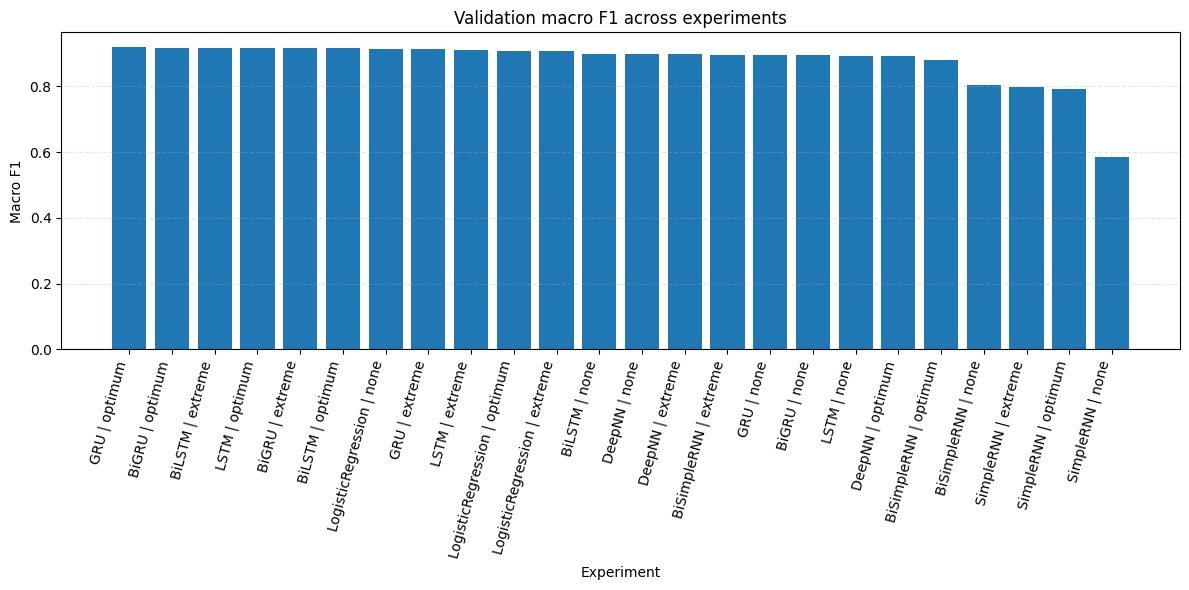

,preprocessing,representation,model,split,accuracy,macro_f1,params
128,optimum,Skip-gram,GRU,validation,0.9310,0.9183,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 64, 'epochs': 8}"
150,optimum,Skip-gram,BiGRU,validation,0.9313,0.9179,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
110,extreme,Skip-gram,BiLSTM,validation,0.9310,0.9177,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
134,optimum,Skip-gram,LSTM,validation,0.9316,0.9177,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 8}"
112,extreme,Skip-gram,BiLSTM,validation,0.9298,0.9167,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 64, 'epochs': 8}"
...,...,...,...,...,...,...,...
26,none,Skip-gram,SimpleRNN,validation,0.2442,0.0981,"{'units': 128, 'dropout_rate': 0.5, 'batch_size': 32, 'epochs': 8}"
45,none,Skip-gram,BiSimpleRNN,validation,0.1268,0.0641,"{'units': 128, 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 5}"
75,extreme,Skip-gram,SimpleRNN,validation,0.1233,0.0565,"{'units': 128, 'dropout_rate': 0.5, 'batch_size': 64, 'epochs': 5}"
52,none,Skip-gram,BiSimpleRNN,validation,0.1224,0.0545,"{'units': 128, 'dropout_rate': 0.5, 'batch_size': 64, 'epochs': 8}"


In [37]:
if len(EXPERIMENT_LOG) > 0:
    results_plot_df = pd.DataFrame(EXPERIMENT_LOG).sort_values("macro_f1", ascending=False)

    plt.figure(figsize=(12, 6))
    plt.bar(results_plot_df["model"] + " | " + results_plot_df["preprocessing"], results_plot_df["macro_f1"])
    plt.title("Validation macro F1 across experiments")
    plt.xlabel("Experiment")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=75, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

    display(results_plot_df)

## Final test evaluation helper

In [38]:


BEST_PREPROCESSING   = "optimum"         
BEST_REPRESENTATION  = "Skip-gram"         
BEST_MODEL_TYPE      = "GRU"

BEST_MODEL_PARAMS = {
    "C":            3.0,        
    "class_weight": "balanced", 
    "n_components": 1024,      
    "units":        128,        
    "dropout_rate": 0.3,        
    "batch_size":   64,
    "epochs":       8,
}

BEST_TFIDF_PARAMS = {
    "max_features": 40000,
    "ngram_range":  (1, 2),
    "min_df":       3,
    "max_df":       0.95,
}

BEST_SKIPGRAM_PARAMS = {
    "max_vocab": 50000,
    "max_len":   60,
}

In [39]:


X_train_full  = train_versions[BEST_PREPROCESSING]
X_test_final  = test_versions[BEST_PREPROCESSING]
y_train_full  = train_df[TARGET_COLUMN]
y_test_final  = test_df[TARGET_COLUMN]
y_train_full_enc = label_encoder.transform(y_train_full)

print(f"Full train size : {len(X_train_full)}")
print(f"Test size       : {len(X_test_final)}")
print(f"Representation  : {BEST_REPRESENTATION}")
print(f"Model           : {BEST_MODEL_TYPE}")

Full train size : 96646
Test size       : 12000
Representation  : Skip-gram
Model           : GRU


In [40]:


X_train_full  = train_versions[BEST_PREPROCESSING]
X_test_final  = test_versions[BEST_PREPROCESSING]
y_train_full  = train_df[TARGET_COLUMN]
y_test_final  = test_df[TARGET_COLUMN]
y_train_full_enc = label_encoder.transform(y_train_full)

print(f"Full train size : {len(X_train_full)}")
print(f"Test size       : {len(X_test_final)}")
print(f"Representation  : {BEST_REPRESENTATION}")
print(f"Model           : {BEST_MODEL_TYPE}")

Full train size : 96646
Test size       : 12000
Representation  : Skip-gram
Model           : GRU


In [41]:


if BEST_REPRESENTATION == "TF-IDF":

   
    final_vectorizer = TfidfVectorizer(
        max_features = BEST_TFIDF_PARAMS["max_features"],
        ngram_range  = BEST_TFIDF_PARAMS["ngram_range"],
        min_df       = BEST_TFIDF_PARAMS["min_df"],
        max_df       = BEST_TFIDF_PARAMS["max_df"],
        sublinear_tf = True,
    )
    X_train_tfidf_full = final_vectorizer.fit_transform(X_train_full)
    X_test_tfidf       = final_vectorizer.transform(X_test_final)

    if BEST_MODEL_TYPE == "LogisticRegression":
        final_model = LogisticRegression(
            C            = BEST_MODEL_PARAMS["C"],
            max_iter     = 1500,
            class_weight = BEST_MODEL_PARAMS["class_weight"],
        )
        final_model.fit(X_train_tfidf_full, y_train_full)
        test_pred_labels = final_model.predict(X_test_tfidf)

    elif BEST_MODEL_TYPE == "DeepNN":
        n_components = BEST_MODEL_PARAMS["n_components"]

        final_svd = TruncatedSVD(n_components=n_components, random_state=SEED)
        X_train_dense_full = final_svd.fit_transform(X_train_tfidf_full).astype("float32")
        X_test_dense       = final_svd.transform(X_test_tfidf).astype("float32")

        final_model = build_tfidf_dnn(
            input_dim  = X_train_dense_full.shape[1],
            n_classes  = len(label_encoder.classes_),
            dropout_rate = BEST_MODEL_PARAMS["dropout_rate"],
        )

        class_weights_full = compute_class_weight(
            class_weight = "balanced",
            classes      = np.unique(y_train_full_enc),
            y            = y_train_full_enc,
        )
        cw_dict_full = {i: class_weights_full[i] for i in range(len(class_weights_full))}

        final_run_name = f"FINAL_TFIDF_DNN_{BEST_PREPROCESSING}_svd{n_components}_seed{SEED}"
        final_model.fit(
            X_train_dense_full,
            y_train_full_enc,
            epochs      = BEST_MODEL_PARAMS["epochs"],
            batch_size  = BEST_MODEL_PARAMS["batch_size"],
            class_weight = cw_dict_full,
            callbacks   = build_callbacks(final_run_name, patience=4),
            verbose     = 1,
        )

        test_pred_enc    = final_model.predict(X_test_dense, verbose=0).argmax(axis=1)
        test_pred_labels = label_encoder.inverse_transform(test_pred_enc)

    else:
        raise ValueError(f"Unknown TF-IDF model type: {BEST_MODEL_TYPE}")

elif BEST_REPRESENTATION == "Skip-gram":
    max_vocab = BEST_SKIPGRAM_PARAMS["max_vocab"]
    max_len   = BEST_SKIPGRAM_PARAMS["max_len"]


    tokenized_full = tokenize_for_skipgram(X_train_full)
    final_w2v = train_skipgram_embeddings(
        tokenized_full,
        vector_size = 200,
        window      = 5,
        min_count   = 2,
        epochs      = 15,
    )

    final_tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
    final_tokenizer.fit_on_texts(X_train_full)

    X_train_seq_full = final_tokenizer.texts_to_sequences(X_train_full)
    X_test_seq       = final_tokenizer.texts_to_sequences(X_test_final)

    X_train_pad_full = pad_sequences(X_train_seq_full, maxlen=max_len, padding="post", truncating="post")
    X_test_pad       = pad_sequences(X_test_seq,       maxlen=max_len, padding="post", truncating="post")

    final_embedding_matrix = build_embedding_matrix(final_tokenizer, final_w2v, max_vocab=max_vocab)
    vocab_size = final_embedding_matrix.shape[0]

    builders = {
        "SimpleRNN":   build_simple_rnn_model,
        "GRU":         build_gru_model,
        "LSTM":        build_lstm_model,
        "BiSimpleRNN": build_bi_simple_rnn_model,
        "BiGRU":       build_bi_gru_model,
        "BiLSTM":      build_bi_lstm_model,
    }
    final_model = builders[BEST_MODEL_TYPE](
        vocab_size       = vocab_size,
        embedding_matrix = final_embedding_matrix,
        max_len          = max_len,
        n_classes        = len(label_encoder.classes_),
        units            = BEST_MODEL_PARAMS["units"],
        dropout_rate     = BEST_MODEL_PARAMS["dropout_rate"],
    )
    final_model = compile_model(final_model)

    class_weights_full = compute_class_weight(
        class_weight = "balanced",
        classes      = np.unique(y_train_full_enc),
        y            = y_train_full_enc,
    )
    cw_dict_full = {i: class_weights_full[i] for i in range(len(class_weights_full))}

    final_run_name = f"FINAL_SKIPGRAM_{BEST_MODEL_TYPE}_{BEST_PREPROCESSING}_seed{SEED}"
    final_model.fit(
        X_train_pad_full,
        y_train_full_enc,
        epochs       = BEST_MODEL_PARAMS["epochs"],
        batch_size   = BEST_MODEL_PARAMS["batch_size"],
        class_weight = cw_dict_full,
        callbacks    = build_callbacks(final_run_name, patience=4),
        verbose      = 1,
    )

    test_pred_enc    = final_model.predict(X_test_pad, verbose=0).argmax(axis=1)
    test_pred_labels = label_encoder.inverse_transform(test_pred_enc)

else:
    raise ValueError(f"Unknown representation: {BEST_REPRESENTATION}")

Epoch 1/8
1511/1511 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6452 - loss: 0.8066
Epoch 1: finished saving model to project_cache\checkpoints\FINAL_SKIPGRAM_GRU_optimum_seed42.weights.h5
1511/1511 ━━━━━━━━━━━━━━━━━━━━ 89s 54ms/step - accuracy: 0.8090 - loss: 0.5232 - learning_rate: 0.0010
Epoch 2/8
1510/1511 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9054 - loss: 0.3271
Epoch 2: finished saving model to project_cache\checkpoints\FINAL_SKIPGRAM_GRU_optimum_seed42.weights.h5
1511/1511 ━━━━━━━━━━━━━━━━━━━━ 87s 57ms/step - accuracy: 0.9082 - loss: 0.3150 - learning_rate: 0.0010
Epoch 3/8
1510/1511 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9131 - loss: 0.2987
Epoch 3: finished saving model to project_cache\checkpoints\FINAL_SKIPGRAM_GRU_optimum_seed42.weights.h5
1511/1511 ━━━━━━━━━━━━━━━━━━━━ 87s 57ms/step - accuracy: 0.9151 - loss: 0.2911 - learning_rate: 0.0010
Epoch 4/8
1510/1511 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9179 - loss: 0.2797
Epoch 4: finished saving

In [42]:

test_metrics, test_report_df = evaluate_predictions(
    y_test_final,
    test_pred_labels,
    label_encoder.classes_,
)

print("=" * 60)
print("FINAL TEST SET RESULTS")
print(f"  Model          : {BEST_MODEL_TYPE}")
print(f"  Representation : {BEST_REPRESENTATION}")
print(f"  Preprocessing  : {BEST_PREPROCESSING}")
print("=" * 60)
print(f"  Accuracy  : {test_metrics['accuracy']:.4f}")
print(f"  Macro F1  : {test_metrics['macro_f1']:.4f}")
print("=" * 60)

display(test_report_df.round(4))

FINAL TEST SET RESULTS
  Model          : GRU
  Representation : Skip-gram
  Preprocessing  : optimum
  Accuracy  : 0.9212
  Macro F1  : 0.9211


,precision,recall,f1-score,support
Business,0.8818,0.8950,0.8883,3000.0000
Science and Technology,0.8873,0.9187,0.9027,3000.0000
Sports,0.9629,0.9867,0.9746,3000.0000
World News,0.9560,0.8843,0.9188,3000.0000
accuracy,0.9212,0.9212,0.9212,0.9212
macro avg,0.9220,0.9212,0.9211,12000.0000
weighted avg,0.9220,0.9212,0.9211,12000.0000


In [43]:


log_df = pd.DataFrame(EXPERIMENT_LOG)

val_row = log_df[
    (log_df["preprocessing"]  == BEST_PREPROCESSING) &
    (log_df["representation"] == BEST_REPRESENTATION) &
    (log_df["model"]          == BEST_MODEL_TYPE) &
    (log_df["split"]          == "validation")
]

print("\nValidation performance (best run during tuning):")
if not val_row.empty:
    display(val_row[["preprocessing", "representation", "model",
                      "accuracy", "macro_f1"]].tail(1))
else:
    print("  (no matching validation log entry found)")

print("\nTest performance:")
print(pd.DataFrame([{
    "preprocessing":  BEST_PREPROCESSING,
    "representation": BEST_REPRESENTATION,
    "model":          BEST_MODEL_TYPE,
    "accuracy":       round(test_metrics["accuracy"], 4),
    "macro_f1":       round(test_metrics["macro_f1"], 4),
    "split":          "test",
}]))


Validation performance (best run during tuning):


,preprocessing,representation,model,accuracy,macro_f1
132,optimum,Skip-gram,GRU,0.9239,0.9098



Test performance:
  preprocessing representation model  accuracy  macro_f1 split
0       optimum      Skip-gram   GRU    0.9212    0.9211  test
